# Predicting Customer Churn in Wireless Telecommunications Using Machine Learning

## IT5022 - Fundamentals of Machine Learning - Assignment - MS26935140 | MS26923260

### Problem Statement
Customer churn is an important challenge for wireless telecommunications service providers because customers who discontinue their service can reduce recurring revenue and increase customer acquisition requirements. Identifying customers who are at elevated risk of leaving before churn occurs can support more targeted customer-retention strategies. This project investigates whether historical customer account characteristics, service-usage behaviour, billing information, equipment information, service interactions, and demographic characteristics can be used to predict whether a customer is likely to churn in a future period using supervised machine-learning techniques.



*   **Machine Learning Approach :** Supervised Learning – Binary Classification
*   **Dataset :** Cell2Cell telecom churn
*   **Target :** `Churn` (`Yes` = churn, `No` = non-churn)
*   **Development Platform :** Jupyter Notebook
*   **Programming Language :** Python

## 0. Imports, Environment and reproducibility

This section imports the core libraries used throughout the notebook and sets the display options for tables. A single random seed (`RANDOM_STATE = 42`) is defined here and reused for every data split, cross-validation fold and model, so that the results are identical each time the notebook is run. The exact package versions are pinned in `docs/requirements.txt`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setting random seed for Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings - columns -> no limit | rows -> upto 200
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

print("Environment is Ready")

Environment is Ready


## 1. Load the labelled training data and unlabeled holdout data

The labelled file (`cell2celltrain.csv`) and the unlabelled holdout file (`cell2cellholdout.csv`) are read from the repository's `data` folder. The cell first checks that both files exist and stops with a clear error message if either one is missing, rather than failing later with a less helpful message. `DATA_DIR` only needs to be changed if the files are stored in a different location.

In [2]:
# Assume dataset files are in the data folder

# Change the DATA_DIR only if files are in a different folder
DATA_DIR = Path("../data")

train_path = DATA_DIR / "cell2celltrain.csv"
holdout_path = DATA_DIR / "cell2cellholdout.csv"

# Check that both required files are exists
missing_files = [
    path for path in [train_path, holdout_path]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required dataset file(s) were not found \n"
        + "\n". join(str(path) for path in missing_files)
    )

# Load datasets
train_raw = pd.read_csv(train_path)
holdout_raw = pd.read_csv(holdout_path)

## 2. Dataset integrity audit

The purpose of Data Integrity Audit is to **inspect and diagnose the raw data only**. No imputation, encoding, scaling, outlier removal, feature engineering, feature selection, class-imbalance treatment, or model fitting is performed here.

The audit focuses on understanding the dataset structure and identifying data-quality or representation issues that may need to be addressed in later stages.

### 2.1 Dataset Source and Context

This project uses the publicly available **Cell2Cell** customer churn dataset. It describes customers of a US wireless carrier through usage and billing summaries, equipment details, customer-care and retention contacts, credit rating and household characteristics. The data was originally released by the Teradata Center for Customer Relationship Management at Duke University for a churn-modelling tournament (Neslin et al., 2006). According to its documentation, a customer is labelled as churned if they left **31–60 days after the observation date**, and most usage variables are averages over the **four months before that date**.

The Kaggle release provides two files:

- `cell2celltrain.csv`: customers with a known churn outcome. This is the **labelled dataset** used for training and evaluation.
- `cell2cellholdout.csv`: further customers whose `Churn` value is blank. Because the outcome is unknown, this file cannot be used to measure performance; it is used only to demonstrate predictions for new customers (Section 15).

**Source and citation**

- **Dataset:** *telecom churn (cell2cell)*, published on Kaggle by user `jpacse`, version 2 (14 December 2018). Available at: https://www.kaggle.com/datasets/jpacse/datasets-for-churn-telecom
- **Original data provider:** Teradata Center for Customer Relationship Management, Fuqua School of Business, Duke University (as credited on the Kaggle dataset page).
- **Variable documentation:** *Cell2Cell: The Churn Game – Database Documentation*, Teradata Center for Customer Relationship Management, Duke University. The Kaggle page does not include it; a copy is available at: https://github.com/leylatulu/Telecom-Churn-Analysis/blob/main/Cell2Cell-Data-Documentation.pdf
- **Background reference:** Neslin, S. A., Gupta, S., Kamakura, W., Lu, J. and Mason, C. H. (2006). Defection detection: Measuring and understanding the predictive accuracy of customer churn models. *Journal of Marketing Research*, 43(2), 204–211.

### 2.2 Dataset Shape and Structure

In [3]:
# Dataset dimensions
print("Labelled dataset shape:", train_raw.shape)
print("Holdout dataset shape:", holdout_raw.shape)

# Verify schema
print("\nNumber of columns in labelled data:", train_raw.shape[1])
print("Number of columns in holdout data:", holdout_raw.shape[1])
print(
    "Same column names and order:",
    train_raw.columns.tolist() == holdout_raw.columns.tolist()
)

Labelled dataset shape: (51047, 58)
Holdout dataset shape: (20000, 58)

Number of columns in labelled data: 58
Number of columns in holdout data: 58
Same column names and order: True


The labelled file contains **51,047 customers and 58 columns**, and the holdout file contains **20,000 customers with exactly the same 58 columns in the same order**. Because the two schemas match, a pipeline trained on the labelled data can later be applied directly to the holdout file without any column mapping.

### 2.3 Feature and Target Overview

The first rows of both files give an initial view of the data. The columns include numerical usage and billing measures, Yes/No flags, text categories and the `Churn` target. The holdout preview confirms that `Churn` is empty in that file.

In [4]:
# Preview both datasets
display(train_raw.head())
display(holdout_raw.head())

# Basic feature/target overview
print("\nNumber of variables:", train_raw.shape[1])
print("Target variable: Churn")
print("Target values:", train_raw["Churn"].dropna().unique())
print("\nUnique CustomerID values:", train_raw["CustomerID"].nunique())

# Display all column names
train_raw.columns.tolist()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000006,NaN,57.49,483.0,37.0,0.25,23.0,0.0,532.0,51.0,8.3,1.0,61.3,1.7,0.3,55.3,46.3,6.3,83.7,157.0,9.3,0.0,5.7,56,1,1,MILMIL414,7,6,240,30.0,0.0,No,No,Yes,Yes,Yes,Unknown,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,5,No,1,150,No,5-Low,Other,Other,No
1,3000018,NaN,55.23,570.0,72.0,0.00,0.0,0.0,38.0,0.0,9.7,0.7,77.0,8.7,0.0,106.3,14.7,0.7,97.3,90.3,10.3,0.0,0.0,57,1,1,NNYSYR315,6,4,434,56.0,0.0,No,No,Yes,No,No,Known,No,No,No,No,Yes,Yes,0,0,Yes,No,0,6,No,2,80,No,1-Highest,Other,Professional,No
2,3000034,NaN,97.34,1039.0,50.0,4.95,420.0,0.0,198.0,23.3,12.7,3.0,176.0,11.3,0.3,213.9,103.3,0.3,238.3,192.3,15.7,0.0,4.0,55,1,1,MILMIL414,3,3,700,38.0,24.0,No,No,No,No,No,Unknown,No,No,No,No,No,No,0,0,Yes,No,0,4,No,3,10,No,3-Good,Suburban,Crafts,Yes
3,3000070,NaN,35.59,153.0,30.0,0.00,16.0,0.0,30.0,7.3,2.0,0.7,17.3,0.0,0.0,33.1,8.0,4.7,48.3,7.0,2.7,0.0,0.3,59,3,2,SLCSLC801,6,5,48,46.0,0.0,Yes,No,Yes,Yes,Yes,Known,Yes,Yes,Yes,No,No,Yes,0,0,No,Yes,0,4,No,1,200,No,1-Highest,Other,Other,No
4,3000074,NaN,55.27,1213.0,50.0,0.74,0.0,1.3,169.0,1.0,2.7,6.0,43.7,4.3,0.0,490.1,50.7,8.3,189.3,105.0,8.7,0.0,4.3,52,1,1,OKCTUL918,4,4,408,58.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,3,No,0,10,No,1-Highest,Suburban,Other,No



Number of variables: 58
Target variable: Churn
Target values: ['Yes' 'No']

Unique CustomerID values: 51047


['CustomerID',
 'Churn',
 'MonthlyRevenue',
 'MonthlyMinutes',
 'TotalRecurringCharge',
 'DirectorAssistedCalls',
 'OverageMinutes',
 'RoamingCalls',
 'PercChangeMinutes',
 'PercChangeRevenues',
 'DroppedCalls',
 'BlockedCalls',
 'UnansweredCalls',
 'CustomerCareCalls',
 'ThreewayCalls',
 'ReceivedCalls',
 'OutboundCalls',
 'InboundCalls',
 'PeakCallsInOut',
 'OffPeakCallsInOut',
 'DroppedBlockedCalls',
 'CallForwardingCalls',
 'CallWaitingCalls',
 'MonthsInService',
 'UniqueSubs',
 'ActiveSubs',
 'ServiceArea',
 'Handsets',
 'HandsetModels',
 'CurrentEquipmentDays',
 'AgeHH1',
 'AgeHH2',
 'ChildrenInHH',
 'HandsetRefurbished',
 'HandsetWebCapable',
 'TruckOwner',
 'RVOwner',
 'Homeownership',
 'BuysViaMailOrder',
 'RespondsToMailOffers',
 'OptOutMailings',
 'NonUSTravel',
 'OwnsComputer',
 'HasCreditCard',
 'RetentionCalls',
 'RetentionOffersAccepted',
 'NewCellphoneUser',
 'NotNewCellphoneUser',
 'ReferralsMadeBySubscriber',
 'IncomeGroup',
 'OwnsMotorcycle',
 'AdjustmentsToCreditRat

### 2.4 Data-Type and Semantic-Type Audit

The pandas data type of a column does not always match what the column represents: a numeric quantity may be stored as text, and a category may be stored as a number. The stored type and the number of distinct values are therefore listed for every column, so that each feature can later be handled according to its meaning rather than its storage type.

In [5]:
# General dataframe information
train_raw.info()

# Data-type/cardinality summary
dtype_summary = pd.DataFrame({
    "Pandas_Type": train_raw.dtypes.astype(str),
    "Unique_Values": train_raw.nunique(dropna=True)
})

display(dtype_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

,Pandas_Type,Unique_Values
CustomerID,int64,51047
Churn,object,2
MonthlyRevenue,float64,12665
MonthlyMinutes,float64,2719
TotalRecurringCharge,float64,214
DirectorAssistedCalls,float64,146
OverageMinutes,float64,746
RoamingCalls,float64,530
PercChangeMinutes,float64,2262
PercChangeRevenues,float64,2899


**Feature dictionary.** The table below describes the meaning of each of the 58 columns, grouped by domain (billing, usage, call quality, equipment, household and so on), together with its semantic type. The meanings follow the Cell2Cell database documentation. Where the documentation does not state exactly how a value was measured, for example the time window behind the two percentage-change fields, this is noted in the table.

In [6]:
feature_descriptions = [
    ('CustomerID', 'Identifier', 'Unique customer record identifier', 'Identifier'),
    ('Churn', 'Target', 'Observed customer churn outcome (Yes/No)', 'Binary target'),
    ('MonthlyRevenue', 'Billing', 'Recorded monthly customer revenue', 'Numerical measure'),
    ('MonthlyMinutes', 'Usage', 'Recorded monthly call minutes', 'Numerical measure'),
    ('TotalRecurringCharge', 'Billing', 'Total recurring account charge', 'Numerical measure'),
    ('DirectorAssistedCalls', 'Usage', 'Recorded directory-assisted call activity', 'Numerical measure'),
    ('OverageMinutes', 'Usage', 'Recorded minutes exceeding a plan allowance', 'Numerical measure'),
    ('RoamingCalls', 'Usage', 'Recorded roaming-call activity', 'Numerical measure'),
    ('PercChangeMinutes', 'Usage', 'Recorded change measure for minutes; exact unit not verified', 'Numerical measure'),
    ('PercChangeRevenues', 'Billing', 'Recorded change measure for revenue; exact unit not verified', 'Numerical measure'),
    ('DroppedCalls', 'Call quality', 'Recorded dropped-call activity', 'Numerical measure'),
    ('BlockedCalls', 'Call quality', 'Recorded blocked-call activity', 'Numerical measure'),
    ('UnansweredCalls', 'Usage', 'Recorded unanswered-call activity', 'Numerical measure'),
    ('CustomerCareCalls', 'Service', 'Recorded customer-care call activity', 'Numerical measure'),
    ('ThreewayCalls', 'Usage', 'Recorded three-way call activity', 'Numerical measure'),
    ('ReceivedCalls', 'Usage', 'Recorded received-call activity', 'Numerical measure'),
    ('OutboundCalls', 'Usage', 'Recorded outbound-call activity', 'Numerical measure'),
    ('InboundCalls', 'Usage', 'Recorded inbound-call activity', 'Numerical measure'),
    ('PeakCallsInOut', 'Usage', 'Recorded peak-period inbound/outbound call activity', 'Numerical measure'),
    ('OffPeakCallsInOut', 'Usage', 'Recorded off-peak inbound/outbound call activity', 'Numerical measure'),
    ('DroppedBlockedCalls', 'Call quality', 'Recorded combined dropped/blocked call activity', 'Numerical measure'),
    ('CallForwardingCalls', 'Usage', 'Recorded call-forwarding activity', 'Numerical measure'),
    ('CallWaitingCalls', 'Usage', 'Recorded call-waiting activity', 'Numerical measure'),
    ('MonthsInService', 'Tenure', 'Recorded months of customer service', 'Numerical count'),
    ('UniqueSubs', 'Subscriptions', 'Number of unique subscriptions', 'Numerical count'),
    ('ActiveSubs', 'Subscriptions', 'Number of active subscriptions', 'Numerical count'),
    ('ServiceArea', 'Geography', 'Coded customer service area', 'Nominal categorical'),
    ('Handsets', 'Equipment', 'Recorded number of handsets', 'Numerical count'),
    ('HandsetModels', 'Equipment', 'Recorded number of handset models', 'Numerical count'),
    ('CurrentEquipmentDays', 'Equipment', 'Recorded days associated with current equipment', 'Numerical measure'),
    ('AgeHH1', 'Household', 'Recorded age for household member 1; zero coding unverified', 'Numerical measure'),
    ('AgeHH2', 'Household', 'Recorded age for household member 2; zero coding unverified', 'Numerical measure'),
    ('ChildrenInHH', 'Household', 'Indicator for children in household', 'Binary categorical'),
    ('HandsetRefurbished', 'Equipment', 'Indicator for refurbished handset', 'Binary categorical'),
    ('HandsetWebCapable', 'Equipment', 'Indicator for web-capable handset', 'Binary categorical'),
    ('TruckOwner', 'Household', 'Indicator for truck ownership', 'Binary categorical'),
    ('RVOwner', 'Household', 'Indicator for recreational-vehicle ownership', 'Binary categorical'),
    ('Homeownership', 'Household', 'Whether homeownership information is Known/Unknown; not a Yes/No ownership flag', 'Nominal categorical'),
    ('BuysViaMailOrder', 'Marketing', 'Indicator for mail-order purchasing', 'Binary categorical'),
    ('RespondsToMailOffers', 'Marketing', 'Indicator for responding to mail offers', 'Binary categorical'),
    ('OptOutMailings', 'Marketing', 'Indicator for opting out of mailings', 'Binary categorical'),
    ('NonUSTravel', 'Household', 'Indicator for non-US travel', 'Binary categorical'),
    ('OwnsComputer', 'Household', 'Indicator for computer ownership', 'Binary categorical'),
    ('HasCreditCard', 'Household', 'Indicator for credit-card possession', 'Binary categorical'),
    ('RetentionCalls', 'Retention', 'Recorded count of retention-related calls', 'Numerical count'),
    ('RetentionOffersAccepted', 'Retention', 'Recorded count of accepted retention offers', 'Numerical count'),
    ('NewCellphoneUser', 'Customer profile', 'Indicator for new cellphone user', 'Binary categorical'),
    ('NotNewCellphoneUser', 'Customer profile', 'Indicator for not-new cellphone user', 'Binary categorical'),
    ('ReferralsMadeBySubscriber', 'Customer profile', 'Recorded count of referrals made by subscriber', 'Numerical count'),
    ('IncomeGroup', 'Household', 'Coded income group; exact mapping and ordering not verified', 'Coded categorical'),
    ('OwnsMotorcycle', 'Household', 'Indicator for motorcycle ownership', 'Binary categorical'),
    ('AdjustmentsToCreditRating', 'Credit', 'Recorded count/code of credit-rating adjustments; exact meaning unverified', 'Numerical code/count'),
    ('HandsetPrice', 'Equipment', 'Recorded handset price or explicit Unknown value', 'Numerical-like, stored as text'),
    ('MadeCallToRetentionTeam', 'Retention', 'Indicator for contact with retention team', 'Binary categorical'),
    ('CreditRating', 'Credit', 'Ordered credit rating labels from Highest to Lowest', 'Ordinal categorical'),
    ('PrizmCode', 'Demographics', 'Categorical area/demographic segment code', 'Nominal categorical'),
    ('Occupation', 'Demographics', 'Recorded occupation category', 'Nominal categorical'),
    ('MaritalStatus', 'Household', 'Recorded marital-status response (Yes/No/Unknown)', 'Nominal categorical'),

]

feature_dictionary = pd.DataFrame(
    feature_descriptions,
    columns=["Feature", "Domain", "Meaning", "Semantic_Type"]
)
feature_dictionary["Pandas_Type"] = feature_dictionary["Feature"].map(
    train_raw.dtypes.astype(str).to_dict()
)

# Verify that all original columns are documented exactly once.
assert len(feature_dictionary) == train_raw.shape[1]
assert set(feature_dictionary["Feature"]) == set(train_raw.columns)

display(feature_dictionary)

,Feature,Domain,Meaning,Semantic_Type,Pandas_Type
0,CustomerID,Identifier,Unique customer record identifier,Identifier,int64
1,Churn,Target,Observed customer churn outcome (Yes/No),Binary target,object
2,MonthlyRevenue,Billing,Recorded monthly customer revenue,Numerical measure,float64
3,MonthlyMinutes,Usage,Recorded monthly call minutes,Numerical measure,float64
4,TotalRecurringCharge,Billing,Total recurring account charge,Numerical measure,float64
5,DirectorAssistedCalls,Usage,Recorded directory-assisted call activity,Numerical measure,float64
6,OverageMinutes,Usage,Recorded minutes exceeding a plan allowance,Numerical measure,float64
7,RoamingCalls,Usage,Recorded roaming-call activity,Numerical measure,float64
8,PercChangeMinutes,Usage,Recorded change measure for minutes; exact uni...,Numerical measure,float64
9,PercChangeRevenues,Billing,Recorded change measure for revenue; exact uni...,Numerical measure,float64


### 2.5 Missing-Value and Missing-Representation

Missing information appears in two forms in this dataset: true nulls (`NaN`) and explicit text values such as `Unknown`. The two forms are counted separately because they can mean different things. A blank is usually a recording gap, whereas `Unknown` is a value that the data provider chose to record, and it may describe a real group of customers.

In [7]:
# Complete audit table
audit_table = pd.DataFrame({
    "Data_Type": train_raw.dtypes.astype(str),
    "Missing_Count": train_raw.isna().sum(),
    "Missing_Percentage": (train_raw.isna().mean() * 100).round(2),
    "Unique_Values": train_raw.nunique(dropna=True)
})

audit_table = audit_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(audit_table)

# Show only columns containing actual null values
missing_summary = audit_table[
    audit_table["Missing_Count"] > 0
][["Missing_Count", "Missing_Percentage"]]

display(missing_summary)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
AgeHH2,float64,909,1.78,43
AgeHH1,float64,909,1.78,43
PercChangeMinutes,float64,367,0.72,2262
PercChangeRevenues,float64,367,0.72,2899
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719
TotalRecurringCharge,float64,156,0.31,214
DirectorAssistedCalls,float64,156,0.31,146
OverageMinutes,float64,156,0.31,746
RoamingCalls,float64,156,0.31,530


,Missing_Count,Missing_Percentage
AgeHH2,909,1.78
AgeHH1,909,1.78
PercChangeMinutes,367,0.72
PercChangeRevenues,367,0.72
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31
TotalRecurringCharge,156,0.31
DirectorAssistedCalls,156,0.31
OverageMinutes,156,0.31
RoamingCalls,156,0.31


In [8]:
# Audit explicit 'Unknown' representations in text columns
unknown_summary = []

for col in train_raw.select_dtypes(include="object").columns:
    unknown_count = (
        train_raw[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    if unknown_count > 0:
        unknown_summary.append({
            "Feature": col,
            "Unknown_Count": int(unknown_count),
            "Unknown_Percentage": round(
                unknown_count / len(train_raw) * 100, 2
            )
        })

unknown_summary = pd.DataFrame(unknown_summary)
display(unknown_summary)

,Feature,Unknown_Count,Unknown_Percentage
0,Homeownership,17060,33.42
1,HandsetPrice,28982,56.78
2,MaritalStatus,19700,38.59


Fourteen columns contain true nulls, all at low rates: at most **1.78%** (the two household-age fields). The billing and usage fields are missing together for the same 156 customers, and the two percentage-change fields for the same 367. Explicit `Unknown` values are much more common: **56.78%** of `HandsetPrice`, **38.59%** of `MaritalStatus` and **33.42%** of `Homeownership`. Because `Unknown` in `HandsetPrice` stands in for a missing number, whereas in `MaritalStatus` and `Homeownership` it is a recorded category, theese cases are treated in preprocessing.


### 2.6 Duplicate and Identifier Integrity

In [9]:
# Duplicate analysis
duplicate_rows = train_raw.duplicated().sum()
duplicate_customer_ids = train_raw["CustomerID"].duplicated().sum()

print("Complete duplicate rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_customer_ids)
print("Number of rows:", len(train_raw))
print("Unique CustomerID values:", train_raw["CustomerID"].nunique())

Complete duplicate rows: 0
Duplicate CustomerID values: 0
Number of rows: 51047
Unique CustomerID values: 51047


Overlap between the two files is also checked. A customer who appears in both the labelled and the holdout file would mean that the holdout is not genuinely new data.

In [10]:
# Check for overlapping customer identifiers across the two raw files.
overlapping_ids = set(train_raw["CustomerID"]) & set(holdout_raw["CustomerID"])
print("Overlapping CustomerIDs between labelled and holdout:", len(overlapping_ids))

Overlapping CustomerIDs between labelled and holdout: 0


No complete duplicate records are present in the labelled dataset, and every `CustomerID` is unique. Therefore, the raw data shows no evidence of exact duplicated customer observations. `CustomerID` is confirmed to behave as a record identifier.

The labelled and holdout files also contain **no overlapping customer identifiers**, indicating that the supplied source files contain distinct customer IDs.

### 2.7 Categorical Cardinality and Consistency

Categorical variables are inspected for:

- the number of distinct categories;
- high-cardinality variables;
- explicit missing/unknown categories;
- obvious differences caused only by capitalisation or surrounding spaces.

This is a diagnostic check only; no categories are encoded, grouped or replaced here.

In [11]:
# Identify object/categorical columns
categorical_cols = train_raw.select_dtypes(
    include="object"
).columns.tolist()

categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Values_Including_Missing": [
        train_raw[col].nunique(dropna=False)
        for col in categorical_cols
    ]
}).sort_values(
    "Unique_Values_Including_Missing",
    ascending=False
)

display(categorical_summary)

,Feature,Unique_Values_Including_Missing
1,ServiceArea,748
17,HandsetPrice,16
21,Occupation,8
19,CreditRating,7
20,PrizmCode,4
22,MaritalStatus,3
12,OwnsComputer,2
18,MadeCallToRetentionTeam,2
16,OwnsMotorcycle,2
15,NotNewCellphoneUser,2


In [12]:
# Inspect actual category frequencies
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(train_raw[col].value_counts(dropna=False))


--- Churn ---
Churn
No     36336
Yes    14711
Name: count, dtype: int64

--- ServiceArea ---
ServiceArea
NYCBRO917    1684
HOUHOU281    1510
DALDAL214    1498
NYCMAN917    1182
APCFCH703     783
             ... 
OHIRAV330       1
KCYHES316       1
AIRGEO843       1
AIRNEW803       1
NCRDNN910       1
Name: count, Length: 748, dtype: int64

--- ChildrenInHH ---
ChildrenInHH
No     38679
Yes    12368
Name: count, dtype: int64

--- HandsetRefurbished ---
HandsetRefurbished
No     43956
Yes     7091
Name: count, dtype: int64

--- HandsetWebCapable ---
HandsetWebCapable
Yes    46046
No      5001
Name: count, dtype: int64

--- TruckOwner ---
TruckOwner
No     41524
Yes     9523
Name: count, dtype: int64

--- RVOwner ---
RVOwner
No     46894
Yes     4153
Name: count, dtype: int64

--- Homeownership ---
Homeownership
Known      33987
Unknown    17060
Name: count, dtype: int64

--- BuysViaMailOrder ---
BuysViaMailOrder
No     32596
Yes    18451
Name: count, dtype: int64

--- RespondsToMailOff

In [13]:
# Check for obvious case/whitespace inconsistencies
categorical_consistency = []

for col in categorical_cols:
    original_unique = train_raw[col].dropna().nunique()

    normalized_unique = (
        train_raw[col]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique()
    )

    categorical_consistency.append({
        "Feature": col,
        "Original_Unique": original_unique,
        "Normalized_Unique": normalized_unique,
        "Potential_Case_Whitespace_Inconsistency":
            original_unique != normalized_unique
    })

categorical_consistency = pd.DataFrame(categorical_consistency)
display(categorical_consistency)

,Feature,Original_Unique,Normalized_Unique,Potential_Case_Whitespace_Inconsistency
0,Churn,2,2,False
1,ServiceArea,747,747,False
2,ChildrenInHH,2,2,False
3,HandsetRefurbished,2,2,False
4,HandsetWebCapable,2,2,False
5,TruckOwner,2,2,False
6,RVOwner,2,2,False
7,Homeownership,2,2,False
8,BuysViaMailOrder,2,2,False
9,RespondsToMailOffers,2,2,False


Most categorical columns are binary Yes/No flags, a few have a handful of levels (`CreditRating` 7, `Occupation` 8, `PrizmCode` 4), and `ServiceArea` stands out with **747 distinct codes**, many used by only one customer. No column has inconsistent spelling or spacing. `ServiceArea` will need special encoding so that hundreds of rare codes do not swamp the model

### 2.8 Numerical Range and Distribution Audit

Numerical variables are inspected using descriptive statistics, percentiles and skewness. This helps identify unusual ranges, highly asymmetric distributions and variables requiring closer investigation.

This section describes the **raw univariate distributions** only. Relationships between predictors and churn are reserved for later exploratory analysis.

In [14]:
# Identify numerical columns
numeric_cols = train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Detailed numerical summary
numerical_summary = train_raw[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
CustomerID,51047.0,3.201957e+06,116905.561666,3000002.00,3003983.520,3019871.200,3100632.00,3201534.00,3305376.000,3381396.80,3395898.320,3399994.00
MonthlyRevenue,50891.0,5.883449e+01,44.507336,-6.17,10.000,15.475,33.61,48.46,71.065,135.18,225.963,1223.38
MonthlyMinutes,50891.0,5.256534e+02,529.871063,0.00,0.000,20.000,158.00,366.00,723.000,1576.50,2458.300,7359.00
TotalRecurringCharge,50891.0,4.683009e+01,23.848871,-11.00,9.000,10.000,30.00,45.00,60.000,85.00,120.000,400.00
DirectorAssistedCalls,50891.0,8.952290e-01,2.228546,0.00,0.000,0.000,0.00,0.25,0.990,4.21,9.650,159.39
OverageMinutes,50891.0,4.002778e+01,96.588076,0.00,0.000,0.000,0.00,3.00,41.000,190.00,429.100,4321.00
RoamingCalls,50891.0,1.236244e+00,9.818294,0.00,0.000,0.000,0.00,0.00,0.300,5.10,21.500,1112.40
PercChangeMinutes,50680.0,-1.154791e+01,257.514772,-3875.00,-848.000,-380.000,-83.00,-5.00,66.000,345.00,739.210,5192.00
PercChangeRevenues,50680.0,-1.191985e+00,39.574915,-1107.70,-104.521,-47.600,-7.10,-0.30,1.600,46.50,115.063,2483.50
DroppedCalls,51047.0,6.011489e+00,9.043955,0.00,0.000,0.000,0.70,3.00,7.700,22.00,42.300,221.70


In [15]:
# Compact range and distribution summary
distribution_summary = pd.DataFrame({
    "Minimum": train_raw[numeric_cols].min(),
    "Median": train_raw[numeric_cols].median(),
    "Mean": train_raw[numeric_cols].mean(),
    "Maximum": train_raw[numeric_cols].max(),
    "Skewness": train_raw[numeric_cols].skew()
})

display(distribution_summary.sort_values(
    "Skewness",
    ascending=False
))

,Minimum,Median,Mean,Maximum,Skewness
CallForwardingCalls,0.00,0.00,1.227692e-02,81.30,91.634791
UniqueSubs,1.00,1.00,1.532157e+00,196.00,79.635758
RoamingCalls,0.00,0.00,1.236244e+00,1112.40,57.881773
ReferralsMadeBySubscriber,0.00,0.00,5.206966e-02,35.00,36.739725
AdjustmentsToCreditRating,0.00,0.00,5.391110e-02,25.00,18.623149
ThreewayCalls,0.00,0.00,2.988383e-01,66.00,17.553060
CustomerCareCalls,0.00,0.00,1.868999e+00,327.30,14.235913
DirectorAssistedCalls,0.00,0.25,8.952290e-01,159.39,13.567882
CallWaitingCalls,0.00,0.30,1.840504e+00,212.70,11.121429
ActiveSubs,0.00,1.00,1.354340e+00,53.00,10.647697


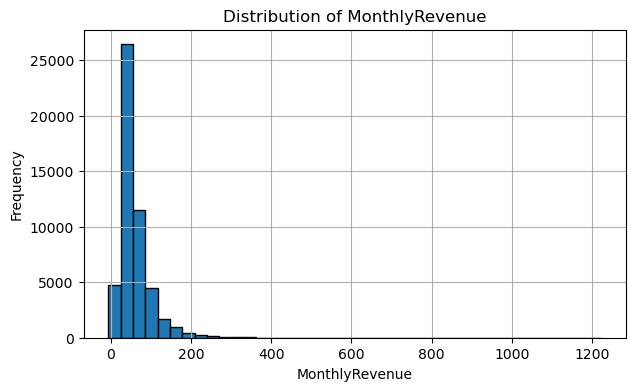

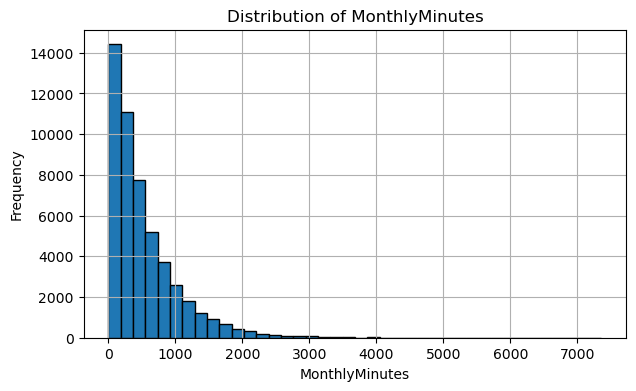

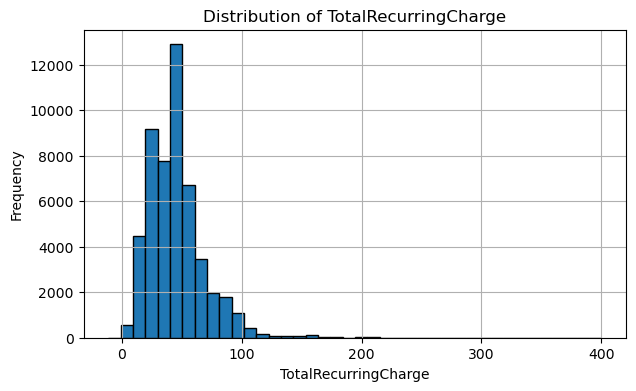

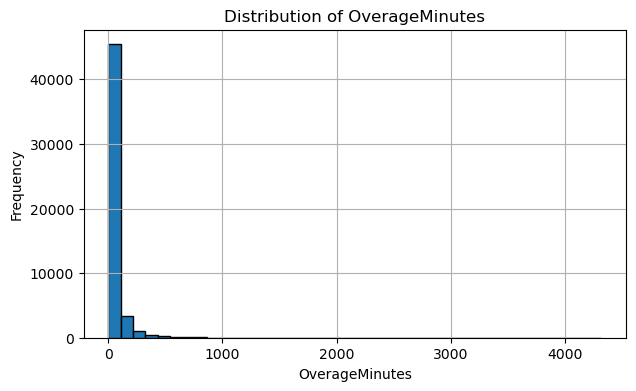

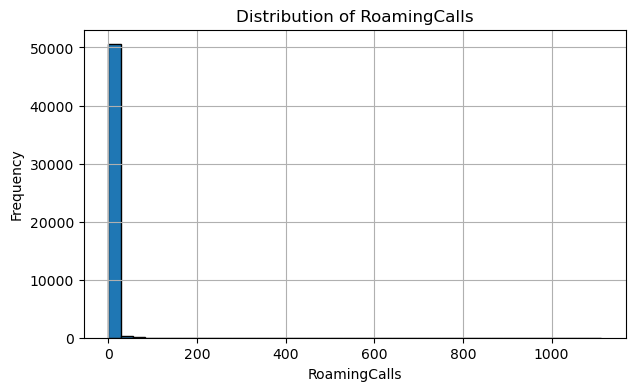

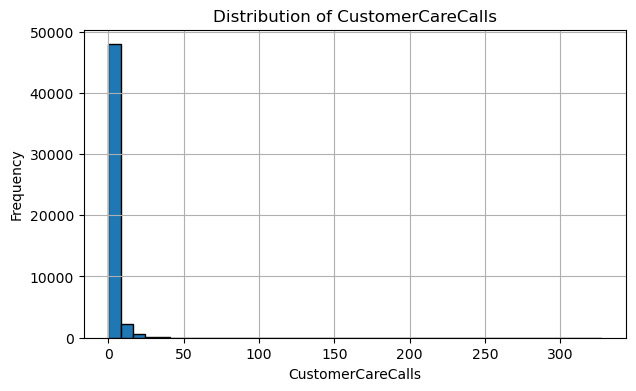

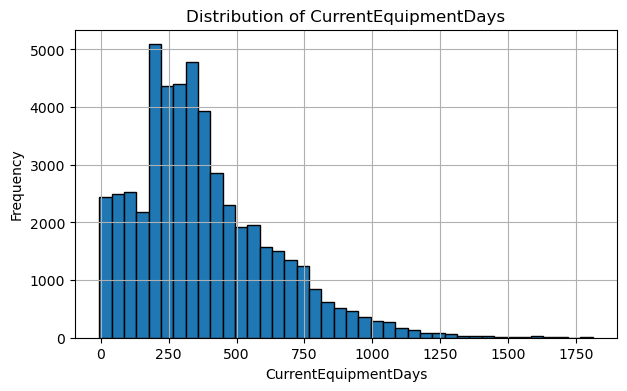

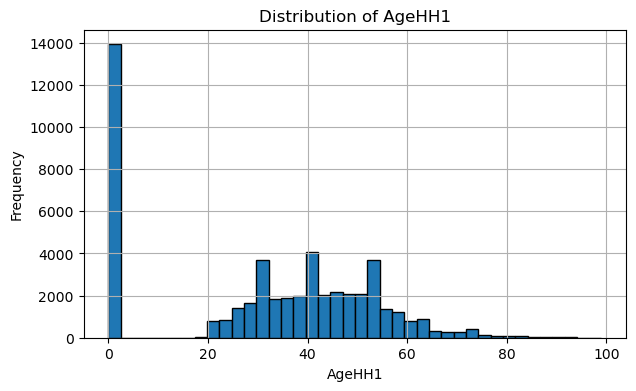

In [16]:
# Representative raw numerical distributions
distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays",
    "AgeHH1"
]

for col in distribution_features:
    plt.figure(figsize=(7, 4))
    train_raw[col].dropna().hist(
        bins=40,
        edgecolor="black"
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

The numerical columns sit on very different scales, from small counts such as `CallForwardingCalls` to `MonthlyMinutes` in the thousands. Many usage variables are strongly right-skewed: for example, `RoamingCalls` has a median of 0 but a maximum of 1,112, and `OverageMinutes` a median of 3 but a maximum of 4,321. Most customers use these services lightly and a few use them heavily.

### 2.9 Invalid, Impossible and Suspicious Values

This section checks for values that may be invalid, internally inconsistent or worthy of further investigation. A flagged value is **not automatically treated as an error** because its validity depends on the semantic meaning of the feature.

Negative values and selected logical relationships are inspected without modifying the data.

In [17]:
# Identify numerical variables containing negative values
negative_value_summary = []

for col in numeric_cols:
    negative_count = (train_raw[col] < 0).sum()

    if negative_count > 0:
        negative_value_summary.append({
            "Feature": col,
            "Negative_Count": int(negative_count),
            "Minimum_Value": train_raw[col].min()
        })

negative_value_summary = pd.DataFrame(negative_value_summary)
display(negative_value_summary)

,Feature,Negative_Count,Minimum_Value
0,MonthlyRevenue,3,-6.17
1,TotalRecurringCharge,8,-11.00
2,PercChangeMinutes,26816,-3875.00
3,PercChangeRevenues,28408,-1107.70
4,CurrentEquipmentDays,76,-5.00


In [18]:
# Selected logical consistency checks
logical_checks = pd.Series({
    "ActiveSubs > UniqueSubs":
        (train_raw["ActiveSubs"] > train_raw["UniqueSubs"]).sum(),

    "RetentionOffersAccepted > RetentionCalls":
        (
            train_raw["RetentionOffersAccepted"]
            > train_raw["RetentionCalls"]
        ).sum(),

    "HandsetModels > Handsets":
        (train_raw["HandsetModels"] > train_raw["Handsets"]).sum()
}, name="Violation_Count")

display(logical_checks.to_frame())

# Inspect zero values in household-age fields
print("AgeHH1 zero values:", (train_raw["AgeHH1"] == 0).sum())
print("AgeHH2 zero values:", (train_raw["AgeHH2"] == 0).sum())

,Violation_Count
ActiveSubs > UniqueSubs,0
RetentionOffersAccepted > RetentionCalls,0
HandsetModels > Handsets,0


AgeHH1 zero values: 13917
AgeHH2 zero values: 26087


Negative values appear in five columns. For `PercChangeMinutes` and `PercChangeRevenues` they are expected, because usage and revenue can fall from one period to the next. The small number of negative `MonthlyRevenue` (3) and `TotalRecurringCharge` (8) values could represent credits or billing adjustments, so they are kept. `CurrentEquipmentDays` has 76 negative values, which cannot be correct for an elapsed number of days.

The logical checks find no customer with more active than unique subscriptions, more accepted retention offers than retention calls, or more handset models than handsets. `AgeHH1` and `AgeHH2` contain many zeros (13,917 and 26,087), which most likely mean "not recorded" or "no second household member" rather than a real age of zero. Since the documentation gives no definition for a zero age, these values are kept as recorded.

### 2.10 Outlier Investigation

Potential outliers are identified using the Interquartile Range (IQR) rule.

For each numerical variable:

- \(IQR = Q3 - Q1\)
- Lower fence = \(Q1 - 1.5 \times IQR\)
- Upper fence = \(Q3 + 1.5 \times IQR\)

Observations outside these fences are **flagged for investigation**, not automatically removed.

In [19]:
# IQR-based outlier audit
outlier_summary = []

for col in numeric_cols:

    # CustomerID is an identifier, so an outlier concept is not meaningful here
    if col == "CustomerID":
        continue

    values = train_raw[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = (
        (values < lower_fence) |
        (values > upper_fence)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Flagged_Count": int(flagged),
        "Flagged_Percentage":
            round(flagged / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    "Flagged_Percentage",
    ascending=False
)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Flagged_Count,Flagged_Percentage
7,PercChangeRevenues,-7.10,1.600,8.700,-20.1500,14.6500,13221,26.09
5,RoamingCalls,0.00,0.300,0.300,-0.4500,0.7500,8835,17.36
20,CallWaitingCalls,0.00,1.300,1.300,-1.9500,3.2500,7448,14.59
6,PercChangeMinutes,-83.00,66.000,149.000,-306.5000,289.5000,6807,13.43
11,CustomerCareCalls,0.00,1.700,1.700,-2.5500,4.2500,6721,13.17
4,OverageMinutes,0.00,41.000,41.000,-61.5000,102.5000,5842,11.48
3,DirectorAssistedCalls,0.00,0.990,0.990,-1.4850,2.4750,5530,10.87
9,BlockedCalls,0.00,3.700,3.700,-5.5500,9.2500,5517,10.81
15,InboundCalls,0.00,9.300,9.300,-13.9500,23.2500,4973,9.74
12,ThreewayCalls,0.00,0.300,0.300,-0.4500,0.7500,4622,9.05


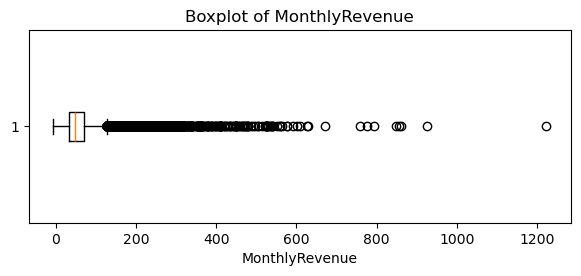

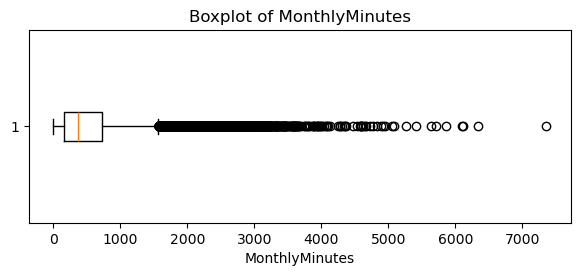

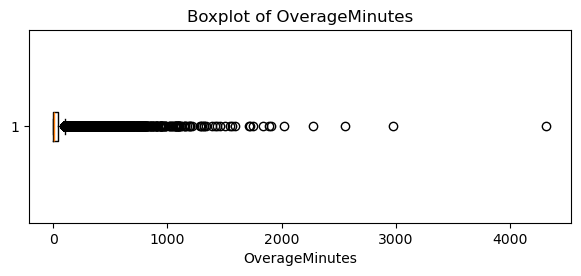

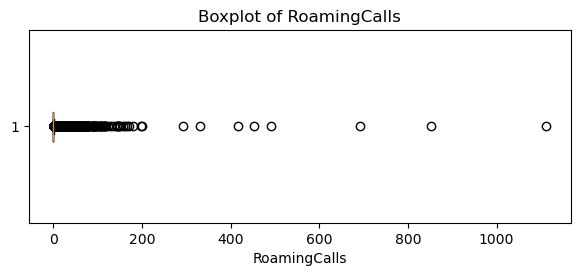

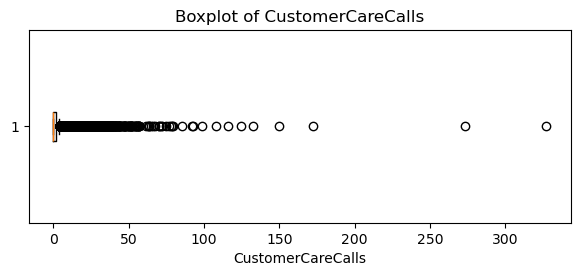

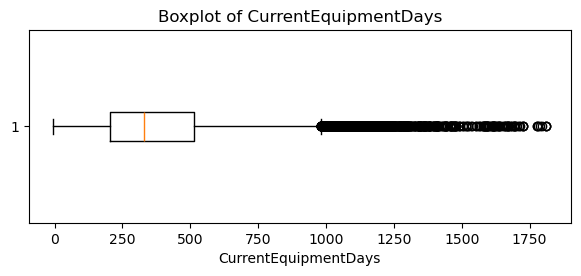

In [20]:
# Selected boxplots for variables with potentially important extreme values
outlier_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays"
]

for col in outlier_features:
    plt.figure(figsize=(7, 2.5))
    plt.boxplot(
        train_raw[col].dropna(),
        vert=False
    )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

The IQR rule flags many customers in the usage columns, for example **26.1%** of `PercChangeRevenues` values and **17.4%** of `RoamingCalls` values. With such skewed distributions, these are mostly genuine heavy users rather than recording errors, and they may carry useful information about churn. They are therefore kept.

### 2.11 Target Distribution and Class Imbalance

The target distribution is inspected to determine whether the two churn classes are represented equally.

,Count,Percentage
Churn,,
No,36336,71.18
Yes,14711,28.82


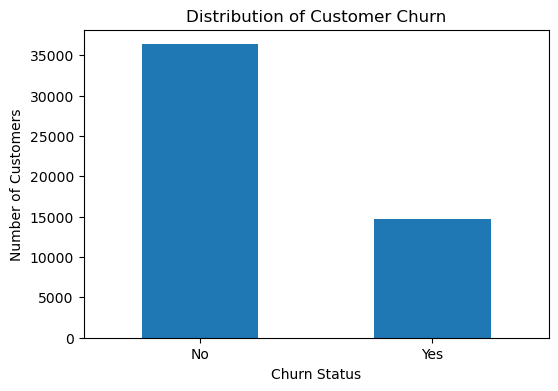

In [21]:
# Target distribution
target_counts = train_raw["Churn"].value_counts()
target_percentages = (
    train_raw["Churn"].value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

# Visualise target distribution
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

The labelled dataset contains **36,336 non-churn customers (approximately 71.18%)** and **14,711 churn customers (approximately 28.82%)**. The target therefore exhibits moderate class imbalance.

### 2.12 Holdout Target Integrity

The target column in the separate holdout file is checked to confirm whether true churn outcomes are available.

In [22]:
print(
    "Missing Churn labels in holdout:",
    holdout_raw["Churn"].isna().sum()
)

print(
    "Total holdout observations:",
    len(holdout_raw)
)

Missing Churn labels in holdout: 20000
Total holdout observations: 20000


All 20,000 `Churn` values in the provided holdout dataset are missing. Therefore, the holdout dataset cannot be used to calculate evaluation measures such as Accuracy, Precision, Recall, F1-score or ROC-AUC. It is retained as an unlabelled dataset for possible final inference after the modelling and evaluation workflow is completed.

### 2.13 Data Audit Summary

| Audit Area | Main Finding |
|---|---|
| Dataset size | 51,047 labelled observations and 58 variables |
| Holdout data | 20,000 observations with no observed `Churn` labels |
| Feature types | Mixture of numerical, binary categorical, nominal and ordered categorical information |
| Target | Binary `Churn` (`Yes` / `No`) |
| Exact duplicates | No complete duplicate rows identified |
| Identifier integrity | `CustomerID` is unique for every labelled observation |
| Actual missing values | Multiple variables contain null values |
| Explicit unknown values | Present in `Homeownership`, `HandsetPrice` and `MaritalStatus` |
| Categorical cardinality | `ServiceArea` contains hundreds of distinct categories |
| Representation issue | `HandsetPrice` contains price-like values together with `Unknown`, producing an object data type |
| Numerical distributions | Several usage-related variables are skewed and contain long tails |
| Suspicious values | Negative/context-dependent values occur in selected numerical fields and require interpretation |
| Internal consistency | Selected logical relationship checks show no violations |
| Potential outliers | IQR analysis flags numerous observations, especially among usage-related variables |
| Target balance | Approximately 71.18% non-churn and 28.82% churn |


## 3. Experimental Design and Data Partitioning

Before any model is trained, the design of the experiment is fixed: what exactly is predicted, which data is used for development and which is kept back for the final test, and how models are validated and compared. Fixing these choices at the start keeps the final test independent of every modelling decision made later. Apart from encoding the target and splitting the rows, the data is not changed in this section.

### 3.1 Experimental Design and Prediction Objective

The task is to predict the recorded `Churn` outcome from the other customer attributes. **Churn (`Yes`) is the positive class**, because the business interest lies in finding the customers who are about to leave.

In practice, a churn model would score current customers a month or two before they might leave. The Cell2Cell documentation defines churn as leaving 31–60 days after the observation date, but the files do not contain the dates themselves.

**Assumption:** the predictors describe each customer up to the observation date, as the documentation implies. Under this assumption, the experiment reproduces the historical churn labels; it cannot show how far in advance churn could be predicted in a live system.

**How the data is used**

| Data | Role |
|---|---|
| `cell2celltrain.csv` (51,047 customers) | Split into a development partition and a test partition |
| Development partition (80%) | Exploratory analysis, training, cross-validation, tuning and every modelling decision |
| Test partition (20%) | Used **once**, at the end, to evaluate the two final models |
| `cell2cellholdout.csv` (20,000 customers) | Demonstration predictions only; no labels |

Three retention fields (`RetentionCalls`, `RetentionOffersAccepted`, `MadeCallToRetentionTeam`) need particular care. A customer may contact the retention team precisely *because* they intend to leave, in which case these fields would reveal the outcome rather than predict it.

### 3.2 Data Preparation Plan

The audit identified several issues that will affect modelling. The table below records the planned treatment for each one. The treatments themselves are applied inside a pipeline that is refitted on each training fold, so that nothing is learned from validation or test data.

| Audit finding | Planned approach | Reason |
|---|---|---|
| Missing numerical and categorical values | Median imputation, plus indicators showing which values were missing | Models need complete inputs, and missingness itself may be informative |
| `HandsetPrice` stored as text with `Unknown` | Convert to numbers; treat `Unknown` as missing | Prices are numeric values, not categories |
| `Unknown` in `Homeownership` and `MaritalStatus` | Keep as its own category | It is a recorded response, not a blank |
| Binary, nominal and ordered categories | One-hot encoding | Avoids inventing numeric distances between labels |
| 747 `ServiceArea` codes | Group rare codes into an "infrequent" category | Keeps the feature space manageable |
| Negative equipment days; zero ages | Negative days → missing; zeros kept | Only clearly impossible values are corrected |
| Skew and IQR outliers | Keep the values | They are plausible heavy users |
| Very different numerical scales | Standardise for Logistic Regression only | Regularised linear models need comparable scales; trees do not |
| `CustomerID` | Exclude from predictors | An identifier carries no behavioural information |
| 28.82% churn | Stratified splits and imbalance-aware metrics | Keeps class balance stable and avoids misleading accuracy |
| Retention fields of uncertain timing | Decide a feature policy before modelling | Prevents use of information that may follow the churn decision |

### 3.3 Predictors, Target and Identifier

The 56 candidate predictors (`X`) are separated from the target (`Churn`) and the identifier (`CustomerID`). The identifier is stored separately so that it can be used to check the split, but it is never given to a model. The original data frame is left unchanged.

In [23]:
# Define the roles of the original columns without modifying train_raw.
TARGET_COL = "Churn"
ID_COL = "CustomerID"

assert TARGET_COL in train_raw.columns
assert ID_COL in train_raw.columns
assert train_raw.columns.is_unique, "Source contains duplicate column names."

candidate_feature_cols = [
    col for col in train_raw.columns
    if col not in {TARGET_COL, ID_COL}
]

# X: all colummns except churn and customerID
X = train_raw.loc[:, candidate_feature_cols].copy()

# Original churn label, stored as yes or no
y_raw = train_raw[TARGET_COL].copy()

# Record identifier
customer_ids = train_raw[ID_COL].copy()

feature_role_summary = pd.DataFrame([
    {"Role": "Candidate predictors (X)", "Number_of_columns": X.shape[1],
     "Description": "All original columns except Churn and CustomerID"},
    {"Role": "Target (y_raw)", "Number_of_columns": 1,
     "Description": "Original observed Churn label (Yes / No)"},
    {"Role": "Identifier (customer_ids)", "Number_of_columns": 1,
     "Description": "CustomerID; retained for verification, not prediction"},
])

display(feature_role_summary)
print("Candidate predictor matrix:", X.shape)
print("Raw target vector:", y_raw.shape)
print("Identifier vector:", customer_ids.shape)

assert X.shape[1] == train_raw.shape[1] - 2
assert TARGET_COL not in X.columns and ID_COL not in X.columns
assert X.index.equals(y_raw.index) and X.index.equals(customer_ids.index)

,Role,Number_of_columns,Description
0,Candidate predictors (X),56,All original columns except Churn and CustomerID
1,Target (y_raw),1,Original observed Churn label (Yes / No)
2,Identifier (customer_ids),1,"CustomerID; retained for verification, not pre..."


Candidate predictor matrix: (51047, 56)
Raw target vector: (51047,)
Identifier vector: (51047,)


At this stage the three retention fields remain in `X`. They are flagged for review.

In [24]:
# Record potentially time-sensitive variables for review before modelling.
retention_features_to_review = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]

assert set(retention_features_to_review).issubset(X.columns)

feature_availability_review = pd.DataFrame({
    "Feature": retention_features_to_review,
    "Current_status": ["Timing not verified"] * len(retention_features_to_review),
    "Required_check": [
        "Was the call count known before the intended churn prediction?",
        "Were accepted offers recorded before the intended prediction?",
        "Was contact with the retention team known before prediction?",
    ],
    "Action_now": ["Flag for pre-modelling review; do not remove yet"] * 3,
})

display(feature_availability_review)

,Feature,Current_status,Required_check,Action_now
0,RetentionCalls,Timing not verified,Was the call count known before the intended c...,Flag for pre-modelling review; do not remove yet
1,RetentionOffersAccepted,Timing not verified,Were accepted offers recorded before the inten...,Flag for pre-modelling review; do not remove yet
2,MadeCallToRetentionTeam,Timing not verified,Was contact with the retention team known befo...,Flag for pre-modelling review; do not remove yet


### 3.4 Target Encoding

The target is encoded as `No = 0` and `Yes = 1`, so that the positive class always means churn. Before the mapping is applied, the code checks that there are no missing or unexpected labels. Because this is a fixed mapping and nothing is learned from the data, it can safely be applied before the split.

In [25]:
# Validate the observed labels before encoding.
LABEL_MAP = {"No": 0, "Yes": 1}
POSITIVE_CLASS = 1

assert y_raw.notna().all(), "Labelled data contains missing Churn values."

unexpected_labels = set(y_raw.unique()) - set(LABEL_MAP)
assert not unexpected_labels, f"Unexpected Churn values: {unexpected_labels}"
assert set(y_raw.unique()) == set(LABEL_MAP), "Expected both churn classes."

# Deterministic target encoding; no fitted transformation or data leakage.
y = y_raw.map(LABEL_MAP).astype("int8")

assert y.notna().all()
assert set(y.unique()) == {0, 1}
assert y.index.equals(X.index)

label_summary = pd.DataFrame({
    "Original_label": ["No", "Yes"],
    "Encoded_label": [0, 1],
    "Count": [int((y == 0).sum()), int((y == 1).sum())],
    "Percentage": [round((y == 0).mean() * 100, 2),
                   round((y == 1).mean() * 100, 2)],
})

display(label_summary)
print("Target validation: PASSED")
print("Original raw target unchanged:", train_raw[TARGET_COL].equals(y_raw))

,Original_label,Encoded_label,Count,Percentage
0,No,0,36336,71.18
1,Yes,1,14711,28.82


Target validation: PASSED
Original raw target unchanged: True


### 3.5 Partitioning Strategy

The labelled customers are split into **80% development** and **20% test** with a stratified random split (`random_state=42`). Every step that involves a decision (exploration, preprocessing design, model training, tuning and threshold choice) uses the development partition only.

The split is **stratified** because only 28.82% of customers churned. Stratification keeps that proportion the same in both partitions, so the test results are not distorted by an unusually easy or difficult sample. A **random** split is used because the data contains no dates that would allow a time-based split, and every row is a distinct customer.

**Limitation:** a random split measures how well the models generalise to new customers from the same period. It does not measure how well they would perform on future customers, whose behaviour may differ.

### 3.6 Development and Final-Test Split

In [26]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20

assert train_raw.index.is_unique, "Row index must uniquely identify each observation."
assert customer_ids.notna().all(), "CustomerID contains missing values."
assert customer_ids.is_unique, "CustomerID must be unique for this split strategy."

# Split row indices so features, target and customer IDs remain aligned.
dev_idx, test_idx = train_test_split(
    train_raw.index.to_numpy(),
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Separate copies of the raw candidate predictors and their labels.
X_dev = X.loc[dev_idx].copy()
X_test = X.loc[test_idx].copy()
y_dev = y.loc[dev_idx].copy()
y_test = y.loc[test_idx].copy()

# IDs are kept for integrity verification, not for model fitting.
customer_ids_dev = customer_ids.loc[dev_idx].copy()
customer_ids_test = customer_ids.loc[test_idx].copy()

partition_summary = pd.DataFrame([
    {"Partition": "Development", "Observations": len(X_dev),
     "Predictor_columns": X_dev.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_dev) / len(X), 2)},
    {"Partition": "Protected final test", "Observations": len(X_test),
     "Predictor_columns": X_test.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_test) / len(X), 2)},
])

display(partition_summary)
print("X_dev:", X_dev.shape, "| y_dev:", y_dev.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Unlabelled holdout kept separate:", holdout_raw.shape)

,Partition,Observations,Predictor_columns,Percentage_of_labelled_data
0,Development,40837,56,80.0
1,Protected final test,10210,56,20.0


X_dev: (40837, 56) | y_dev: (40837,)
X_test: (10210, 56) | y_test: (10210,)
Unlabelled holdout kept separate: (20000, 58)


The split gives **40,837 development customers** and **10,210 test customers**, each with the same 56 candidate predictors.

### 3.7 Split Check

The partitions are checked to confirm that every customer belongs to exactly one partition, that the labels stay aligned with their rows, and that the churn rate is preserved. The test partition is only checked for its structure and class balance; its contents are not explored.

In [27]:
# Verify the partition structure without fitting or tuning any model.
checks = {
    "Every labelled customer is in exactly one partition": len(X_dev) + len(X_test)
    == len(train_raw)
    and set(customer_ids_dev).isdisjoint(set(customer_ids_test)),
    "Development features, labels and IDs aligned": X_dev.index.equals(y_dev.index)
    and X_dev.index.equals(customer_ids_dev.index),
    "Test features, labels and IDs aligned": X_test.index.equals(y_test.index)
    and X_test.index.equals(customer_ids_test.index),
    "Same predictor columns in both partitions": X_dev.columns.equals(X_test.columns),
    "Target and identifier excluded from predictors": not {TARGET_COL, ID_COL} & set(X_dev.columns),
    "Both classes present in both partitions": set(y_dev.unique())
    == set(y_test.unique())
    == {0, 1},
}
display(
    pd.DataFrame(
        {
            "Integrity_check": list(checks),
            "Status": ["PASS" if ok else "FAIL" for ok in checks.values()],
        }
    )
)
assert all(checks.values()), "At least one partition-integrity check failed."

,Integrity_check,Status
0,Every labelled customer is in exactly one part...,PASS
1,"Development features, labels and IDs aligned",PASS
2,"Test features, labels and IDs aligned",PASS
3,Same predictor columns in both partitions,PASS
4,Target and identifier excluded from predictors,PASS
5,Both classes present in both partitions,PASS


In [28]:
# Compare target distributions for structural verification only.
distribution_records = []

for partition_name, labels in [
    ("All labelled data", y),
    ("Development", y_dev),
    ("Protected final test", y_test),
]:
    distribution_records.append({
        "Partition": partition_name,
        "Total": len(labels),
        "No_churn_0": int((labels == 0).sum()),
        "Churn_1": int((labels == 1).sum()),
        "Churn_percentage": round(100 * (labels == 1).mean(), 2),
    })

split_class_distribution = pd.DataFrame(distribution_records)
display(split_class_distribution)

# Stratification should maintain very similar positive-class rates.
assert abs(y_dev.mean() - y.mean()) < 0.01
assert abs(y_test.mean() - y.mean()) < 0.01
print("Class-proportion verification: PASSED")

,Partition,Total,No_churn_0,Churn_1,Churn_percentage
0,All labelled data,51047,36336,14711,28.82
1,Development,40837,29068,11769,28.82
2,Protected final test,10210,7268,2942,28.81


Class-proportion verification: PASSED


All checks pass. The churn rate is **28.82%** in the development partition and **28.81%** in the test partition, so stratification worked as intended.

### 3.8 Cross-Validation and Evaluation Metrics

**Validation.** Model choices are made with **five-fold stratified cross-validation** on the development partition (`StratifiedKFold`, shuffled, `random_state=42`). Each fold uses four-fifths of the development customers for training and the remaining fifth for validation, so every development customer is used for validation exactly once. The same five folds are reused for every model, which makes the comparisons fair, and the test customers never enter any fold.

**Metrics.** Because churners are the minority class, models are ranked mainly by **Average Precision (AP)**, the area under the precision–recall curve. AP measures how well a model places churners at the top of its risk ranking, and a model with no skill scores the churn rate (about 0.288). ROC-AUC gives a second threshold-free view (no-skill value 0.5). Precision, recall, F1, MCC, balanced accuracy and accuracy describe the yes/no decisions at a particular threshold.

In [29]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

N_CV_SPLITS = 5
cv = StratifiedKFold(
    n_splits=N_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Average Precision summarises the precision-recall curve and is the main comparison metric.
PRIMARY_SCORING = "average_precision"
CV_SCORING = {
    "average_precision": "average_precision",  # primary model-selection metric
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy",
    "mcc": make_scorer(matthews_corrcoef),
}

# Check the folds: each development customer must be in exactly one validation fold.
fold_rows = []
validation_appearances = np.zeros(len(X_dev), dtype=int)

for fold_number, (train_positions, valid_positions) in enumerate(cv.split(X_dev, y_dev), start=1):
    assert set(train_positions).isdisjoint(set(valid_positions))
    validation_appearances[valid_positions] += 1

    fold_rows.append(
        {
            "Fold": fold_number,
            "Training_rows": len(train_positions),
            "Validation_rows": len(valid_positions),
            "Training_churn_pct": round(100 * y_dev.iloc[train_positions].mean(), 2),
            "Validation_churn_pct": round(100 * y_dev.iloc[valid_positions].mean(), 2),
        }
    )

cv_fold_summary = pd.DataFrame(fold_rows)
assert len(cv_fold_summary) == N_CV_SPLITS
assert (
    validation_appearances == 1
).all(), "Every development observation should appear in exactly one validation fold."

display(cv_fold_summary)
print("Cross-validation configuration: 5-fold stratified, shuffled, seed =", RANDOM_STATE)
print("Main model-selection metric:", PRIMARY_SCORING)
print("Additional metrics:", ", ".join(k for k in CV_SCORING if k != PRIMARY_SCORING))
print("Every development customer appears in exactly one validation fold.")

,Fold,Training_rows,Validation_rows,Training_churn_pct,Validation_churn_pct
0,1,32669,8168,28.82,28.82
1,2,32669,8168,28.82,28.82
2,3,32670,8167,28.82,28.81
3,4,32670,8167,28.82,28.82
4,5,32670,8167,28.82,28.82


Cross-validation configuration: 5-fold stratified, shuffled, seed = 42
Main model-selection metric: average_precision
Additional metrics: roc_auc, f1, recall, precision, accuracy, mcc
Every development customer appears in exactly one validation fold.


Each validation fold holds about **8,167–8,168 customers** with the same 28.8% churn rate.

**Preventing leakage.** The evaluation follows four rules:

1. Imputation values, scaling parameters, category lists and any feature selection are learned **inside each training fold** through scikit-learn `Pipeline` and `ColumnTransformer` objects, and only then applied to the validation fold.
2. Every modelling decision (features, hyperparameters, class weights and decision thresholds) is based on development data.
3. Both algorithms use the same folds and metrics.
4. After all decisions are fixed, the final pipelines are refitted on the full development partition and evaluated **once** on the test partition.

### 3.9 Experimental Design Summary

| Design element | Finalised decision |
|---|---|
| Learning task | Supervised binary classification of the observed Cell2Cell `Churn` outcome |
| Positive class | `Yes` encoded as `1` (`No` encoded as `0`) |
| Labelled data | 51,047 customers |
| Candidate inputs | 56 raw candidate predictors; `CustomerID` excluded and retained separately |
| Partitioning | 80% development (40,837) / 20% protected final test (10,210) |
| Split method | Stratified random split, `random_state=42` |
| Development validation | Five-fold shuffled `StratifiedKFold`, `random_state=42` |
| Primary future model-selection metric | Average Precision (`average_precision`) |
| Supporting evaluation | ROC-AUC, precision, recall, F1, MCC, accuracy and confusion matrix |
| Supplied holdout | 20,000 customers without observed churn labels; optional inference only |

## 4. Exploratory Data Analysis (Development Data Only)

This section explores how customer characteristics relate to churn, in order to guide the preprocessing and modelling choices that follow. All analysis uses the **40,837 development customers** only. Including the test customers here could influence later decisions and make the final test less independent. No values are imputed, encoded or removed in this section.

### 4.1 Reference Churn Rate

The development predictors and labels are combined into a separate `eda_dev` table, so that the modelling inputs stay unchanged. Every churn-rate chart in this section shows the overall development churn rate as a dashed reference line, and subgroup differences are expressed in percentage points (pp) relative to it. A subgroup above the line has a higher churn rate than average in this sample; this alone does not make the difference statistically significant or causal.

In [30]:
# EDA uses development customers only; eda_dev is a separate copy so X_dev stays unchanged.
assert X_dev.index.equals(y_dev.index), "Development features and labels are misaligned."
assert "Churn" not in X_dev.columns and "CustomerID" not in X_dev.columns

eda_dev = X_dev.copy()
eda_dev["Churn"] = y_dev  # Pandas aligns the labels by original row index.

DEV_CHURN_RATE = float(y_dev.mean())
DEV_CHURN_PCT = 100 * DEV_CHURN_RATE


def add_churn_baseline(ax, orientation="horizontal"):
    """Draw the development churn rate as a dashed reference line on a churn-rate chart."""
    label = f"Development baseline: {DEV_CHURN_PCT:.2f}%"
    if orientation == "horizontal":  # horizontal line for vertical bars
        ax.axhline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    elif orientation == "vertical":  # vertical line for horizontal bars
        ax.axvline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    else:
        raise ValueError("orientation must be 'horizontal' or 'vertical'")


assert eda_dev.shape == (len(X_dev), X_dev.shape[1] + 1)
assert eda_dev["Churn"].equals(y_dev)
print(f"Development EDA: {len(eda_dev):,} customers, {X_dev.shape[1]} predictors")
print(f"Development churn rate (reference line): {DEV_CHURN_PCT:.2f}%")

Development EDA: 40,837 customers, 56 predictors
Development churn rate (reference line): 28.82%


The development churn rate is **28.82%**, which is the reference for all of the comparisons below.

### 4.2 Feature Types in the Development Data

The storage types of the 56 candidate predictors are counted, together with the number of columns that contain missing values.

In [31]:
# Storage types of the 56 candidate predictors in the development data.
eda_numeric_columns = X_dev.select_dtypes(include=np.number).columns.tolist()
eda_object_columns = X_dev.select_dtypes(exclude=np.number).columns.tolist()

eda_overview = pd.DataFrame(
    [
        {"Property": "Development observations", "Value": len(X_dev)},
        {"Property": "Candidate predictor columns", "Value": X_dev.shape[1]},
        {"Property": "Numerically stored predictors", "Value": len(eda_numeric_columns)},
        {"Property": "Non-numerically stored predictors", "Value": len(eda_object_columns)},
        {"Property": "Predictors with actual nulls", "Value": int(X_dev.isna().any().sum())},
        {"Property": "Target positive class", "Value": "Churn = 1 (Yes)"},
        {"Property": "Development churn prevalence", "Value": f"{DEV_CHURN_PCT:.2f}%"},
    ]
)
display(eda_overview)
print("Examples of numerical predictors:", ", ".join(eda_numeric_columns[:9]))
print("Examples of stored text predictors:", ", ".join(eda_object_columns[:9]))

,Property,Value
0,Development observations,40837
1,Candidate predictor columns,56
2,Numerically stored predictors,34
3,Non-numerically stored predictors,22
4,Predictors with actual nulls,14
5,Target positive class,Churn = 1 (Yes)
6,Development churn prevalence,28.82%


Examples of numerical predictors: MonthlyRevenue, MonthlyMinutes, TotalRecurringCharge, DirectorAssistedCalls, OverageMinutes, RoamingCalls, PercChangeMinutes, PercChangeRevenues, DroppedCalls
Examples of stored text predictors: ServiceArea, ChildrenInHH, HandsetRefurbished, HandsetWebCapable, TruckOwner, RVOwner, Homeownership, BuysViaMailOrder, RespondsToMailOffers


Of the 56 candidate predictors, **34 are stored as numbers** and **22 as text**, and 14 contain true nulls. Storage type does not always match meaning: `IncomeGroup` is a numeric code for an income band, and `HandsetPrice` holds prices stored as text because of its `Unknown` entries.

### 4.3 Class Distribution

The two classes are counted, and the accuracy of a trivial rule that always predicts "No churn" is calculated. This rule is a reference point, not a fitted model.

,Outcome,Customers,Percentage
0,No churn (0),29068,71.18
1,Churn (1),11769,28.82


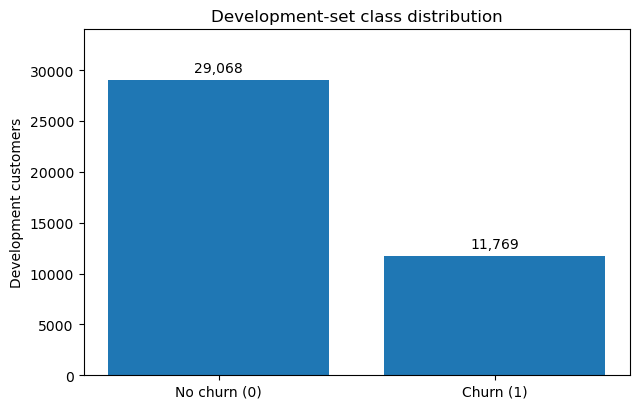

Reference churn rate: 28.82%
Accuracy of always predicting 'No churn': 71.18%


In [32]:
# Class counts, and the accuracy of a rule that always predicts 'No churn'.
eda_target_counts = y_dev.value_counts().reindex([0, 1], fill_value=0)
eda_target_summary = pd.DataFrame(
    {
        "Outcome": ["No churn (0)", "Churn (1)"],
        "Customers": eda_target_counts.to_numpy(),
        "Percentage": (100 * eda_target_counts / len(y_dev)).round(2).to_numpy(),
    }
)
display(eda_target_summary)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(eda_target_summary["Outcome"], eda_target_summary["Customers"])
for bar, count in zip(bars, eda_target_summary["Customers"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 450,
        f"{count:,}",
        ha="center",
        va="bottom",
    )
ax.set_ylim(0, eda_target_summary["Customers"].max() * 1.17)
ax.set_ylabel("Development customers")
ax.set_title("Development-set class distribution")
plt.tight_layout()
plt.show()

majority_accuracy = 100 * eda_target_counts.max() / len(y_dev)
print(f"Reference churn rate: {DEV_CHURN_PCT:.2f}%")
print(f"Accuracy of always predicting 'No churn': {majority_accuracy:.2f}%")

The development set has **29,068 non-churners (71.18%)** and **11,769 churners (28.82%)**. Always predicting "No churn" would score **71.18% accuracy** while missing every churner. For this reason, models are compared mainly on Average Precision and churn-focused measures rather than on accuracy.

### 4.4 Distributions of Key Numerical Features

Eight important numerical features are summarised by their missingness, share of zeros, central values, upper tail and skewness. The summary table uses all values, while the histograms show the 1st–99th percentile range so that the bulk of each distribution is readable. This is a display choice only; no values are removed.

In [33]:
# Shape of eight key numerical features: missingness, zeros, centre, tail and skewness.
eda_distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "MonthsInService",
    "CustomerCareCalls",
    "DroppedCalls",
    "OverageMinutes",
    "CurrentEquipmentDays",
    "RoamingCalls",
]
assert set(eda_distribution_features).issubset(X_dev.columns)

numeric_distribution_rows = []
for feature in eda_distribution_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    nonmissing = s.dropna()
    numeric_distribution_rows.append(
        {
            "Feature": feature,
            "Missing_%": round(100 * s.isna().mean(), 2),
            "Zero_%_of_all_rows": round(100 * s.eq(0).mean(), 2),
            "Mean": round(nonmissing.mean(), 2),
            "Median": round(nonmissing.median(), 2),
            "P95": round(nonmissing.quantile(0.95), 2),
            "P99": round(nonmissing.quantile(0.99), 2),
            "Maximum": round(nonmissing.max(), 2),
            "Skewness": round(nonmissing.skew(), 2),
        }
    )
numeric_distribution_summary = pd.DataFrame(numeric_distribution_rows)
display(numeric_distribution_summary)

,Feature,Missing_%,Zero_%_of_all_rows,Mean,Median,P95,P99,Maximum,Skewness
0,MonthlyRevenue,0.29,0.01,58.99,48.47,136.31,228.33,1223.38,4.31
1,MonthlyMinutes,0.29,1.40,525.24,367.00,1569.20,2450.00,7359.00,2.19
2,MonthsInService,0.00,0.00,18.78,16.00,37.00,49.00,61.00,1.06
3,CustomerCareCalls,0.00,54.89,1.87,0.00,9.30,21.30,327.30,12.88
4,DroppedCalls,0.00,15.05,6.01,3.00,22.00,42.30,221.70,4.39
5,OverageMinutes,0.29,45.59,40.31,3.00,191.00,434.00,4321.00,8.36
6,CurrentEquipmentDays,0.00,0.04,380.44,329.00,866.00,1141.65,1812.00,1.08
7,RoamingCalls,0.29,68.66,1.24,0.00,5.00,21.58,1112.40,58.99


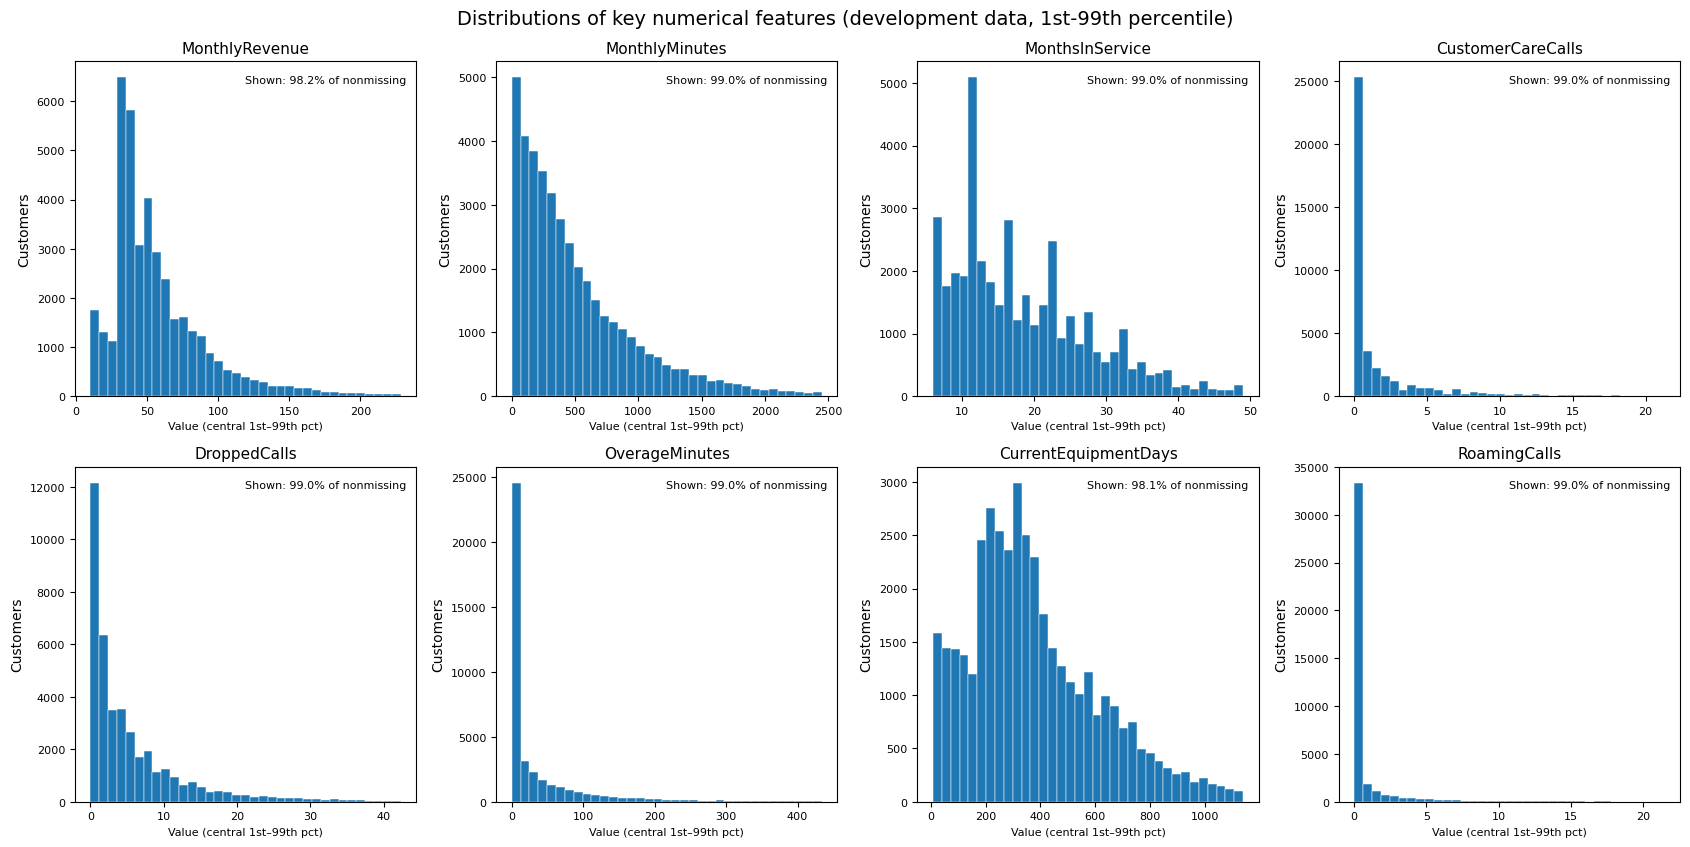

In [34]:
# Histograms show the 1st-99th percentile range for readability; no data is removed.
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, feature in zip(axes.flat, eda_distribution_features):
    values = pd.to_numeric(X_dev[feature], errors="coerce").dropna()
    lower, upper = values.quantile([0.01, 0.99])
    if lower >= upper:
        lower, upper = values.min(), values.max()
    visible = values.between(lower, upper)
    ax.hist(values[visible], bins=35, edgecolor="white", linewidth=0.35)
    ax.set_title(feature, fontsize=11)
    ax.set_ylabel("Customers")
    ax.set_xlabel("Value (central 1st–99th pct)", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)
    ax.text(
        0.97,
        0.96,
        f"Shown: {visible.mean()*100:.1f}% of nonmissing",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
fig.suptitle(
    "Distributions of key numerical features (development data, 1st-99th percentile)", fontsize=14
)
plt.tight_layout()
plt.show()

Most usage features are heavily right-skewed and zero-inflated. `RoamingCalls` is zero for **68.66%** of customers (skewness 58.99), `CustomerCareCalls` for **54.89%** (skewness 12.88) and `OverageMinutes` for **45.59%** (skewness 8.36), while each has a long tail of heavy users. `MonthlyRevenue` (median 48.47, maximum 1,223) and `MonthlyMinutes` (median 367, maximum 7,359) behave similarly. Tenure (`MonthsInService`) and equipment age (`CurrentEquipmentDays`) are much less skewed. These shapes motivate scaling for Logistic Regression.

### 4.5 Numerical Features by Churn Outcome

Medians and means of key numerical features are compared between churners and non-churners, with boxplots for four of them. Outlier markers are hidden in the boxplots to keep them readable.

In [35]:
# Medians and means of key numerical features for churners and non-churners.
class_compare_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "MonthsInService",
    "CustomerCareCalls",
    "DroppedCalls",
    "OverageMinutes",
    "CurrentEquipmentDays",
]
class_comparison_rows = []
for feature in class_compare_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    no_values = s[y_dev == 0].dropna()
    yes_values = s[y_dev == 1].dropna()
    class_comparison_rows.append(
        {
            "Feature": feature,
            "No_churn_N": len(no_values),
            "Churn_N": len(yes_values),
            "No_churn_median": round(no_values.median(), 2),
            "Churn_median": round(yes_values.median(), 2),
            "Median_difference_Churn_minus_No": round(yes_values.median() - no_values.median(), 2),
            "No_churn_mean": round(no_values.mean(), 2),
            "Churn_mean": round(yes_values.mean(), 2),
        }
    )
numerical_churn_comparison = pd.DataFrame(class_comparison_rows)
display(numerical_churn_comparison)

,Feature,No_churn_N,Churn_N,No_churn_median,Churn_median,Median_difference_Churn_minus_No,No_churn_mean,Churn_mean
0,MonthlyRevenue,29003,11714,48.81,47.51,-1.3,59.29,58.26
1,MonthlyMinutes,29003,11714,381.00,331.00,-50.0,541.64,484.65
2,MonthsInService,29068,11769,16.00,17.00,1.0,18.64,19.14
3,CustomerCareCalls,29068,11769,0.00,0.00,0.0,1.98,1.58
4,DroppedCalls,29068,11769,3.00,3.00,0.0,6.07,5.85
5,OverageMinutes,29003,11714,2.00,3.00,1.0,39.11,43.29
6,CurrentEquipmentDays,29067,11769,310.00,367.00,57.0,363.35,422.66


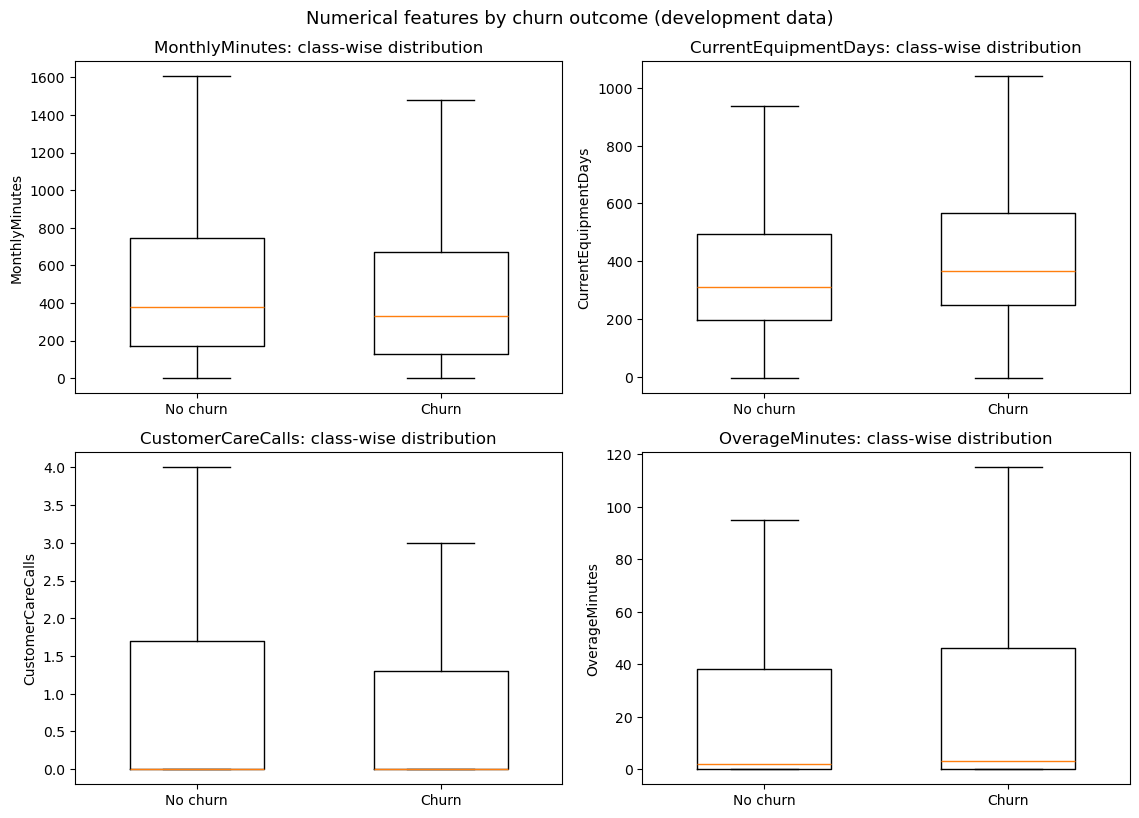

In [36]:
# Boxplots by churn outcome (outlier markers hidden to keep the boxes readable).
boxplot_features = ["MonthlyMinutes", "CurrentEquipmentDays", "CustomerCareCalls", "OverageMinutes"]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.3))
for ax, feature in zip(axes.flat, boxplot_features):
    no_values = X_dev.loc[y_dev == 0, feature].dropna()
    yes_values = X_dev.loc[y_dev == 1, feature].dropna()
    ax.boxplot([no_values, yes_values], showfliers=False, widths=0.55)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No churn", "Churn"])
    ax.set_ylabel(feature)
    ax.set_title(f"{feature}: class-wise distribution")
fig.suptitle("Numerical features by churn outcome (development data)", fontsize=13)
plt.tight_layout()
plt.show()

Two features separate the groups most clearly. Churners used fewer minutes (median **331** vs **381** per month) and had older handsets (median `CurrentEquipmentDays` **367** vs **310**). Revenue, tenure and dropped calls differ very little at the median. Customer-care calls have a median of zero in both groups, so their distributions need to be compared through rates rather than medians

### 4.6 Churn Rates Across Value Ranges

Averages can hide relationships that change direction across a feature's range. Churn rates are therefore computed within bands: fixed ranges for tenure and customer-care calls, and development-data quintiles for monthly minutes and equipment age. Each band's customer count is shown, so that small groups are not over-interpreted.

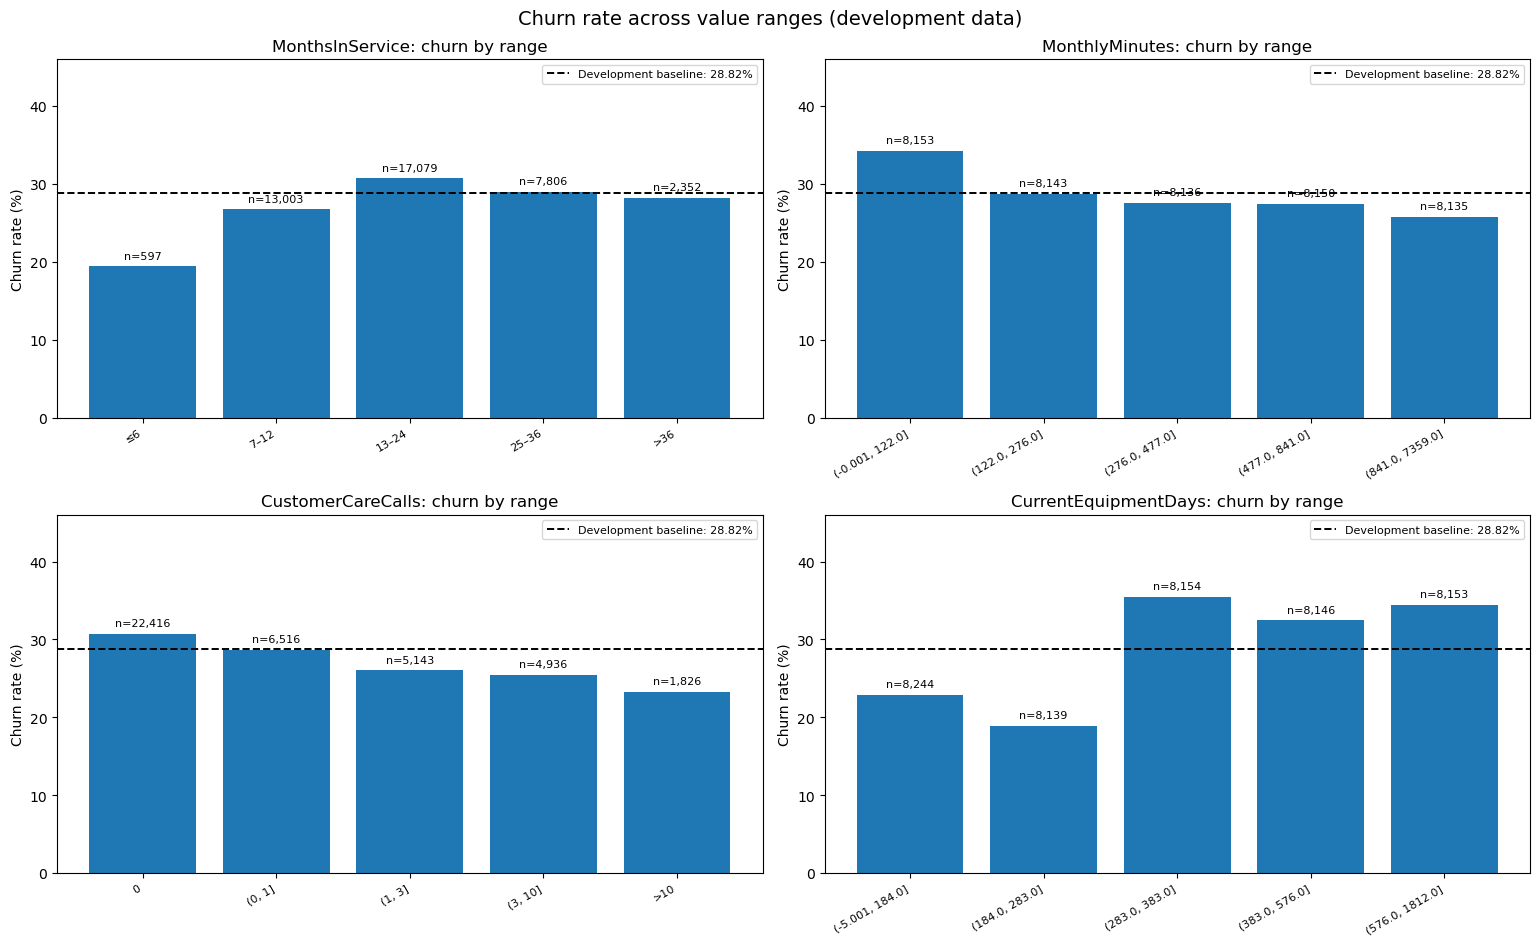

,Feature,Band,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,MonthsInService,≤6,597,116,19.43,-9.39
1,MonthsInService,7–12,13003,3475,26.72,-2.09
2,MonthsInService,13–24,17079,5251,30.75,1.93
3,MonthsInService,25–36,7806,2264,29.00,0.18
4,MonthsInService,>36,2352,663,28.19,-0.63
5,MonthlyMinutes,"(-0.001, 122.0]",8153,2795,34.28,5.46
6,MonthlyMinutes,"(122.0, 276.0]",8143,2337,28.70,-0.12
7,MonthlyMinutes,"(276.0, 477.0]",8136,2246,27.61,-1.21
8,MonthlyMinutes,"(477.0, 841.0]",8150,2238,27.46,-1.36
9,MonthlyMinutes,"(841.0, 7359.0]",8135,2098,25.79,-3.03


In [37]:
# Churn rate within value bands: fixed bands for tenure and care calls, quintiles for the rest.
num_band_definitions = {
    "MonthsInService": pd.cut(
        X_dev["MonthsInService"],
        bins=[-np.inf, 6, 12, 24, 36, np.inf],
        labels=["≤6", "7–12", "13–24", "25–36", ">36"],
    ),
    "MonthlyMinutes": pd.qcut(X_dev["MonthlyMinutes"], q=5, duplicates="drop"),
    "CustomerCareCalls": pd.cut(
        X_dev["CustomerCareCalls"],
        bins=[-np.inf, 0, 1, 3, 10, np.inf],
        labels=["0", "(0, 1]", "(1, 3]", "(3, 10]", ">10"],
    ),
    "CurrentEquipmentDays": pd.qcut(X_dev["CurrentEquipmentDays"], q=5, duplicates="drop"),
}

numerical_band_summaries = {}
for feature, bands in num_band_definitions.items():
    grouped = (
        pd.DataFrame({"Band": bands, "Churn": y_dev})
        .dropna(subset=["Band"])
        .groupby("Band", observed=True)["Churn"]
        .agg(N="size", Churn_N="sum", Churn_rate="mean")
        .reset_index()
    )
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    numerical_band_summaries[feature] = grouped

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.6))
for ax, (feature, summary) in zip(axes.flat, numerical_band_summaries.items()):
    xpos = np.arange(len(summary))
    bars = ax.bar(xpos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "horizontal")
    ax.set_xticks(xpos)
    ax.set_xticklabels(summary["Band"].astype(str), rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"{feature}: churn by range")
    ax.set_ylim(0, max(46, float(summary["Churn_rate_pct"].max()) + 9))
    for bar, n in zip(bars, summary["N"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.7,
            f"n={n:,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Churn rate across value ranges (development data)", fontsize=14)
plt.tight_layout()
plt.show()

numerical_band_table = pd.concat(
    [
        summary.assign(Feature=feature, Band=summary["Band"].astype(str))
        for feature, summary in numerical_band_summaries.items()
    ],
    ignore_index=True,
)
display(
    numerical_band_table[
        ["Feature", "Band", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
    ].round(2)
)

Several relationships are clearly non-linear:

- **Monthly minutes:** churn falls steadily from **34.28%** in the lowest-usage quintile to **25.79%** in the highest. Light users are the most likely to leave.
- **Equipment age:** churn is lowest for handsets about 6–9 months old (**18.91%**) and jumps to **35.49%** once the handset passes about 9–12 months (283–383 days), staying high after that. This fits customers reaching the end of a handset or contract cycle and becoming free to switch, although the data does not record contract terms.
- **Tenure:** new customers (≤ 6 months) churn least (**19.43%**, but only 597 customers), and churn peaks at **30.75%** for 13–24 months.
- **Customer-care calls:** churn *decreases* as calls increase, from **30.71%** with no calls to **23.27%** with more than ten. Customers who contact customer care may be more engaged, rather than more dissatisfied.

A linear model cannot represent a jump such as the one in equipment age with a single coefficient, which is one reason to include a tree-based algorithm in the comparison.

### 4.7 Categorical Features and Churn

Churn rates are compared across the categories of six customer-profile and account features. The size of each group is shown, so that small groups are not over-interpreted.

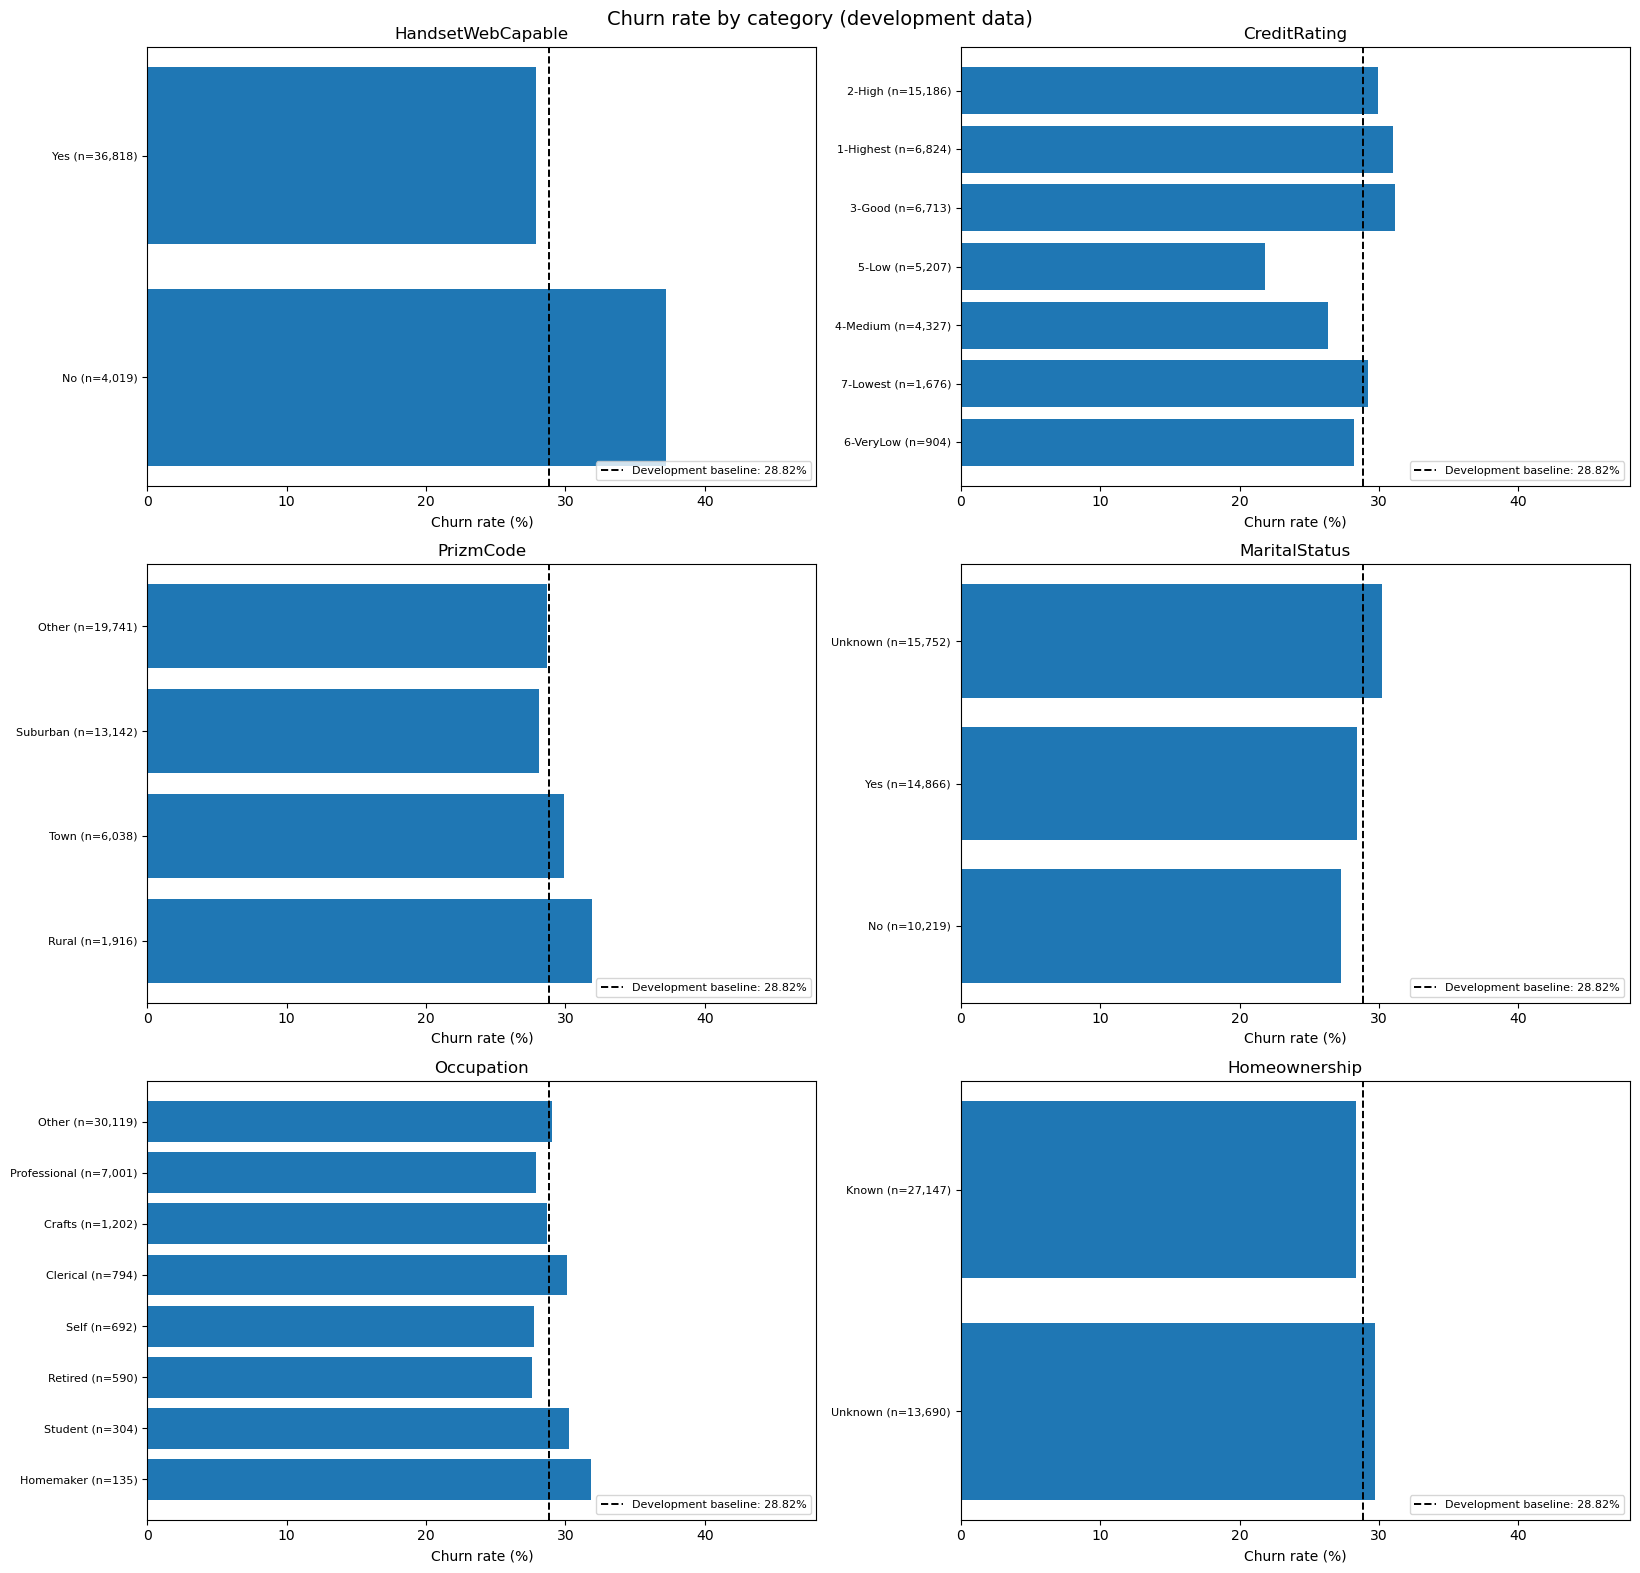

,Feature,Category,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,HandsetWebCapable,Yes,36818,10274,27.90,-0.91
1,HandsetWebCapable,No,4019,1495,37.20,8.38
2,CreditRating,2-High,15186,4543,29.92,1.10
3,CreditRating,1-Highest,6824,2117,31.02,2.20
4,CreditRating,3-Good,6713,2090,31.13,2.31
5,CreditRating,5-Low,5207,1135,21.80,-7.02
6,CreditRating,4-Medium,4327,1140,26.35,-2.47
7,CreditRating,7-Lowest,1676,489,29.18,0.36
8,CreditRating,6-VeryLow,904,255,28.21,-0.61
9,PrizmCode,Other,19741,5657,28.66,-0.16


In [38]:
# Churn rate for each category of six profile and account features.
eda_categorical_features = [
    "HandsetWebCapable",
    "CreditRating",
    "PrizmCode",
    "MaritalStatus",
    "Occupation",
    "Homeownership",
]
category_summaries = {}
for feature in eda_categorical_features:
    category = X_dev[feature].astype("string").fillna("<Missing>")
    grouped = (
        pd.DataFrame({"Category": category, "Churn": y_dev})
        .groupby("Category", dropna=False)["Churn"]
        .agg(N="size", Churn_N="sum", Churn_rate="mean")
        .sort_values("N", ascending=False)
        .reset_index()
    )
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    category_summaries[feature] = grouped

fig, axes = plt.subplots(3, 2, figsize=(16.5, 16))
for ax, (feature, summary) in zip(axes.flat, category_summaries.items()):
    ypos = np.arange(len(summary))
    ax.barh(ypos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "vertical")
    ax.set_yticks(ypos)
    ax.set_yticklabels(
        [f"{cat} (n={n:,})" for cat, n in zip(summary["Category"], summary["N"])], fontsize=8
    )
    ax.invert_yaxis()
    ax.set_xlim(0, max(48, float(summary["Churn_rate_pct"].max()) + 6))
    ax.set_xlabel("Churn rate (%)")
    ax.set_title(feature)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Churn rate by category (development data)", fontsize=14)
plt.tight_layout()
plt.show()

categorical_churn_table = pd.concat(
    [summary.assign(Feature=feature) for feature, summary in category_summaries.items()],
    ignore_index=True,
)
display(
    categorical_churn_table[
        ["Feature", "Category", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
    ].round(2)
)

The clearest categorical difference is handset capability: customers **without a web-capable handset churn at 37.20%** (4,019 customers) against 27.90% for those with one. Credit rating shows a mixed pattern: the `5-Low` group churns least (**21.80%**) while the highest ratings sit around 31%, so the categories should not be treated as an evenly spaced scale. `MaritalStatus = Unknown` (30.21%) and rural `PrizmCode` (31.89%) are slightly above average. Occupation differences are small, and its smaller groups (for example 135 homemakers) are too small to read much into.

### 4.8 Missingness and Churn

The audit showed where values are missing. This step examines whether customers with missing or `Unknown` values churn at a different rate from other customers. True nulls and recorded `Unknown` values are again kept separate.

,Flag,Flagged_N,Flagged_%,Flagged_churn_%,Unflagged_churn_%,Delta_vs_baseline_pp
0,PercChangeMinutes: null,290,0.71,56.90,28.62,28.08
1,MonthlyRevenue: null,120,0.29,45.83,28.77,17.01
2,AgeHH1: null,716,1.75,27.79,28.84,-1.03
3,ServiceArea: null,21,0.05,47.62,28.81,18.80
4,HandsetPrice: Unknown,23214,56.85,30.01,27.25,1.19
5,MaritalStatus: Unknown,15752,38.57,30.21,27.94,1.39
6,Homeownership: Unknown,13690,33.52,29.70,28.38,0.88


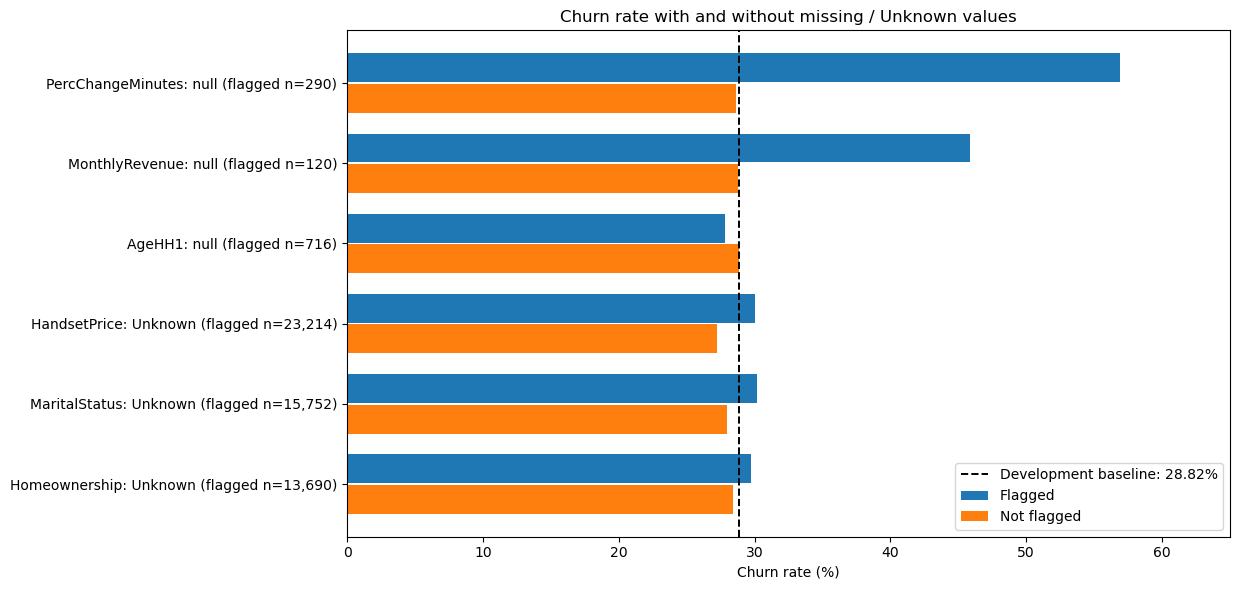

In [39]:
# Churn rate for customers with a missing or 'Unknown' value, against everyone else.
missingness_flags = {
    "PercChangeMinutes: null": X_dev["PercChangeMinutes"].isna(),
    "MonthlyRevenue: null": X_dev["MonthlyRevenue"].isna(),
    "AgeHH1: null": X_dev["AgeHH1"].isna(),
    "ServiceArea: null": X_dev["ServiceArea"].isna(),
    "HandsetPrice: Unknown": X_dev["HandsetPrice"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
    "MaritalStatus: Unknown": X_dev["MaritalStatus"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
    "Homeownership: Unknown": X_dev["Homeownership"]
    .astype("string")
    .str.strip()
    .eq("Unknown")
    .fillna(False),
}
missingness_rows = []
for label, flag in missingness_flags.items():
    flag = flag.astype(bool)
    n_flagged = int(flag.sum())
    n_unflagged = int((~flag).sum())
    missingness_rows.append(
        {
            "Flag": label,
            "Flagged_N": n_flagged,
            "Flagged_%": 100 * n_flagged / len(flag),
            "Flagged_churn_%": 100 * y_dev[flag].mean() if n_flagged else np.nan,
            "Unflagged_churn_%": 100 * y_dev[~flag].mean() if n_unflagged else np.nan,
            "Delta_vs_baseline_pp": (
                (100 * y_dev[flag].mean() - DEV_CHURN_PCT) if n_flagged else np.nan
            ),
        }
    )
missingness_churn_summary = pd.DataFrame(missingness_rows)
display(missingness_churn_summary.round(2))

# Exclude the very small flagged groups from the comparison plot, but keep them in the table.
plot_missing = missingness_churn_summary.query("Flagged_N >= 100").copy()
ypos = np.arange(len(plot_missing))
fig, ax = plt.subplots(figsize=(12.5, 6))
ax.barh(ypos - 0.19, plot_missing["Flagged_churn_%"], height=0.36, label="Flagged")
ax.barh(ypos + 0.19, plot_missing["Unflagged_churn_%"], height=0.36, label="Not flagged")
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [
        f"{label} (flagged n={n:,})"
        for label, n in zip(plot_missing["Flag"], plot_missing["Flagged_N"])
    ]
)
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(65, float(plot_missing["Flagged_churn_%"].max()) + 5))
ax.set_title("Churn rate with and without missing / Unknown values")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Missing values are strongly linked to churn for some fields. Customers with a missing `PercChangeMinutes` churn at **56.90%** (290 customers), almost double the rate of customers with a recorded value (28.62%), and customers with missing `MonthlyRevenue` at **45.83%** (120). The `Unknown` codes make much less difference (30.01% for `HandsetPrice`, 30.21% for `MaritalStatus`, 29.70% for `Homeownership`). Missing `ServiceArea` affects only 21 customers, too few for a reliable rate.

### 4.9 Correlation Between Numerical Features

Pearson correlations are computed between all numerical predictors to find features that carry overlapping information. The heatmap shows a selection of billing, usage and account features; the table lists the strongest pairs among all of them.

,Feature_1,Feature_2,Pearson_r,Absolute_r
516,Handsets,HandsetModels,0.888,0.888
44,MonthlyMinutes,ReceivedCalls,0.827,0.827
269,BlockedCalls,DroppedBlockedCalls,0.816,0.816
495,UniqueSubs,ActiveSubs,0.805,0.805
3,MonthlyRevenue,OverageMinutes,0.783,0.783
47,MonthlyMinutes,PeakCallsInOut,0.773,0.773
48,MonthlyMinutes,OffPeakCallsInOut,0.765,0.765
353,ReceivedCalls,PeakCallsInOut,0.746,0.746
373,OutboundCalls,OffPeakCallsInOut,0.740,0.740
354,ReceivedCalls,OffPeakCallsInOut,0.736,0.736


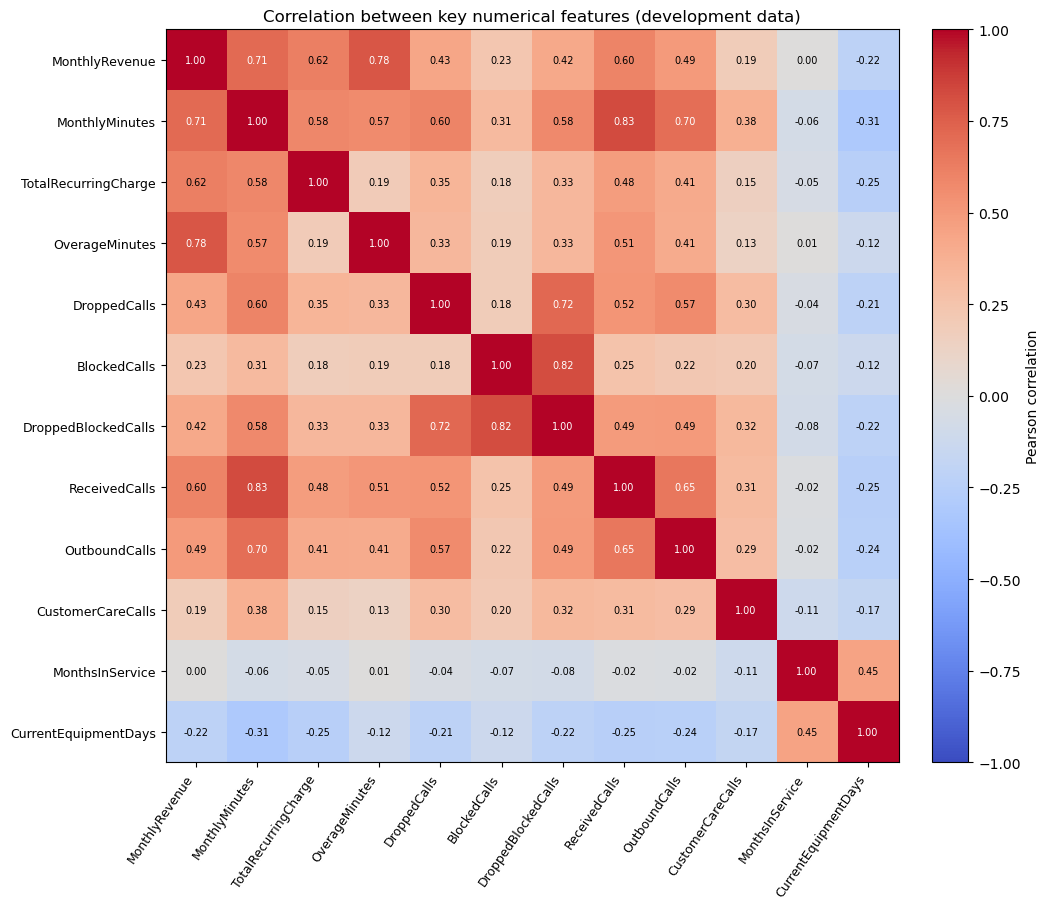

In [40]:
# Pearson correlations between all numerical predictors; strongest pairs first.
eda_numeric_corr = X_dev[eda_numeric_columns].corr(method="pearson")
upper_triangle = np.triu(np.ones(eda_numeric_corr.shape, dtype=bool), k=1)
correlation_pairs = eda_numeric_corr.where(upper_triangle).stack().rename("Pearson_r").reset_index()
correlation_pairs.columns = ["Feature_1", "Feature_2", "Pearson_r"]
correlation_pairs["Absolute_r"] = correlation_pairs["Pearson_r"].abs()
correlation_pairs = correlation_pairs.sort_values("Absolute_r", ascending=False)
display(correlation_pairs.head(12).round(3))

heatmap_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "DroppedCalls",
    "BlockedCalls",
    "DroppedBlockedCalls",
    "ReceivedCalls",
    "OutboundCalls",
    "CustomerCareCalls",
    "MonthsInService",
    "CurrentEquipmentDays",
]
heat = eda_numeric_corr.loc[heatmap_features, heatmap_features]
fig, ax = plt.subplots(figsize=(10.5, 9.2))
im = ax.imshow(heat.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(heatmap_features)))
ax.set_xticklabels(heatmap_features, rotation=55, ha="right", fontsize=9)
ax.set_yticks(range(len(heatmap_features)))
ax.set_yticklabels(heatmap_features, fontsize=9)
for row in range(len(heatmap_features)):
    for col in range(len(heatmap_features)):
        val = heat.iat[row, col]
        if np.isfinite(val):
            ax.text(
                col,
                row,
                f"{val:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(val) > 0.65 else "black",
            )
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Correlation between key numerical features (development data)")
plt.tight_layout()
plt.show()

Several features are strongly correlated: `Handsets` with `HandsetModels` (**r = 0.89**), `MonthlyMinutes` with `ReceivedCalls` (**0.83**), `BlockedCalls` with `DroppedBlockedCalls` (**0.82**, which includes blocked calls by definition) and `UniqueSubs` with `ActiveSubs` (**0.81**). Correlated inputs are not a problem for Random Forest's predictions, but they make individual Logistic Regression coefficients harder to interpret, because the L2 penalty shares the effect between them.

### 4.10 The High-Cardinality `ServiceArea` Feature

The number of customers per service-area code is examined, together with the churn rates of the ten largest areas. The areas are chosen by size rather than by churn rate, to avoid highlighting extreme rates from very small groups.

,Measure,Value
0,Distinct nonmissing ServiceArea codes,729
1,Customers with missing ServiceArea,21
2,Codes with fewer than 20 development customers,434
3,Customers in codes with fewer than 20 records,2441
4,Codes with fewer than 50 development customers,546


,ServiceArea,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,NYCBRO917,1330,360,27.07,-1.75
1,HOUHOU281,1232,310,25.16,-3.66
2,DALDAL214,1195,340,28.45,-0.37
3,NYCMAN917,956,268,28.03,-0.79
4,DALFTW817,636,174,27.36,-1.46
5,APCFCH703,625,176,28.16,-0.66
6,SANSAN210,575,161,28.00,-0.82
7,APCSIL301,526,133,25.29,-3.53
8,SFROAK510,510,152,29.80,0.98
9,SANAUS512,497,135,27.16,-1.66


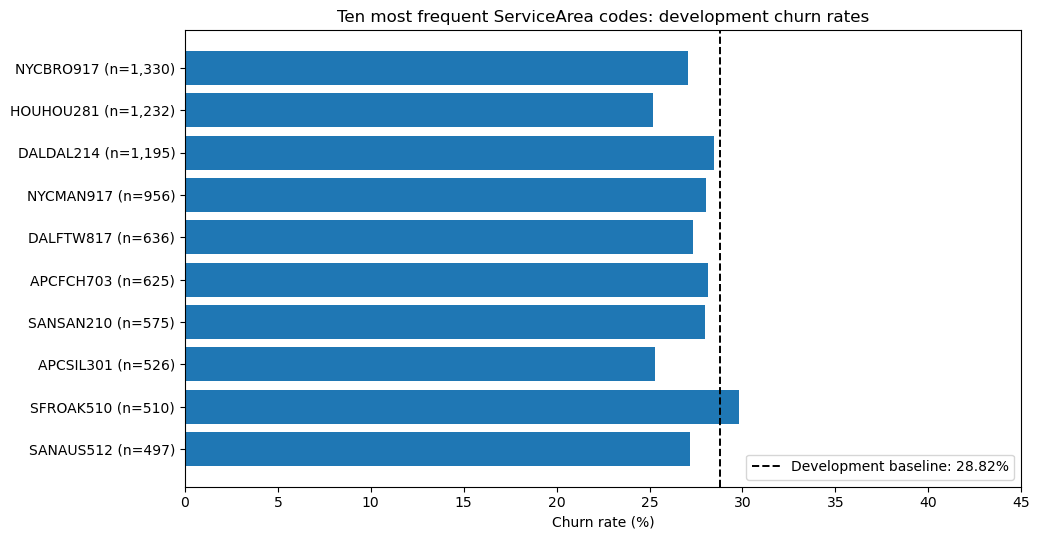

In [41]:
# How many customers each ServiceArea code has, and churn in the ten largest areas.
service_area = X_dev["ServiceArea"].astype("string").fillna("<Missing>")
service_counts = service_area.value_counts()
service_summary = pd.DataFrame(
    [
        {
            "Measure": "Distinct nonmissing ServiceArea codes",
            "Value": X_dev["ServiceArea"].nunique(dropna=True),
        },
        {
            "Measure": "Customers with missing ServiceArea",
            "Value": int(X_dev["ServiceArea"].isna().sum()),
        },
        {
            "Measure": "Codes with fewer than 20 development customers",
            "Value": int((service_counts < 20).sum()),
        },
        {
            "Measure": "Customers in codes with fewer than 20 records",
            "Value": int(service_counts[service_counts < 20].sum()),
        },
        {
            "Measure": "Codes with fewer than 50 development customers",
            "Value": int((service_counts < 50).sum()),
        },
    ]
)
display(service_summary)

service_churn = (
    pd.DataFrame({"ServiceArea": service_area, "Churn": y_dev})
    .groupby("ServiceArea")["Churn"]
    .agg(N="size", Churn_N="sum", Churn_rate="mean")
)
top_areas = service_counts.head(10).index
service_top10 = service_churn.loc[top_areas].reset_index()
service_top10["Churn_rate_pct"] = 100 * service_top10["Churn_rate"]
service_top10["Delta_vs_baseline_pp"] = service_top10["Churn_rate_pct"] - DEV_CHURN_PCT
display(
    service_top10[["ServiceArea", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]].round(
        2
    )
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ypos = np.arange(len(service_top10))
ax.barh(ypos, service_top10["Churn_rate_pct"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [f"{name} (n={n:,})" for name, n in zip(service_top10["ServiceArea"], service_top10["N"])]
)
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(45, float(service_top10["Churn_rate_pct"].max()) + 6))
ax.set_title("Ten most frequent ServiceArea codes: development churn rates")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The development data contains **729 service-area codes** plus 21 missing values. **434 codes have fewer than 20 customers** (2,441 customers in total), so a separate column for each code would rest on very little data. The ten largest areas have churn rates between **25.16%** and **29.80%**, all close to the average.

### 4.11 Retention Features and the Risk of Leakage

A feature can be strongly related to churn yet unusable for prediction if it is recorded *after* the point at which a customer would be scored. A retention call is the obvious example: a customer may call the retention team because they have already decided to leave, so the call would reveal the answer rather than help to predict it.

The documentation describes `RetentionCalls` as the "number of calls previously made to retention team" and `RetentionOffersAccepted` as the "number of previous retention offers accepted", but it gives no dates. It is therefore not possible to tell whether these contacts happened well before the observation date or close to the churn event.

**Decision:** as a precaution, **the three retention fields are excluded from the main models** and should be tested separately. The measurement window of the percentage-change fields is also undocumented, which is a limitation.

In [42]:
# What would have to be known about each time-sensitive feature before using it.
RETENTION_FEATURES_UNVERIFIED = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]
assert set(RETENTION_FEATURES_UNVERIFIED).issubset(X_dev.columns)

feature_timing_review = pd.DataFrame(
    [
        {
            "Feature": "RetentionCalls",
            "What_it_records": "Number of retention-related calls",
            "What_must_be_verified": "Call dates relative to scoring and churn outcome",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "RetentionOffersAccepted",
            "What_it_records": "Accepted retention offers",
            "What_must_be_verified": "Offer and acceptance dates; whether offer follows churn intent",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "MadeCallToRetentionTeam",
            "What_it_records": "Whether the customer contacted the retention team",
            "What_must_be_verified": "Contact timing and triggering event",
            "Evidence_in_files": "No event dates / cutoff definition",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
        },
        {
            "Feature": "PercChangeMinutes / PercChangeRevenues",
            "What_it_records": "Change in usage / revenue over an unspecified interval",
            "What_must_be_verified": "Observation window and whether it precedes churn",
            "Evidence_in_files": "No dated observation window",
            "Status": "Timing unverified",
            "Provisional_primary_policy": "Review observation window before modelling",
        },
    ]
)
display(feature_timing_review)

,Feature,What_it_records,What_must_be_verified,Evidence_in_files,Status,Provisional_primary_policy
0,RetentionCalls,Number of retention-related calls,Call dates relative to scoring and churn outcome,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
1,RetentionOffersAccepted,Accepted retention offers,Offer and acceptance dates; whether offer foll...,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
2,MadeCallToRetentionTeam,Whether the customer contacted the retention team,Contact timing and triggering event,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
3,PercChangeMinutes / PercChangeRevenues,Change in usage / revenue over an unspecified ...,Observation window and whether it precedes churn,No dated observation window,Timing unverified,Review observation window before modelling


,Observed_indicator,Flagged_N,Flagged_%,Flagged_churn_%,Not_flagged_churn_%,Delta_vs_baseline_pp
0,RetentionCalls > 0,1402,3.43,44.86,28.25,16.05
1,RetentionOffersAccepted > 0,711,1.74,42.33,28.58,13.52
2,MadeCallToRetentionTeam = Yes,1402,3.43,44.86,28.25,16.05


RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development: True


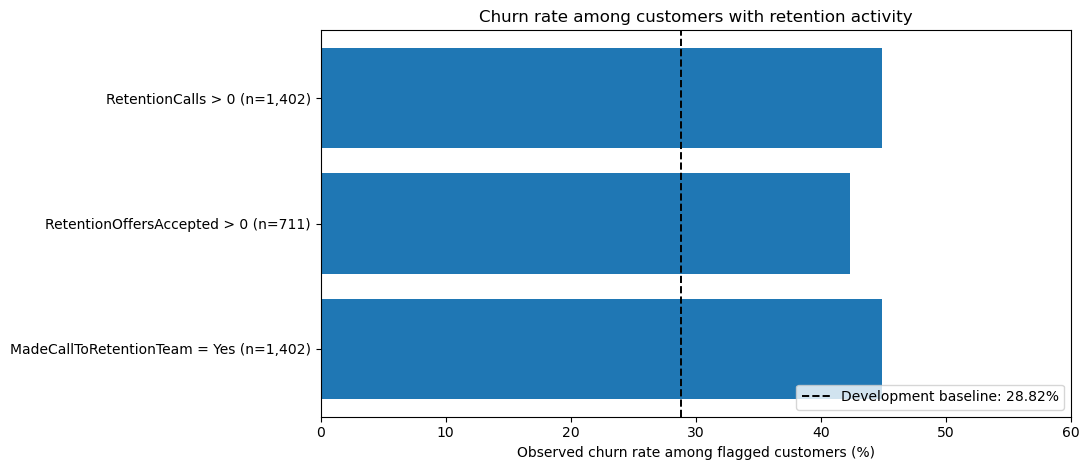

In [43]:
# Churn rate among customers with any retention-team activity.
retention_flags = {
    "RetentionCalls > 0": X_dev["RetentionCalls"].gt(0),
    "RetentionOffersAccepted > 0": X_dev["RetentionOffersAccepted"].gt(0),
    "MadeCallToRetentionTeam = Yes": X_dev["MadeCallToRetentionTeam"].eq("Yes"),
}
retention_rows = []
for label, flag in retention_flags.items():
    n_flagged = int(flag.sum())
    retention_rows.append(
        {
            "Observed_indicator": label,
            "Flagged_N": n_flagged,
            "Flagged_%": 100 * flag.mean(),
            "Flagged_churn_%": 100 * y_dev[flag].mean(),
            "Not_flagged_churn_%": 100 * y_dev[~flag].mean(),
            "Delta_vs_baseline_pp": 100 * y_dev[flag].mean() - DEV_CHURN_PCT,
        }
    )
retention_churn_summary = pd.DataFrame(retention_rows)
display(retention_churn_summary.round(2))

retention_call_indicator_matches = bool(
    X_dev["RetentionCalls"].gt(0).equals(X_dev["MadeCallToRetentionTeam"].eq("Yes"))
)
print(
    "RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development:",
    retention_call_indicator_matches,
)

fig, ax = plt.subplots(figsize=(11, 4.8))
ypos = np.arange(len(retention_churn_summary))
ax.barh(ypos, retention_churn_summary["Flagged_churn_%"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels(
    [
        f"{label} (n={n:,})"
        for label, n in zip(
            retention_churn_summary["Observed_indicator"], retention_churn_summary["Flagged_N"]
        )
    ]
)
ax.invert_yaxis()
ax.set_xlim(0, max(60, float(retention_churn_summary["Flagged_churn_%"].max()) + 6))
ax.set_xlabel("Observed churn rate among flagged customers (%)")
ax.set_title("Churn rate among customers with retention activity")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Customers who called the retention team churn at **44.86%** (1,402 customers) against 28.25% for everyone else, and those who accepted a retention offer at **42.33%** (711). `MadeCallToRetentionTeam = Yes` identifies exactly the same 1,402 customers as `RetentionCalls > 0`, so the two fields duplicate each other. The strong link with churn is what makes the timing question important: if these contacts happen once a customer has decided to leave, they would inflate the measured accuracy without being available when a real prediction is made.

### 4.12 EDA Summary and Implications for Modelling

In [44]:
# Summary of the main EDA findings and what they imply for modelling.
eda_findings = pd.DataFrame(
    [
        {
            "Observation": "Development churn prevalence",
            "Evidence": f"{DEV_CHURN_PCT:.2f}% churn ({int(y_dev.sum()):,}/{len(y_dev):,})",
            "Implication": "Use this baseline on subgroup plots; evaluate beyond accuracy",
        },
        {
            "Observation": "Numerical skew and excess zeros",
            "Evidence": (
                f"RoamingCalls zero for {100*X_dev['RoamingCalls'].eq(0).mean():.1f}%; "
                f"CustomerCareCalls zero for {100*X_dev['CustomerCareCalls'].eq(0).mean():.1f}%"
            ),
            "Implication": "Review scaling and robust representations within training folds",
        },
        {
            "Observation": "Usage differs by churn outcome",
            "Evidence": (
                f"Median MonthlyMinutes: No={X_dev.loc[y_dev==0,'MonthlyMinutes'].median():.0f}; "
                f"Yes={X_dev.loc[y_dev==1,'MonthlyMinutes'].median():.0f}"
            ),
            "Implication": "Investigate usage patterns with leakage-safe model comparisons",
        },
        {
            "Observation": "Equipment age differs by churn outcome",
            "Evidence": (
                f"Median CurrentEquipmentDays: No={X_dev.loc[y_dev==0,'CurrentEquipmentDays'].median():.0f}; "
                f"Yes={X_dev.loc[y_dev==1,'CurrentEquipmentDays'].median():.0f}"
            ),
            "Implication": "Consider nonlinear relationships; do not infer causation",
        },
        {
            "Observation": "Some missingness is associated with churn",
            "Evidence": (
                f"PercChangeMinutes null: "
                f"{100*y_dev[X_dev['PercChangeMinutes'].isna()].mean():.2f}% churn "
                f"(n={int(X_dev['PercChangeMinutes'].isna().sum())})"
            ),
            "Implication": "Evaluate imputation and optional missingness indicators within CV",
        },
        {
            "Observation": "High-cardinality service codes",
            "Evidence": (
                f"{X_dev['ServiceArea'].nunique()} nonmissing ServiceArea codes; "
                f"{int((service_counts < 20).sum())} categories have <20 rows"
            ),
            "Implication": "Plan rare/unseen-category handling for the categorical encoder",
        },
        {
            "Observation": "Retention timing cannot be verified",
            "Evidence": "Retention indicators associated with churn; no event timestamps",
            "Implication": "Conservative primary exclusion pending verification; development-only sensitivity study",
        },
    ]
)
display(eda_findings)

,Observation,Evidence,Implication
0,Development churn prevalence,"28.82% churn (11,769/40,837)",Use this baseline on subgroup plots; evaluate ...
1,Numerical skew and excess zeros,RoamingCalls zero for 68.7%; CustomerCareCalls...,Review scaling and robust representations with...
2,Usage differs by churn outcome,Median MonthlyMinutes: No=381; Yes=331,Investigate usage patterns with leakage-safe m...
3,Equipment age differs by churn outcome,Median CurrentEquipmentDays: No=310; Yes=367,Consider nonlinear relationships; do not infer...
4,Some missingness is associated with churn,PercChangeMinutes null: 56.90% churn (n=290),Evaluate imputation and optional missingness i...
5,High-cardinality service codes,729 nonmissing ServiceArea codes; 434 categori...,Plan rare/unseen-category handling for the cat...
6,Retention timing cannot be verified,Retention indicators associated with churn; no...,Conservative primary exclusion pending verific...


The exploration shapes the rest should be -> The skewed, zero-heavy usage features and the strong scale differences call for standardisation in Logistic Regression and suggest trying a log transform. The non-linear patterns in equipment age, tenure and usage favour including a tree-based model. The link between missingness and churn justifies missingness indicators. Finally, the timing uncertainty around the retention fields leads to their exclusion from the main models. All of these are associations in historical data, so they guide the modelling choices rather than explain why customers leave.

## 5. Data Preparation and Leakage-Safe Preprocessing

This section turns the audit and EDA findings into a reproducible preprocessing pipeline. The main design rule is that anything *learned* from the data, such as an imputation median, a scaling parameter or the list of known categories, is learned from training data only and then applied unchanged to validation or test data.

Preprocessing is divided into two kinds of step:

- **Structural corrections** apply a fixed rule to each value on its own, for example converting a handset price from text to a number, or marking a negative number of equipment days as missing. They learn nothing from other customers, so they cannot leak information.
- **Learned transformations** compute something from the data, for example the median used to fill missing values, the mean and standard deviation used for scaling, or which categories exist. These are fitted inside each cross-validation training fold and only then applied to the corresponding validation fold.

Both kinds of step live inside a scikit-learn `Pipeline`, so the whole sequence is refitted automatically every time a model is trained. The table summarises the plan.

In [45]:
from IPython.display import display
from sklearn import __version__ as sklearn_version

# Overview of the preprocessing decisions and how each one avoids leakage.
preprocessing_plan = pd.DataFrame(
    [
        (
            "Feature eligibility",
            "Exclude 3 retention-event fields from primary inputs",
            "Policy defined before fitting",
        ),
        (
            "Structural cleaning",
            "Parse HandsetPrice; mask negative equipment days",
            "Deterministic, inside pipeline",
        ),
        (
            "Numeric missingness",
            "Training-fold median + explicit missingness flags",
            "Learned inside each CV training fold",
        ),
        (
            "Categorical missingness",
            "Preserve explicit Unknown; impute actual null as Missing",
            "Learned inside each CV training fold",
        ),
        (
            "Numerical scaling",
            "StandardScaler for Logistic Regression; none for Random Forest",
            "Learned inside each CV training fold",
        ),
        (
            "Categorical encoding",
            "One-hot; infrequent bin for ServiceArea",
            "Learned inside each CV training fold",
        ),
        (
            "Extreme values",
            "Retain valid extremes; no blanket IQR filtering",
            "No target-guided trimming",
        ),
    ],
    columns=["Decision area", "Planned treatment", "How leakage is avoided"],
)
display(preprocessing_plan)
print("scikit-learn version:", sklearn_version)

,Decision area,Planned treatment,How leakage is avoided
0,Feature eligibility,Exclude 3 retention-event fields from primary ...,Policy defined before fitting
1,Structural cleaning,Parse HandsetPrice; mask negative equipment days,"Deterministic, inside pipeline"
2,Numeric missingness,Training-fold median + explicit missingness flags,Learned inside each CV training fold
3,Categorical missingness,Preserve explicit Unknown; impute actual null ...,Learned inside each CV training fold
4,Numerical scaling,StandardScaler for Logistic Regression; none f...,Learned inside each CV training fold
5,Categorical encoding,One-hot; infrequent bin for ServiceArea,Learned inside each CV training fold
6,Extreme values,Retain valid extremes; no blanket IQR filtering,No target-guided trimming


scikit-learn version: 1.7.2


Each data-quality issue from the audit has a matching treatment, and every learned step is confined to training data.

### 5.2 Feature Eligibility: the Main Feature Set

A churn model should only use information that would be available at the time a customer is scored. Because the time at which the retention contacts were recorded cannot be confirmed, `RetentionCalls`, `RetentionOffersAccepted` and `MadeCallToRetentionTeam` are excluded from the main feature set. `CustomerID` and `Churn` were already removed. The two percentage-change fields stay in, with their undocumented measurement window noted as a limitation.

In [46]:
# Main feature set: all candidate predictors except the three retention fields (Section 4.11).
RETENTION_EXCLUSIONS = ("RetentionCalls", "RetentionOffersAccepted", "MadeCallToRetentionTeam")
assert set(RETENTION_EXCLUSIONS).issubset(X_dev.columns)
PRIMARY_FEATURE_COLS = [col for col in X_dev.columns if col not in RETENTION_EXCLUSIONS]
X_dev_primary = X_dev.loc[:, PRIMARY_FEATURE_COLS].copy()

feature_eligibility = pd.DataFrame(
    [
        ("CustomerID", "Identifier", "Excluded previously", "Not a behavioural predictor"),
        ("Churn", "Target", "Excluded previously", "Outcome, never an input"),
        (
            "RetentionCalls",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "RetentionOffersAccepted",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "MadeCallToRetentionTeam",
            "Retention activity",
            "Excluded from main model",
            "Prediction-time availability unverified",
        ),
        (
            "PercChangeMinutes",
            "Usage change",
            "Included with limitation",
            "Observation window not documented",
        ),
        (
            "PercChangeRevenues",
            "Revenue change",
            "Included with limitation",
            "Observation window not documented",
        ),
        (
            "Other candidate predictors",
            "Customer/usage/service fields",
            "Included provisionally",
            "Used as recorded",
        ),
    ],
    columns=["Feature(s)", "Role", "Policy", "Reason / limitation"],
)
display(feature_eligibility)
print("Original candidate predictors:", X_dev.shape[1])
print("Primary predictors:", X_dev_primary.shape[1])
print("Excluded retention predictors:", len(RETENTION_EXCLUSIONS))
assert X_dev_primary.shape == (len(X_dev), 53)
assert X_dev_primary.index.equals(y_dev.index)
assert set(PRIMARY_FEATURE_COLS).isdisjoint(RETENTION_EXCLUSIONS)
assert {"Churn", "CustomerID"}.isdisjoint(PRIMARY_FEATURE_COLS)
assert X_dev_primary.columns.is_unique

,Feature(s),Role,Policy,Reason / limitation
0,CustomerID,Identifier,Excluded previously,Not a behavioural predictor
1,Churn,Target,Excluded previously,"Outcome, never an input"
2,RetentionCalls,Retention activity,Excluded from main model,Prediction-time availability unverified
3,RetentionOffersAccepted,Retention activity,Excluded from main model,Prediction-time availability unverified
4,MadeCallToRetentionTeam,Retention activity,Excluded from main model,Prediction-time availability unverified
5,PercChangeMinutes,Usage change,Included with limitation,Observation window not documented
6,PercChangeRevenues,Revenue change,Included with limitation,Observation window not documented
7,Other candidate predictors,Customer/usage/service fields,Included provisionally,Used as recorded


Original candidate predictors: 56
Primary predictors: 53
Excluded retention predictors: 3


The main modelling data therefore has **40,837 customers and 53 predictors**. The three retention fields are excluded as a precaution, not because they lack predictive value: adding them would slightly raise accuracy.

### 5.3 Structural Corrections

Three columns are stored in a form that does not match their meaning. A small custom transformer, `Cell2CellStructuralCleaner`, fixes them value by value:

- **`HandsetPrice`:** known prices are converted to numbers and `Unknown` becomes missing. The documentation confirms that unknown handset prices were originally coded as missing ("Handset price (0=>missing)").
- **`CurrentEquipmentDays`:** negative values are set to missing, because a number of days since purchase cannot be negative. The customer is kept.
- **`IncomeGroup`:** the integer codes 0–9 are treated as categories rather than as a continuous number. According to the documentation, code 0 means income is missing, so keeping it as its own category lets the model learn whether missing income matters.

The cleaner runs as the first step of every pipeline.

In [47]:
from sklearn.base import BaseEstimator, TransformerMixin


class Cell2CellStructuralCleaner(TransformerMixin, BaseEstimator):
    """Fix three columns stored in the wrong form.

    Row-by-row rules only, so nothing is learned from other customers:
    - HandsetPrice: text prices become numbers and "Unknown" becomes missing.
    - CurrentEquipmentDays: negative day counts become missing.
    - IncomeGroup: integer codes become categories (code 0 means income missing).
    """

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellStructuralCleaner expects a pandas DataFrame.")
        required = {"HandsetPrice", "CurrentEquipmentDays", "IncomeGroup"}
        missing = required - set(X.columns)
        if missing:
            raise ValueError(f"Missing required feature columns: {sorted(missing)}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellStructuralCleaner expects a pandas DataFrame.")
        required = {"HandsetPrice", "CurrentEquipmentDays", "IncomeGroup"}
        if not required.issubset(X.columns):
            raise ValueError(f"Missing structural columns: {sorted(required - set(X.columns))}")
        cleaned = X.copy()

        # HandsetPrice: numbers are parsed; anything other than a number or 'Unknown' raises an error.
        price_text = cleaned["HandsetPrice"].astype("string").str.strip()
        parsed_price = pd.to_numeric(price_text, errors="coerce")
        allowed_unknown = price_text.str.casefold().eq("unknown").fillna(False)
        unexpected = (
            price_text.notna() & price_text.ne("") & ~allowed_unknown & parsed_price.isna()
        ).fillna(False)
        if unexpected.any():
            bad = price_text.loc[unexpected].unique().tolist()
            raise ValueError(f"Unexpected HandsetPrice token(s): {bad[:5]}")
        cleaned["HandsetPrice"] = parsed_price.astype("float64")

        # A number of days since purchase cannot be negative, so negative values become missing.
        equipment_days = pd.to_numeric(cleaned["CurrentEquipmentDays"], errors="raise")
        cleaned["CurrentEquipmentDays"] = equipment_days.mask(equipment_days < 0, np.nan)

        # IncomeGroup is a code, not a quantity; 0 (income missing) stays as its own category.
        group_as_text = cleaned["IncomeGroup"].astype("string")
        cleaned["IncomeGroup"] = group_as_text.astype(object).where(group_as_text.notna(), np.nan)
        return cleaned

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        return self.feature_names_in_


# Preview the corrections on the development data. The models apply the cleaner inside their pipelines.
clean_preview = Cell2CellStructuralCleaner().transform(X_dev_primary)
structural_corrections = pd.DataFrame(
    [
        (
            "HandsetPrice",
            str(X_dev_primary["HandsetPrice"].dtype),
            str(clean_preview["HandsetPrice"].dtype),
            int(X_dev_primary["HandsetPrice"].eq("Unknown").sum()),
            int(clean_preview["HandsetPrice"].isna().sum()),
            "Numeric strings -> price; Unknown -> missing",
        ),
        (
            "CurrentEquipmentDays",
            str(X_dev_primary["CurrentEquipmentDays"].dtype),
            str(clean_preview["CurrentEquipmentDays"].dtype),
            int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()),
            int(clean_preview["CurrentEquipmentDays"].isna().sum()),
            "Negative duration -> missing; positive/zero unchanged",
        ),
        (
            "IncomeGroup",
            str(X_dev_primary["IncomeGroup"].dtype),
            str(clean_preview["IncomeGroup"].dtype),
            int(X_dev_primary["IncomeGroup"].eq(0).sum()),
            int(clean_preview["IncomeGroup"].isna().sum()),
            "Integer category codes -> text labels; zero retained",
        ),
    ],
    columns=[
        "Feature",
        "Before dtype",
        "After dtype",
        "Flagged before",
        "Missing after",
        "Correction / interpretation",
    ],
)
display(structural_corrections)
assert pd.api.types.is_numeric_dtype(clean_preview["HandsetPrice"])
assert (
    clean_preview["HandsetPrice"].notna().sum() == X_dev_primary["HandsetPrice"].ne("Unknown").sum()
)
assert not clean_preview["CurrentEquipmentDays"].lt(0).any()
assert X_dev_primary["HandsetPrice"].dtype == object  # Original input unchanged
assert int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()) > 0

,Feature,Before dtype,After dtype,Flagged before,Missing after,Correction / interpretation
0,HandsetPrice,object,float64,23214,23214,Numeric strings -> price; Unknown -> missing
1,CurrentEquipmentDays,float64,float64,55,56,Negative duration -> missing; positive/zero un...
2,IncomeGroup,int64,object,10280,0,Integer category codes -> text labels; zero re...


After cleaning, `HandsetPrice` is numeric with **23,214** missing values (the former `Unknown` entries), `CurrentEquipmentDays` has **56** missing values (55 corrected negatives plus one original blank), and `IncomeGroup` is categorical. No customer rows are removed, and the original development data remains unchanged.

### 5.4 Missing Values

Dropping customers with any missing value would discard most of the data, because `HandsetPrice` alone is missing for 57% of customers. Instead, missing **numerical** values are filled with the **median** of the training fold. The median is less affected than the mean by the skewed distributions.

Because the EDA showed that missingness itself is linked to churn, **binary missingness indicators** (`MissingIndicator`) are also added, so that the model knows which values were filled in. For **categorical** features, true nulls become a separate `Missing` category, while recorded answers such as `Unknown` keep their own category.

**Assumption:** median imputation assumes that a missing value is best replaced by a typical value. The indicators allow the model to treat filled-in customers differently if missingness turns out to be informative. The table shows how much is missing after the structural corrections.

In [48]:
# Missing values after the structural corrections, and how each will be handled.
missing_summary = pd.DataFrame(
    {
        "Feature": clean_preview.columns,
        "Missing_N": clean_preview.isna().sum().to_numpy(),
        "Missing_%": (100 * clean_preview.isna().mean()).to_numpy(),
    }
)
missing_summary = (
    missing_summary.query("Missing_N > 0")
    .sort_values(["Missing_N", "Feature"], ascending=[False, True])
    .reset_index(drop=True)
)
missing_summary["Planned_treatment"] = missing_summary["Feature"].apply(
    lambda col: (
        "Categorical Missing token + one-hot"
        if col == "ServiceArea"
        else "Median imputation + missingness indicator"
    )
)
display(missing_summary.round(2))
print("Features requiring treatment:", len(missing_summary))
print(
    "Total missing predictor cells after structural corrections:",
    int(clean_preview.isna().sum().sum()),
)
print(
    "MaritalStatus = Unknown kept as a category:",
    int(clean_preview["MaritalStatus"].eq("Unknown").sum()),
)
print(
    "Homeownership = Unknown kept as a category:",
    int(clean_preview["Homeownership"].eq("Unknown").sum()),
)

,Feature,Missing_N,Missing_%,Planned_treatment
0,HandsetPrice,23214,56.85,Median imputation + missingness indicator
1,AgeHH1,716,1.75,Median imputation + missingness indicator
2,AgeHH2,716,1.75,Median imputation + missingness indicator
3,PercChangeMinutes,290,0.71,Median imputation + missingness indicator
4,PercChangeRevenues,290,0.71,Median imputation + missingness indicator
5,DirectorAssistedCalls,120,0.29,Median imputation + missingness indicator
6,MonthlyMinutes,120,0.29,Median imputation + missingness indicator
7,MonthlyRevenue,120,0.29,Median imputation + missingness indicator
8,OverageMinutes,120,0.29,Median imputation + missingness indicator
9,RoamingCalls,120,0.29,Median imputation + missingness indicator


Features requiring treatment: 15
Total missing predictor cells after structural corrections: 26025
MaritalStatus = Unknown kept as a category: 15752
Homeownership = Unknown kept as a category: 13690


Fifteen columns need imputation. `HandsetPrice` dominates (56.85% missing); all others are below 2%. Several columns are missing for exactly the same customers (for example the six billing and usage fields), a point that is examined again.

### 5.5 Invalid Values and Outliers

Only values that are impossible are corrected. Large usage figures, negative percentage changes, small negative revenue amounts (possible credits) and zero household ages are kept, because the documentation gives no reason to treat them as errors and removing them could discard real behaviour. The tables record the decision for each flagged case.

In [49]:
# Decision for each kind of suspicious value; only negative equipment days are corrected.
invalid_value_review = pd.DataFrame(
    [
        (
            "CurrentEquipmentDays",
            int(X_dev_primary["CurrentEquipmentDays"].lt(0).sum()),
            "Negative elapsed duration",
            "Convert to missing; fold median + flag",
        ),
        (
            "MonthlyRevenue",
            int(X_dev_primary["MonthlyRevenue"].lt(0).sum()),
            "Could be credits/adjustments",
            "Keep (possible credit or adjustment)",
        ),
        (
            "TotalRecurringCharge",
            int(X_dev_primary["TotalRecurringCharge"].lt(0).sum()),
            "Could be credits/adjustments",
            "Keep (possible credit or adjustment)",
        ),
        (
            "PercChangeMinutes",
            int(X_dev_primary["PercChangeMinutes"].lt(0).sum()),
            "Negative change may be meaningful",
            "Keep (decreases are valid)",
        ),
        (
            "PercChangeRevenues",
            int(X_dev_primary["PercChangeRevenues"].lt(0).sum()),
            "Negative change may be meaningful",
            "Keep (decreases are valid)",
        ),
        (
            "AgeHH1",
            int(X_dev_primary["AgeHH1"].eq(0).sum()),
            "Zero may be a coded value",
            "Keep as recorded",
        ),
        (
            "AgeHH2",
            int(X_dev_primary["AgeHH2"].eq(0).sum()),
            "Zero may be a coded value",
            "Keep as recorded",
        ),
    ],
    columns=["Feature", "Flagged development rows", "Evidence / uncertainty", "Primary treatment"],
)
display(invalid_value_review)

outlier_rows = []
for col in ["MonthlyMinutes", "RoamingCalls", "CustomerCareCalls", "OverageMinutes"]:
    observed = X_dev_primary[col].dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = int(((observed < q1 - 1.5 * iqr) | (observed > q3 + 1.5 * iqr)).sum())
    outlier_rows.append(
        {"Feature": col, "IQR_flagged_N": flagged, "Treatment": "Keep (plausible heavy users)"}
    )
display(pd.DataFrame(outlier_rows))
assert X_dev_primary.shape[0] == clean_preview.shape[0]  # No row deletion

,Feature,Flagged development rows,Evidence / uncertainty,Primary treatment
0,CurrentEquipmentDays,55,Negative elapsed duration,Convert to missing; fold median + flag
1,MonthlyRevenue,3,Could be credits/adjustments,Keep (possible credit or adjustment)
2,TotalRecurringCharge,8,Could be credits/adjustments,Keep (possible credit or adjustment)
3,PercChangeMinutes,21502,Negative change may be meaningful,Keep (decreases are valid)
4,PercChangeRevenues,22690,Negative change may be meaningful,Keep (decreases are valid)
5,AgeHH1,11180,Zero may be a coded value,Keep as recorded
6,AgeHH2,20926,Zero may be a coded value,Keep as recorded


,Feature,IQR_flagged_N,Treatment
0,MonthlyMinutes,2023,Keep (plausible heavy users)
1,RoamingCalls,7938,Keep (plausible heavy users)
2,CustomerCareCalls,5361,Keep (plausible heavy users)
3,OverageMinutes,4707,Keep (plausible heavy users)


Thousands of usage values fall outside the IQR fences (for example 7,938 `RoamingCalls` values), but they describe genuinely heavy users. No rows are removed and no values are capped. Negative equipment days are the only correction.

### 5.6 Feature Groups and Scaling

Both algorithms receive the same 53 predictors, but numerical preprocessing differs to suit each one. **Logistic Regression** gets median imputation followed by `StandardScaler`, because its single L2 penalty treats all coefficients alike and therefore needs features on comparable scales. **Random Forest** gets median imputation only, because tree splits depend on the order of values, not their scale. Missingness indicators are kept in a separate branch so that these 0/1 flags are not standardised.

In [50]:
# Assign each predictor to a preprocessing branch by meaning, not by stored type:
# IncomeGroup is a category code, and HandsetPrice becomes numeric after cleaning.
NUMERIC_FEATURES = [
    c for c in X_dev_primary.select_dtypes(include=np.number).columns if c != "IncomeGroup"
] + ["HandsetPrice"]
SERVICE_AREA_FEATURES = ["ServiceArea"]
CATEGORICAL_FEATURES = [
    c for c in PRIMARY_FEATURE_COLS if c not in set(NUMERIC_FEATURES + SERVICE_AREA_FEATURES)
]

role_sets = [set(NUMERIC_FEATURES), set(CATEGORICAL_FEATURES), set(SERVICE_AREA_FEATURES)]
assert len(set.union(*role_sets)) == len(PRIMARY_FEATURE_COLS)
assert sum(map(len, role_sets)) == len(PRIMARY_FEATURE_COLS)
assert set.union(*role_sets) == set(PRIMARY_FEATURE_COLS)
assert "HandsetPrice" in NUMERIC_FEATURES
assert "IncomeGroup" in CATEGORICAL_FEATURES
assert "CreditRating" in CATEGORICAL_FEATURES

feature_type_summary = pd.DataFrame(
    [
        (
            "Numerical",
            len(NUMERIC_FEATURES),
            "Median + missingness flags; LR standardises, RF does not",
        ),
        (
            "Nominal/coded categorical",
            len(CATEGORICAL_FEATURES),
            "Constant-missing imputation + one-hot",
        ),
        (
            "High-cardinality ServiceArea",
            len(SERVICE_AREA_FEATURES),
            "Missing category + infrequent-aware one-hot",
        ),
    ],
    columns=["Semantic feature group", "Original feature count", "Pipeline treatment"],
)
display(feature_type_summary)
print("Numerical feature examples:", NUMERIC_FEATURES[:8])
print("Categorical feature examples:", CATEGORICAL_FEATURES[:8])

,Semantic feature group,Original feature count,Pipeline treatment
0,Numerical,32,"Median + missingness flags; LR standardises, R..."
1,Nominal/coded categorical,20,Constant-missing imputation + one-hot
2,High-cardinality ServiceArea,1,Missing category + infrequent-aware one-hot


Numerical feature examples: ['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues']
Categorical feature examples: ['ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers']


The 53 predictors fall into **32 numerical features**, **20 categorical features** and the high-cardinality `ServiceArea`. Each group has its own transformation path.

### 5.7 Categorical Encoding

All categorical features, including binary Yes/No flags, `CreditRating` and `IncomeGroup`, are **one-hot encoded**. One-hot encoding avoids imposing an artificial numerical distance between categories. This matters for `CreditRating`: EDA showed that churn does not change steadily across its levels, so coding it as 1–7 would force Logistic Regression to assume a straight-line effect. Recorded `Unknown` answers keep their own column. Categories that appear only in validation or test data are ignored (`handle_unknown='ignore'`), so new values cannot break the pipeline.

In [51]:
# How each group of categorical features is encoded, and why.
encoding_policy = pd.DataFrame(
    [
        (
            "HandsetWebCapable, ChildrenInHH, etc.",
            "Binary categories",
            "One-hot",
            "No artificial numerical distance",
        ),
        (
            "MaritalStatus",
            "Yes / No / Unknown",
            "One-hot; keep Unknown",
            "Unknown is an explicit response",
        ),
        (
            "Homeownership",
            "Known / Unknown",
            "One-hot; keep Unknown",
            "Known is not equivalent to owns-home",
        ),
        (
            "CreditRating",
            "Ordered-looking labels 1–7",
            "One-hot initially",
            "Avoid unverified linear/equal-distance assumption",
        ),
        (
            "IncomeGroup",
            "Integer-coded categories 0–9",
            "Convert code to text; one-hot",
            "Code 0 (income missing) kept as its own category",
        ),
        ("PrizmCode, Occupation", "Nominal categories", "One-hot", "No natural numerical ordering"),
        (
            "ServiceArea",
            "Hundreds of location codes",
            "Rare-category one-hot (next subsection)",
            "Control dimensionality and unseen codes",
        ),
    ],
    columns=["Feature(s)", "Observed semantic type", "Primary encoding", "Reason"],
)
display(encoding_policy)

,Feature(s),Observed semantic type,Primary encoding,Reason
0,"HandsetWebCapable, ChildrenInHH, etc.",Binary categories,One-hot,No artificial numerical distance
1,MaritalStatus,Yes / No / Unknown,One-hot; keep Unknown,Unknown is an explicit response
2,Homeownership,Known / Unknown,One-hot; keep Unknown,Known is not equivalent to owns-home
3,CreditRating,Ordered-looking labels 1–7,One-hot initially,Avoid unverified linear/equal-distance assumption
4,IncomeGroup,Integer-coded categories 0–9,Convert code to text; one-hot,Code 0 (income missing) kept as its own category
5,"PrizmCode, Occupation",Nominal categories,One-hot,No natural numerical ordering
6,ServiceArea,Hundreds of location codes,Rare-category one-hot (next subsection),Control dimensionality and unseen codes


Both models receive the same categorical encoding, so any difference between them comes from the algorithm and the numerical scaling, not from how categories are represented.

### 5.8 Rare and Unseen Service Areas

With 729 codes, many used by only a handful of customers, one column per `ServiceArea` would add hundreds of nearly empty features. `ServiceArea` is therefore encoded with `OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist')`: codes with fewer than 20 customers in the **training fold** are merged into a single "infrequent" column, and codes never seen in training are mapped to that same column. The threshold of 20 is a practical choice that keeps each remaining area column backed by a reasonable number of customers; it is not chosen using churn rates.

In [52]:
# Frequency of service-area codes, showing why rare codes are grouped.
service_counts_dev = X_dev_primary["ServiceArea"].value_counts(dropna=True)
service_cardinality_summary = pd.DataFrame(
    [
        ("Distinct nonmissing service areas", int(service_counts_dev.size)),
        (
            "Areas with fewer than 20 development rows (diagnostic only)",
            int((service_counts_dev < 20).sum()),
        ),
        (
            "Customers in those low-frequency development areas",
            int(service_counts_dev[service_counts_dev < 20].sum()),
        ),
        ("Actual missing ServiceArea rows", int(X_dev_primary["ServiceArea"].isna().sum())),
        ("Minimum per-fold frequency for a separate encoded category", 20),
    ],
    columns=["Measure", "Value"],
)
display(service_cardinality_summary)
print("Which areas count as infrequent is decided separately within each training fold.")

,Measure,Value
0,Distinct nonmissing service areas,729
1,Areas with fewer than 20 development rows (dia...,434
2,Customers in those low-frequency development a...,2441
3,Actual missing ServiceArea rows,21
4,Minimum per-fold frequency for a separate enco...,20


Which areas count as infrequent is decided separately within each training fold.


In the development data, 434 of the 729 codes fall below the threshold. Which codes are merged is decided separately in every training fold, so the encoder never uses validation or test frequencies.

### 5.9 The Model Pipelines

All decisions are combined in a `ColumnTransformer` inside a `Pipeline`: structural cleaning, then the numerical, missingness, categorical and `ServiceArea` branches, then the classifier. Sparse output is kept sparse, so the hundreds of one-hot columns do not create a large dense matrix. The two pipelines differ only in numerical scaling and in the classifier. They are defined here but not yet trained.

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from scipy import sparse


# The scikit-learn version is printed in Section 5.1 and pinned in docs/requirements.txt.
def make_preprocessor(model_type):
    """Build the ColumnTransformer for one algorithm.

    Numerical features: median imputation (plus standard scaling for Logistic Regression).
    Missingness flags: one 0/1 column per numerical feature that had missing values in training.
    Categorical features: missing -> 'Missing', then one-hot encoding (unseen values ignored).
    ServiceArea: one-hot encoding with codes seen fewer than 20 times grouped as 'infrequent'.
    """
    if model_type not in {"logistic", "random_forest"}:
        raise ValueError("model_type must be 'logistic' or 'random_forest'")

    numerical_steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_type == "logistic":
        numerical_steps.append(("scaler", StandardScaler()))
    numerical_pipeline = Pipeline(numerical_steps)

    general_categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]
    )
    service_area_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    sparse_output=True,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numerical_pipeline, NUMERIC_FEATURES),
            (
                "missing_flags",
                MissingIndicator(features="missing-only", error_on_new=False),
                NUMERIC_FEATURES,
            ),
            ("categorical", general_categorical_pipeline, CATEGORICAL_FEATURES),
            ("service_area", service_area_pipeline, SERVICE_AREA_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True,
    )


def make_preprocessing_only(model_type):
    """Cleaning and preprocessing without a classifier (used to inspect the transformed data)."""
    return Pipeline(
        [
            ("structural_cleaning", Cell2CellStructuralCleaner()),
            ("preprocessor", make_preprocessor(model_type)),
        ]
    )


logistic_preprocessing = make_preprocessing_only("logistic")
rf_preprocessing = make_preprocessing_only("random_forest")

# Full pipelines (cleaning -> preprocessing -> classifier); they are fitted later, fold by fold.
logistic_pipeline = Pipeline(
    [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("preprocessor", make_preprocessor("logistic")),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
random_forest_pipeline = Pipeline(
    [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("preprocessor", make_preprocessor("random_forest")),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

pipeline_summary = pd.DataFrame(
    [
        (
            "Logistic Regression",
            "Median -> StandardScaler",
            "MissingIndicator",
            "One-hot + rare ServiceArea bin",
            "Not fitted",
        ),
        (
            "Random Forest",
            "Median only (no scaling)",
            "MissingIndicator",
            "One-hot + rare ServiceArea bin",
            "Not fitted",
        ),
    ],
    columns=[
        "Model",
        "Numerical treatment",
        "Missingness",
        "Categorical treatment",
        "Estimator status",
    ],
)
display(pipeline_summary)
print("Logistic pipeline steps:", list(logistic_pipeline.named_steps))
print("Random Forest pipeline steps:", list(random_forest_pipeline.named_steps))
assert not hasattr(logistic_pipeline.named_steps["classifier"], "classes_")
assert not hasattr(random_forest_pipeline.named_steps["classifier"], "classes_")

,Model,Numerical treatment,Missingness,Categorical treatment,Estimator status
0,Logistic Regression,Median -> StandardScaler,MissingIndicator,One-hot + rare ServiceArea bin,Not fitted
1,Random Forest,Median only (no scaling),MissingIndicator,One-hot + rare ServiceArea bin,Not fitted


Logistic pipeline steps: ['structural_cleaning', 'preprocessor', 'classifier']
Random Forest pipeline steps: ['structural_cleaning', 'preprocessor', 'classifier']


Both pipelines follow the same sequence, **structural cleaning → preprocessing → classifier**. Because the whole sequence is one object, cloning and refitting it in each fold automatically refits every learned step.

### 5.10 Demonstrating Fold-Safe Preprocessing

To show that the pipeline behaves as intended, only the preprocessing steps are fitted on one training fold and then applied to its validation fold. Two checks follow. First, the imputation median must come from the training fold alone. Second, category values that were never seen in training must be handled without error. For the second check, `ServiceArea` and `Occupation` in a *copy* of one validation row are replaced with made-up values.

In [54]:
# Fit the preprocessing steps (no classifier) on training fold 1 and apply them to its validation fold.
fold_train_positions, fold_valid_positions = next(cv.split(X_dev_primary, y_dev))
X_fold_train = X_dev_primary.iloc[fold_train_positions].copy()
X_fold_valid = X_dev_primary.iloc[fold_valid_positions].copy()
y_fold_train = y_dev.iloc[fold_train_positions].copy()
y_fold_valid = y_dev.iloc[fold_valid_positions].copy()
assert X_fold_train.index.is_unique and X_fold_valid.index.is_unique
assert set(X_fold_train.index).isdisjoint(set(X_fold_valid.index))
assert X_fold_train.index.equals(y_fold_train.index)
assert X_fold_valid.index.equals(y_fold_valid.index)

lr_fold_preprocessing = clone(logistic_preprocessing).fit(X_fold_train)
rf_fold_preprocessing = clone(rf_preprocessing).fit(X_fold_train)

X_fold_train_lr = lr_fold_preprocessing.transform(X_fold_train)
X_fold_valid_lr = lr_fold_preprocessing.transform(X_fold_valid)
X_fold_train_rf = rf_fold_preprocessing.transform(X_fold_train)
X_fold_valid_rf = rf_fold_preprocessing.transform(X_fold_valid)

lr_feature_names = lr_fold_preprocessing.named_steps["preprocessor"].get_feature_names_out()
rf_feature_names = rf_fold_preprocessing.named_steps["preprocessor"].get_feature_names_out()

# The imputer's median must equal the median of the training fold alone.
fold_train_median = float(X_fold_train["MonthlyRevenue"].median())
learned_median = float(
    lr_fold_preprocessing.named_steps["preprocessor"]
    .named_transformers_["numeric"]
    .named_steps["imputer"]
    .statistics_[NUMERIC_FEATURES.index("MonthlyRevenue")]
)
assert np.isclose(learned_median, fold_train_median)

fold_preprocessing_summary = pd.DataFrame(
    [
        (
            "CV training",
            "Logistic Regression",
            X_fold_train_lr.shape[0],
            X_fold_train_lr.shape[1],
            sparse.issparse(X_fold_train_lr),
        ),
        (
            "CV validation",
            "Logistic Regression",
            X_fold_valid_lr.shape[0],
            X_fold_valid_lr.shape[1],
            sparse.issparse(X_fold_valid_lr),
        ),
        (
            "CV training",
            "Random Forest",
            X_fold_train_rf.shape[0],
            X_fold_train_rf.shape[1],
            sparse.issparse(X_fold_train_rf),
        ),
        (
            "CV validation",
            "Random Forest",
            X_fold_valid_rf.shape[0],
            X_fold_valid_rf.shape[1],
            sparse.issparse(X_fold_valid_rf),
        ),
    ],
    columns=["Fold portion", "Pipeline", "Rows", "Encoded columns", "Sparse output"],
)
display(fold_preprocessing_summary)
print(
    f"MonthlyRevenue median: training fold={fold_train_median:.3f}, "
    f"learned imputer={learned_median:.3f}"
)
print("Training-fold churn rate:", f"{100*y_fold_train.mean():.2f}%")
print("Validation-fold churn rate:", f"{100*y_fold_valid.mean():.2f}%")

,Fold portion,Pipeline,Rows,Encoded columns,Sparse output
0,CV training,Logistic Regression,32669,371,True
1,CV validation,Logistic Regression,8168,371,True
2,CV training,Random Forest,32669,371,True
3,CV validation,Random Forest,8168,371,True


MonthlyRevenue median: training fold=48.525, learned imputer=48.525
Training-fold churn rate: 28.82%
Validation-fold churn rate: 28.82%


In [55]:
# Give a copy of one validation customer made-up category values never seen in training.
synthetic_unseen = X_fold_valid.iloc[[0]].copy()
synthetic_unseen.loc[:, "ServiceArea"] = "UNSEEN_SERVICE_AREA_FOR_CHECK"
synthetic_unseen.loc[:, "Occupation"] = "UNSEEN_OCCUPATION_FOR_CHECK"
assert "UNSEEN_SERVICE_AREA_FOR_CHECK" not in set(X_fold_train["ServiceArea"].dropna())
assert "UNSEEN_OCCUPATION_FOR_CHECK" not in set(X_fold_train["Occupation"].dropna())

unseen_lr = lr_fold_preprocessing.transform(synthetic_unseen)
unseen_rf = rf_fold_preprocessing.transform(synthetic_unseen)

# An unseen service area should be mapped to the 'infrequent' column.
service_infrequent = [
    (i, name)
    for i, name in enumerate(lr_feature_names)
    if name.startswith("service_area__") and "infrequent_sklearn" in name
]
assert len(service_infrequent) == 1, "Expected a fold-learned infrequent ServiceArea bin."
rare_idx, rare_name = service_infrequent[0]
rare_bin_value = float(unseen_lr[0, rare_idx])
assert rare_bin_value == 1.0

# An unseen occupation should give all zeros in the occupation columns (handle_unknown='ignore').
occupation_indices = [
    i for i, name in enumerate(lr_feature_names) if name.startswith("categorical__Occupation_")
]
assert len(occupation_indices) > 0
unknown_occupation_sum = float(unseen_lr[0, occupation_indices].sum())
assert unknown_occupation_sum == 0.0

unseen_category_checks = pd.DataFrame(
    [
        ("Unseen ServiceArea", "Mapped to fold-learned infrequent bin", rare_bin_value == 1),
        (
            "Unseen Occupation",
            "General one-hot block contains all zeros",
            unknown_occupation_sum == 0,
        ),
        (
            "Logistic transform",
            f"1 x {unseen_lr.shape[1]} encoded columns",
            unseen_lr.shape[1] == X_fold_valid_lr.shape[1],
        ),
        (
            "Random Forest transform",
            f"1 x {unseen_rf.shape[1]} encoded columns",
            unseen_rf.shape[1] == X_fold_valid_rf.shape[1],
        ),
    ],
    columns=["Check", "Observed behaviour", "Pass"],
)
display(unseen_category_checks)
assert unseen_category_checks["Pass"].all()
print("Unseen ServiceArea output feature:", rare_name)

,Check,Observed behaviour,Pass
0,Unseen ServiceArea,Mapped to fold-learned infrequent bin,True
1,Unseen Occupation,General one-hot block contains all zeros,True
2,Logistic transform,1 x 371 encoded columns,True
3,Random Forest transform,1 x 371 encoded columns,True


Unseen ServiceArea output feature: service_area__ServiceArea_infrequent_sklearn


The learned `MonthlyRevenue` median (48.525) equals the median of the training fold alone. The made-up service area is mapped to the infrequent column, and the made-up occupation produces an all-zero occupation block without adding columns. The pipeline therefore handles new data the same way it will handle the test and holdout customers.

### 5.11 Preprocessing Check Across All Folds

For each of the five folds and both pipelines, the code checks that every customer row is kept, that the training and validation matrices have the same columns, that all values are finite, and that neither `Churn` nor `CustomerID` has become a predictor. It also confirms that Logistic Regression's inputs are standardised and Random Forest's are not.

In [56]:
def matrix_all_finite(matrix):
    """True if a dense or sparse matrix contains no NaN or infinite values."""
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
    return bool(np.isfinite(values).all())


# Fit both preprocessing pipelines on every training fold and check the transformed matrices.
fold_rows = []
for fold_number, (train_positions, valid_positions) in enumerate(
    cv.split(X_dev_primary, y_dev), start=1
):
    fold_train = X_dev_primary.iloc[train_positions]
    fold_valid = X_dev_primary.iloc[valid_positions]
    fold_names = {}
    for label, prototype in [
        ("Logistic Regression", logistic_preprocessing),
        ("Random Forest", rf_preprocessing),
    ]:
        fitted = clone(prototype).fit(fold_train)
        train_matrix = fitted.transform(fold_train)
        valid_matrix = fitted.transform(fold_valid)
        names = fitted.named_steps["preprocessor"].get_feature_names_out()
        fold_names[label] = list(names)
        fold_rows.append(
            {
                "CV fold": fold_number,
                "Pipeline": label,
                "Rows preserved": train_matrix.shape[0] == len(fold_train)
                and valid_matrix.shape[0] == len(fold_valid),
                "Same train/validation columns": train_matrix.shape[1]
                == valid_matrix.shape[1]
                == len(names),
                "All values finite": matrix_all_finite(train_matrix)
                and matrix_all_finite(valid_matrix),
                "No target/ID predictor": not any(
                    n.endswith(("__Churn", "__CustomerID")) for n in names
                ),
                "Encoded columns": len(names),
            }
        )
    assert fold_names["Logistic Regression"] == fold_names["Random Forest"]
preprocessing_check = pd.DataFrame(fold_rows)
display(preprocessing_check)

# Logistic Regression inputs should be standardised (mean 0); Random Forest inputs should be unscaled.
monthly_lr_idx = list(lr_feature_names).index("numeric__MonthlyRevenue")
monthly_rf_idx = list(rf_feature_names).index("numeric__MonthlyRevenue")
known_position = int(np.flatnonzero(X_fold_train["MonthlyRevenue"].notna().to_numpy())[0])
lr_centred = abs(float(X_fold_train_lr[:, monthly_lr_idx].mean())) < 1e-10
rf_unscaled = bool(
    np.isclose(
        X_fold_train.iloc[known_position]["MonthlyRevenue"],
        X_fold_train_rf[known_position, monthly_rf_idx],
    )
)
missing_flag_names = [n for n in lr_feature_names if n.startswith("missing_flags__")]

check_columns = [
    "Rows preserved",
    "Same train/validation columns",
    "All values finite",
    "No target/ID predictor",
]
assert preprocessing_check[check_columns].all().all(), "Preprocessing check failed."
assert lr_centred and rf_unscaled, "Model-specific scaling check failed."
print("All five CV folds passed for both preprocessing pipelines.")
print("LR MonthlyRevenue centred:", lr_centred, "| RF MonthlyRevenue unscaled:", rf_unscaled)
print("Missingness indicators learned on the demonstration fold:", len(missing_flag_names))

,CV fold,Pipeline,Rows preserved,Same train/validation columns,All values finite,No target/ID predictor,Encoded columns
0,1,Logistic Regression,True,True,True,True,371
1,1,Random Forest,True,True,True,True,371
2,2,Logistic Regression,True,True,True,True,377
3,2,Random Forest,True,True,True,True,377
4,3,Logistic Regression,True,True,True,True,372
5,3,Random Forest,True,True,True,True,372
6,4,Logistic Regression,True,True,True,True,374
7,4,Random Forest,True,True,True,True,374
8,5,Logistic Regression,True,True,True,True,372
9,5,Random Forest,True,True,True,True,372


All five CV folds passed for both preprocessing pipelines.
LR MonthlyRevenue centred: True | RF MonthlyRevenue unscaled: True
Missingness indicators learned on the demonstration fold: 12


All checks pass. After encoding, the 53 predictors become about **371–377 model columns**, mainly because of one-hot encoding and the missingness indicators. The exact number varies slightly between folds because rare categories and missingness differ from fold to fold, but within a fold the training and validation matrices always match.

### 5.12 Preprocessing Summary

The preprocessing keeps all **40,837 development customers** and turns the **53 eligible predictors** into a complete, numerical model input. It converts handset prices to numbers, corrects impossible equipment ages, fills missing values with training-fold medians plus missingness indicators, one-hot encodes categories with rare service areas grouped, and standardises numerical features for Logistic Regression only. Because everything is learned inside training folds, the same rule (learn on training data, then apply) carries through to the class-weighting, tuning and threshold choices in later sections.

## 6. Feature Engineering and Feature Analysis

With a working preprocessing pipeline in place, this section addresses three questions: whether simple derived features describe customer behaviour better, whether some predictors are redundant, and whether a smaller, statistically screened feature set performs better. Any analysis that uses the churn labels is carried out on a single training fold (fold 1), and any feature selection used by a model is refitted inside every training fold. The screening results in this section are therefore descriptive, not performance estimates.

### 6.1 Feature-Analysis Plan

Two kinds of operation are distinguished. **Row-wise feature engineering** builds a new value from each customer's own data and therefore cannot leak information. **Supervised feature selection** uses the churn labels and must therefore be learned within training folds.

In [57]:
# Overview of the feature-analysis steps in this section.
feature_analysis_plan = pd.DataFrame(
    [
        (
            "Domain-derived activity indicators",
            "Row-wise transformation",
            "Retain source measures; test added representation",
        ),
        (
            "Feature redundancy",
            "Training-fold correlation review",
            "Flag overlapping information; no automatic removal",
        ),
        (
            "Numerical feature screening",
            "Training-fold ANOVA and Mutual Information",
            "Exploratory rankings, not performance estimates",
        ),
        (
            "Categorical feature screening",
            "Training-fold Chi-square association test",
            "Check expected cell counts; report exploratory p-values",
        ),
        (
            "Reduced-feature alternative",
            "SelectPercentile within model pipeline",
            "Supervised selection fitted within each training fold",
        ),
        (
            "Feature configurations",
            "Original / engineered / reduced",
            "Prepare fair, same-algorithm comparisons",
        ),
    ],
    columns=["Component", "Method", "Purpose"],
)
display(feature_analysis_plan)
assert len(PRIMARY_FEATURE_COLS) == 53
assert set(PRIMARY_FEATURE_COLS).isdisjoint(RETENTION_EXCLUSIONS)

,Component,Method,Purpose
0,Domain-derived activity indicators,Row-wise transformation,Retain source measures; test added representation
1,Feature redundancy,Training-fold correlation review,Flag overlapping information; no automatic rem...
2,Numerical feature screening,Training-fold ANOVA and Mutual Information,"Exploratory rankings, not performance estimates"
3,Categorical feature screening,Training-fold Chi-square association test,Check expected cell counts; report exploratory...
4,Reduced-feature alternative,SelectPercentile within model pipeline,Supervised selection fitted within each traini...
5,Feature configurations,Original / engineered / reduced,"Prepare fair, same-algorithm comparisons"


The plan leads to three feature configurations that are compared with identical models and folds.

### 6.2 Constraints on New Features

Several usage measures already overlap (for example `MonthlyMinutes` and `ReceivedCalls`), and `DroppedBlockedCalls` is itself a combination of two other columns. New features therefore need to add a genuinely different view of the data rather than repeat existing measures.

In [58]:
# Considerations for features that new variables would build on.
feature_context = pd.DataFrame(
    [
        (
            "MonthlyMinutes",
            "Numerical",
            "Monthly usage; potential overlap with received/outbound activity",
        ),
        ("CustomerCareCalls", "Numerical", "Zero-heavy service-contact count"),
        ("OverageMinutes", "Numerical", "Zero-heavy overage usage; contains missing values"),
        ("RoamingCalls", "Numerical", "Zero-heavy roaming activity; contains missing values"),
        (
            "DroppedBlockedCalls",
            "Numerical",
            "Recorded combined count; avoid recreating the same measure",
        ),
        ("ServiceArea", "Categorical", "High cardinality handled by the existing encoder"),
        (
            "CreditRating / IncomeGroup",
            "Categorical",
            "Kept categorical to avoid unsupported linear interpretation",
        ),
    ],
    columns=["Attribute", "Feature type", "Relevant consideration"],
)
display(feature_context)
print(
    f"Primary predictors: {len(PRIMARY_FEATURE_COLS)}; ",
    f"numeric={len(NUMERIC_FEATURES)}, general categorical={len(CATEGORICAL_FEATURES)}, ",
    f"service-area={len(SERVICE_AREA_FEATURES)}",
)

,Attribute,Feature type,Relevant consideration
0,MonthlyMinutes,Numerical,Monthly usage; potential overlap with received...
1,CustomerCareCalls,Numerical,Zero-heavy service-contact count
2,OverageMinutes,Numerical,Zero-heavy overage usage; contains missing values
3,RoamingCalls,Numerical,Zero-heavy roaming activity; contains missing ...
4,DroppedBlockedCalls,Numerical,Recorded combined count; avoid recreating the ...
5,ServiceArea,Categorical,High cardinality handled by the existing encoder
6,CreditRating / IncomeGroup,Categorical,Kept categorical to avoid unsupported linear i...


Primary predictors: 53;  numeric=32, general categorical=20,  service-area=1


Because the raw columns already cover usage in some detail, derived features can only re-express this information, for example by highlighting a threshold that a linear model cannot represent on its own.

### 6.3 Candidate Features: Activity Indicators

The EDA showed that many customers have no customer-care, overage or roaming activity at all (55%, 46% and 69% respectively). For a linear model, the step from "no activity" to "some activity" may matter more than each additional call, so three binary indicators are created:

| New feature | Source | Definition |
|---|---|---|
| `HasCustomerCareActivity` | `CustomerCareCalls` | 1 if calls > 0, otherwise 0 |
| `HasOverageUsage` | `OverageMinutes` | 1 if minutes > 0, otherwise 0 |
| `HasRoamingActivity` | `RoamingCalls` | 1 if calls > 0, otherwise 0 |

**Rule:** if the source value is missing, the indicator stays missing, so that "unknown" is not mistaken for "no activity". Ratios of usage or billing fields are deliberately avoided, because their time windows are undocumented. Random Forest can already find a zero-versus-positive split on its own, so these features are expected to help Logistic Regression more, if they help at all.

In [59]:
# Three zero-versus-positive activity indicators and the column each is built from.
ENGINEERED_FEATURES = [
    "HasCustomerCareActivity",
    "HasOverageUsage",
    "HasRoamingActivity",
]
ENGINEERING_SOURCE_MAP = {
    "HasCustomerCareActivity": "CustomerCareCalls",
    "HasOverageUsage": "OverageMinutes",
    "HasRoamingActivity": "RoamingCalls",
}
assert set(ENGINEERED_FEATURES).isdisjoint(PRIMARY_FEATURE_COLS)
assert set(ENGINEERING_SOURCE_MAP.values()).issubset(PRIMARY_FEATURE_COLS)

candidate_feature_table = pd.DataFrame(
    [
        {
            "Derived_feature": name,
            "Source_feature": source,
            "Rule": "1 if source > 0; 0 if source = 0; missing stays missing",
            "Expected_role": "Binary indicator (candidate only)",
        }
        for name, source in ENGINEERING_SOURCE_MAP.items()
    ]
)
display(candidate_feature_table)

,Derived_feature,Source_feature,Rule,Expected_role
0,HasCustomerCareActivity,CustomerCareCalls,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)
1,HasOverageUsage,OverageMinutes,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)
2,HasRoamingActivity,RoamingCalls,1 if source > 0; 0 if source = 0; missing stay...,Binary indicator (candidate only)


### 6.4 Implementation

The indicators are produced by a small transformer, `Cell2CellActivityFeatures`, that runs after structural cleaning inside the pipeline. It looks only at each customer's own values and leaves missing values for the existing imputation step.

In [60]:
from sklearn.base import BaseEstimator, TransformerMixin


class Cell2CellActivityFeatures(TransformerMixin, BaseEstimator):
    """Add HasCustomerCareActivity, HasOverageUsage and HasRoamingActivity.

    Each indicator is 1 if the source value is above zero and 0 if it is zero; a missing
    source stays missing so that it is handled by the normal imputation step.
    """

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellActivityFeatures expects a pandas DataFrame.")
        required = set(ENGINEERING_SOURCE_MAP.values())
        if not required.issubset(X.columns):
            raise ValueError(f"Missing activity sources: {sorted(required - set(X.columns))}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Cell2CellActivityFeatures expects a pandas DataFrame.")
        if any(name in X.columns for name in ENGINEERED_FEATURES):
            raise ValueError("Engineered activity feature already present in input.")
        transformed = X.copy()
        for name, source in ENGINEERING_SOURCE_MAP.items():
            values = pd.to_numeric(transformed[source], errors="raise")
            if values.lt(0).any():
                raise ValueError(f"Unexpected negative activity count in {source}")
            transformed[name] = np.where(values.isna(), np.nan, values.gt(0).astype(float))
        return transformed

    def get_feature_names_out(self, input_features=None):
        inputs = (
            self.feature_names_in_
            if input_features is None
            else np.asarray(input_features, dtype=object)
        )
        return np.concatenate([inputs, np.asarray(ENGINEERED_FEATURES, dtype=object)])


# Preview the new indicators on the development data (the model inputs are not changed).
activity_preview = Cell2CellActivityFeatures().fit_transform(X_dev_primary)
activity_counts = pd.DataFrame(
    [
        {
            "Engineered_feature": name,
            "No_activity_N": int(activity_preview[name].eq(0).sum()),
            "Some_activity_N": int(activity_preview[name].eq(1).sum()),
            "Missing_N": int(activity_preview[name].isna().sum()),
        }
        for name in ENGINEERED_FEATURES
    ]
)
display(activity_counts)
print("Input shape:", X_dev_primary.shape, "| Engineered preview:", activity_preview.shape)

,Engineered_feature,No_activity_N,Some_activity_N,Missing_N
0,HasCustomerCareActivity,22416,18421,0
1,HasOverageUsage,18619,22098,120
2,HasRoamingActivity,28040,12677,120


Input shape: (40837, 53) | Engineered preview: (40837, 56)


The three new columns are added without changing the original 53 predictors. For example, 18,421 development customers have some customer-care activity and 22,416 have none.

### 6.5 Checking the New Features

Each indicator is checked to contain only 0, 1 or missing, to keep exactly the same missing rows as its source, and to equal 1 precisely when the source value is positive.

In [61]:
# Each indicator must be 0, 1 or missing, keep its source's missingness and agree with the source value.
for derived, source in ENGINEERING_SOURCE_MAP.items():
    flag, values = activity_preview[derived], X_dev_primary[source]
    assert flag.dropna().isin([0.0, 1.0]).all()
    assert flag.isna().equals(values.isna())
    assert flag[values.notna()].eq(values[values.notna()].gt(0).astype(float)).all()
assert activity_preview[PRIMARY_FEATURE_COLS].equals(X_dev_primary)
assert set(activity_preview.columns).isdisjoint(set(RETENTION_EXCLUSIONS) | {"CustomerID", "Churn"})
print("Engineered indicators are valid; the original 53 predictors are unchanged.")

Engineered indicators are valid; the original 53 predictors are unchanged.


All conditions hold, so the indicators faithfully represent their sources.

### 6.6 Redundancy Among Features

Using the first training fold, feature pairs are ranked by Pearson correlation, and the correlation of each new indicator with its source is checked.

In [62]:
# Feature screening uses training fold 1 only, so no validation or test labels are involved.
section6_train_pos, section6_valid_pos = next(cv.split(X_dev_primary, y_dev))
X6_train = X_dev_primary.iloc[section6_train_pos].copy()
y6_train = y_dev.iloc[section6_train_pos].copy()
X6_valid = X_dev_primary.iloc[section6_valid_pos].copy()
assert X6_train.index.equals(y6_train.index)
assert set(X6_train.index).isdisjoint(X6_valid.index)

clean6_train = Cell2CellStructuralCleaner().fit_transform(X6_train)
activity6_train = Cell2CellActivityFeatures().fit_transform(clean6_train)
num6_cols = NUMERIC_FEATURES + ENGINEERED_FEATURES
corr6 = activity6_train[num6_cols].corr(method="pearson")
upper6 = corr6.where(np.triu(np.ones(corr6.shape, dtype=bool), k=1))
ranked6 = upper6.stack().rename("Pearson_r").reset_index()
ranked6.columns = ["Feature_A", "Feature_B", "Pearson_r"]
ranked6["Absolute_r"] = ranked6["Pearson_r"].abs()
ranked6 = ranked6.sort_values("Absolute_r", ascending=False)
display(ranked6.head(12).round(3))

source_indicator_correlations = pd.DataFrame(
    [
        {"Source_feature": source, "Activity_indicator": flag, "Pearson_r": corr6.loc[source, flag]}
        for flag, source in ENGINEERING_SOURCE_MAP.items()
    ]
)
display(source_indicator_correlations.round(3))
print("Customers in training fold 1:", len(X6_train))

,Feature_A,Feature_B,Pearson_r,Absolute_r
540,Handsets,HandsetModels,0.887,0.887
45,MonthlyMinutes,ReceivedCalls,0.825,0.825
278,BlockedCalls,DroppedBlockedCalls,0.817,0.817
517,UniqueSubs,ActiveSubs,0.810,0.810
3,MonthlyRevenue,OverageMinutes,0.776,0.776
48,MonthlyMinutes,PeakCallsInOut,0.772,0.772
49,MonthlyMinutes,OffPeakCallsInOut,0.765,0.765
366,ReceivedCalls,PeakCallsInOut,0.742,0.742
387,OutboundCalls,OffPeakCallsInOut,0.738,0.738
367,ReceivedCalls,OffPeakCallsInOut,0.732,0.732


,Source_feature,Activity_indicator,Pearson_r
0,CustomerCareCalls,HasCustomerCareActivity,0.408
1,OverageMinutes,HasOverageUsage,0.381
2,RoamingCalls,HasRoamingActivity,0.168


Customers in training fold 1: 32669


The strongest correlations repeat those found in EDA (`Handsets`/`HandsetModels` 0.89, `MonthlyMinutes`/`ReceivedCalls` 0.83). The new indicators correlate only moderately with their sources (0.41 for customer care, 0.38 for overage and 0.17 for roaming), so they do express something the raw counts do not: whether any activity happened at all.

### 6.7 Statistical Screening of Features

Numerical features are screened with the **ANOVA F-test**, which tests whether a feature's mean differs between churners and non-churners, and with **mutual information**, which can also detect non-linear relationships. Both are computed on the first training fold only. With tens of thousands of customers, even very small differences become statistically significant, so the scores are used to rank features rather than to decide which features to keep.

In [63]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer

# ANOVA and mutual information need complete data, so fill gaps with training-fold medians.
num_screen_imputer = SimpleImputer(strategy="median")
X6_num_screen = num_screen_imputer.fit_transform(activity6_train[num6_cols])
assert np.isfinite(X6_num_screen).all()

anova_f, anova_p = f_classif(X6_num_screen, y6_train.to_numpy())
# Mark binary engineered indicators as discrete for MI estimation.
mi_discrete_mask = np.array([name in ENGINEERED_FEATURES for name in num6_cols])
mi_scores = mutual_info_classif(
    X6_num_screen,
    y6_train.to_numpy(),
    discrete_features=mi_discrete_mask,
    random_state=RANDOM_STATE,
)
numeric_screening = (
    pd.DataFrame(
        {
            "Feature": num6_cols,
            "ANOVA_F": anova_f,
            "ANOVA_p": anova_p,
            "Mutual_Information": mi_scores,
        }
    )
    .sort_values("ANOVA_F", ascending=False)
    .reset_index(drop=True)
)
display(numeric_screening.head(12).round(5))
print("Numerical features screened:", len(numeric_screening))
print("ANOVA non-finite scores:", int((~np.isfinite(numeric_screening["ANOVA_F"])).sum()))

,Feature,ANOVA_F,ANOVA_p,Mutual_Information
0,CurrentEquipmentDays,332.10737,0.0,0.00980
1,TotalRecurringCharge,124.49874,0.0,0.00741
2,MonthlyMinutes,79.84056,0.0,0.00399
3,HasCustomerCareActivity,63.74812,0.0,0.00098
4,UniqueSubs,50.29128,0.0,0.00533
5,HandsetModels,45.03409,0.0,0.00000
6,PeakCallsInOut,43.82228,0.0,0.00470
7,OffPeakCallsInOut,43.09044,0.0,0.00225
8,PercChangeMinutes,43.02434,0.0,0.00571
9,CustomerCareCalls,38.51597,0.0,0.00085


Numerical features screened: 35
ANOVA non-finite scores: 0


`CurrentEquipmentDays` ranks first on both measures (F = 332, MI = 0.0098), followed by `TotalRecurringCharge` and `MonthlyMinutes`, matching the EDA findings. The new `HasCustomerCareActivity` ranks fourth by ANOVA, ahead of the raw call count. Mutual information values are small overall, an early sign that no single feature predicts churn strongly on its own.

#### Chi-square test for categorical features

For eight categorical features, the **chi-square test of independence** is applied to training-fold contingency tables. The minimum expected cell count is also checked, because the chi-square approximation becomes unreliable when expected counts fall below 5. `ServiceArea` is left out, since its many rare codes would produce sparse tables. The p-values are not adjusted for multiple testing and are used for screening only.

In [64]:
from scipy.stats import chi2_contingency

# Chi-square test of independence between each categorical feature and churn (training fold 1).
CAT_SCREEN_FIELDS = [
    "HandsetWebCapable",
    "MaritalStatus",
    "CreditRating",
    "PrizmCode",
    "Occupation",
    "Homeownership",
    "ChildrenInHH",
    "IncomeGroup",
]
assert set(CAT_SCREEN_FIELDS).issubset(activity6_train.columns)

chi6_rows = []
for feature in CAT_SCREEN_FIELDS:
    categories = activity6_train[feature].astype("string").fillna("<Missing>")
    contingency = pd.crosstab(categories, y6_train)
    chi2, p_value, degrees_freedom, expected = chi2_contingency(contingency, correction=False)
    chi6_rows.append(
        {
            "Feature": feature,
            "Categories": len(contingency),
            "Chi2": chi2,
            "df": degrees_freedom,
            "p_value": p_value,
            "Expected_below_5_%": 100 * float((expected < 5).mean()),
            "Minimum_expected": float(expected.min()),
        }
    )

categorical_screening = (
    pd.DataFrame(chi6_rows).sort_values("p_value", ascending=True).reset_index(drop=True)
)

# Format p-values for display only; the numeric values are kept for analysis.
categorical_display = categorical_screening.copy()
categorical_display["p_value"] = categorical_display["p_value"].map(lambda p: f"{p:.3g}")
display(categorical_display.round(3))

print("Categorical attributes screened:", len(categorical_screening))
print(
    "Attributes with any expected cell count below five:",
    int((categorical_screening["Expected_below_5_%"] > 0).sum()),
)
print("Example training-fold contingency table:")
display(
    pd.crosstab(activity6_train["HandsetWebCapable"], y6_train).rename(
        columns={0: "No churn", 1: "Churn"}
    )
)

,Feature,Categories,Chi2,df,p_value,Expected_below_5_%,Minimum_expected
0,HandsetWebCapable,2,124.862,1,5.45e-29,0.0,927.407
1,CreditRating,7,132.699,6,3.47e-26,0.0,209.805
2,MaritalStatus,3,28.051,2,8.11e-07,0.0,2361.459
3,IncomeGroup,10,30.402,9,0.000375,0.0,227.673
4,Homeownership,2,10.575,1,0.00115,0.0,3142.464
5,PrizmCode,4,14.604,3,0.00219,0.0,434.308
6,ChildrenInHH,2,1.874,1,0.171,0.0,2285.952
7,Occupation,8,5.326,7,0.62,0.0,29.972


Categorical attributes screened: 8
Attributes with any expected cell count below five: 0
Example training-fold contingency table:


Churn,No churn,Churn
HandsetWebCapable,,
No,2018,1200
Yes,21236,8215


Every expected count is well above 5, so the test is valid for all eight features. `HandsetWebCapable` (p ≈ 5 × 10⁻²⁹) and `CreditRating` (p ≈ 3 × 10⁻²⁶) show the strongest association with churn, followed by `MaritalStatus`, `IncomeGroup`, `Homeownership` and `PrizmCode` (all p < 0.01). `ChildrenInHH` (p = 0.17) and `Occupation` (p = 0.62) show no evidence of association. All features are kept at this stage, and the model comparison decides whether a reduced set is better.

### 6.8 A Reduced Feature Set

To test whether fewer features help, a `SelectPercentile(f_classif, percentile=65)` step is added after encoding, which keeps the 65% of model columns with the highest ANOVA F-scores. The 65% figure is a starting choice rather than a tuned value. Because the step sits inside the pipeline, the ranking is learned separately in each training fold. Univariate screening ignores interactions and redundancy, so a smaller set is not guaranteed to be better.

In [65]:
from sklearn.feature_selection import SelectPercentile
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Keep the 65% of model columns with the highest ANOVA F-scores (learned within each training fold).
SELECTION_PERCENTILE = 65
feature_selection_policy = pd.DataFrame(
    [
        ("Reference", "None", "All eligible encoded features", "No feature screening"),
        ("Engineered", "None", "Original plus 3 activity indicators", "No feature screening"),
        (
            "Reduced engineered",
            f"SelectPercentile(f_classif,{SELECTION_PERCENTILE}%)",
            "Encoded features ranked within each training fold",
            "Univariate ranking; ignores interactions",
        ),
    ],
    columns=["Configuration", "Selection rule", "Retained feature pool", "Limitation"],
)
display(feature_selection_policy)
print("The selection step is refitted inside each training fold when the models are trained.")

,Configuration,Selection rule,Retained feature pool,Limitation
0,Reference,None,All eligible encoded features,No feature screening
1,Engineered,None,Original plus 3 activity indicators,No feature screening
2,Reduced engineered,"SelectPercentile(f_classif,65%)",Encoded features ranked within each training fold,Univariate ranking; ignores interactions


The selection step is refitted inside each training fold when the models are trained.


### 6.9 Three Feature Configurations

Three configurations are compared with each algorithm on the same five folds:

- **A – original:** the 53 eligible predictors;
- **B – engineered:** the 53 predictors plus the three activity indicators;
- **C – reduced engineered:** configuration B followed by fold-wise ANOVA selection (65%).

Average Precision is the comparison metric.

In [66]:
# The three feature configurations compared for each algorithm.
FEATURE_SET_CONFIGURATIONS = ["original", "engineered", "reduced_engineered"]
ALGORITHM_CONFIGURATIONS = ["logistic", "random_forest"]
feature_comparison_design = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression" if model == "logistic" else "Random Forest",
            "Feature_set": fs,
            "Base_predictors": len(PRIMARY_FEATURE_COLS),
            "Additional_indicators": 0 if fs == "original" else len(ENGINEERED_FEATURES),
            "Supervised_selection": fs == "reduced_engineered",
            "CV_primary_metric": PRIMARY_SCORING,
        }
        for model in ALGORITHM_CONFIGURATIONS
        for fs in FEATURE_SET_CONFIGURATIONS
    ]
)
display(feature_comparison_design)

,Model,Feature_set,Base_predictors,Additional_indicators,Supervised_selection,CV_primary_metric
0,Logistic Regression,original,53,0,False,average_precision
1,Logistic Regression,engineered,53,3,False,average_precision
2,Logistic Regression,reduced_engineered,53,3,True,average_precision
3,Random Forest,original,53,0,False,average_precision
4,Random Forest,engineered,53,3,False,average_precision
5,Random Forest,reduced_engineered,53,3,True,average_precision


### 6.10 Pipeline Integration

A factory function builds each algorithm/configuration pipeline without modifying the original pipeline objects. The activity-feature step is inserted after structural cleaning, its new columns join the numerical and missingness branches, and for configuration C the selection step sits between preprocessing and the classifier.

In [67]:
def make_section6_preprocessor(model_type):
    """Same preprocessing as Section 5, with the three activity indicators added to the numerical branches."""
    transformer = make_preprocessor(model_type)
    extra_numeric = NUMERIC_FEATURES + ENGINEERED_FEATURES
    updated = []
    for name, step, columns in transformer.transformers:
        if name in ("numeric", "missing_flags"):
            updated.append((name, step, extra_numeric))
        else:
            updated.append((name, step, columns))
    transformer.transformers = updated
    return transformer


def make_feature_set_pipeline(model_type, feature_set="original"):
    """Return an unfitted pipeline for one algorithm and one feature configuration.

    original: the Section 5 pipeline; engineered: adds the activity indicators;
    reduced_engineered: engineered plus ANOVA-based selection of 65% of the model columns.
    """
    if model_type not in ALGORITHM_CONFIGURATIONS:
        raise ValueError(f"Unknown classifier type: {model_type}")
    if feature_set not in FEATURE_SET_CONFIGURATIONS:
        raise ValueError(f"Unknown feature set: {feature_set}")
    original_estimator = logistic_pipeline if model_type == "logistic" else random_forest_pipeline
    if feature_set == "original":
        return clone(original_estimator)

    steps = [
        ("structural_cleaning", Cell2CellStructuralCleaner()),
        ("activity_features", Cell2CellActivityFeatures()),
        ("preprocessor", make_section6_preprocessor(model_type)),
    ]
    if feature_set == "reduced_engineered":
        steps.append(
            (
                "feature_selector",
                SelectPercentile(
                    score_func=f_classif,
                    percentile=SELECTION_PERCENTILE,
                ),
            )
        )
    steps.append(("classifier", clone(original_estimator.named_steps["classifier"])))
    return Pipeline(steps)


model_pipeline_candidates = {
    (algorithm, feature_set): make_feature_set_pipeline(algorithm, feature_set)
    for algorithm in ALGORITHM_CONFIGURATIONS
    for feature_set in FEATURE_SET_CONFIGURATIONS
}

pipeline_configuration_summary = pd.DataFrame(
    [
        {
            "Algorithm": alg,
            "Feature_set": feat,
            "Steps": " -> ".join(p.named_steps),
            "Classifier_fitted": hasattr(p.named_steps["classifier"], "classes_"),
        }
        for (alg, feat), p in model_pipeline_candidates.items()
    ]
)
display(pipeline_configuration_summary)
assert not pipeline_configuration_summary["Classifier_fitted"].any()
assert list(model_pipeline_candidates[("logistic", "original")].named_steps) == list(
    logistic_pipeline.named_steps
)

,Algorithm,Feature_set,Steps,Classifier_fitted
0,logistic,original,structural_cleaning -> preprocessor -> classifier,False
1,logistic,engineered,structural_cleaning -> activity_features -> pr...,False
2,logistic,reduced_engineered,structural_cleaning -> activity_features -> pr...,False
3,random_forest,original,structural_cleaning -> preprocessor -> classifier,False
4,random_forest,engineered,structural_cleaning -> activity_features -> pr...,False
5,random_forest,reduced_engineered,structural_cleaning -> activity_features -> pr...,False


### 6.11 Feature-Analysis Summary

Feature analysis produced three configurations that can be compared fairly: the original predictors, the predictors plus three activity indicators, and a fold-wise reduced version. Screening confirmed equipment age, recurring charge, usage, handset capability and credit rating as the most churn-related features, but no single feature is strongly predictive on its own. Whether the new or reduced configurations actually improve prediction is tested in hereafter.

## 7. Baseline Model


Before the two algorithms are trained, a baseline is needed as a reference point: the performance that can be achieved *without* learning anything from the customer attributes. A useful model has to beat this baseline clearly.

A baseline is needed here because churn is the minority class (28.8% of customers). On imbalanced data, some metrics can look acceptable even for a model with no predictive skill, so the results of Logistic Regression and Random Forest only become meaningful when compared with a model that predicts without using any customer information. The baseline therefore defines the lowest acceptable level of performance for every metric used in this project.

The section also prepares the evaluation framework used by all later experiments. The metric function and the cross-validation helper are defined once here and reused in later sections.

### 7.1 Purpose of the Baseline

With 28.8% churn, a model that ignores the inputs can still look reasonable when judged by accuracy: predicting "No churn" for every customer is correct about 71% of the time. A baseline makes this visible. It shows what each metric looks like when a model has no customer-level skill at all, so that the gains of Logistic Regression and Random Forest can be measured against a fixed reference rather than judged in isolation.

The baseline also acts as a check on the evaluation code. Its results can be worked out in advance, so any difference between the expected and the computed values would point to an error in the metric or cross-validation code before it could affect the real models.

**Expected results.** For a model that gives every customer the same churn score, with churn rate $\pi$:

- **Average Precision equals $\pi$.** With all scores tied there is only one possible cut-off, at which every customer is flagged. Recall is then 1 and precision is the churn rate, so AP $= 1 \times \pi = \pi$.
- **ROC-AUC equals 0.5.** A churner and a non-churner always receive the same score, so the model cannot rank one above the other.
- **Accuracy equals $1-\pi$ (about 0.712), balanced accuracy equals 0.5, and recall, precision, F1 and MCC equal 0**, because every customer is predicted as "No churn".

A useful model must therefore reach an AP clearly above 0.288 and a ROC-AUC clearly above 0.5.

### 7.1 Purpose of the Baseline

With 28.8% churn, a model that ignores the inputs can still appear reasonable when judged by accuracy. The baseline shows what accuracy and Average Precision look like when there is no customer-level skill at all, so that later improvements can be judged against it.

**Expected result:** for a constant score, Average Precision equals the churn rate and ROC-AUC equals 0.5.

### 7.2 The Baseline Model

The baseline is `DummyClassifier(strategy='prior')`. It learns only the churn rate of the training fold, gives every customer that same churn probability, and therefore always predicts the majority class, "No churn". Because it ignores the predictors, it needs no preprocessing. When a model predicts no churners, precision and F1 are undefined; they are reported as 0.

In [75]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

# The baseline learns only the training-fold churn rate and ignores every predictor.
baseline_estimator = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
assert POSITIVE_CLASS == 1
assert PRIMARY_SCORING == "average_precision"
assert X_dev_primary.index.equals(y_dev.index)
assert set(y_dev.unique()) == {0, 1}
assert len(X_dev_primary) == 40837

baseline_setup = pd.DataFrame(
    [
        (
            "Estimator",
            'DummyClassifier(strategy="prior")',
            "Class frequencies from training labels only",
        ),
        ("Positive class", "Churn = 1", "Consistent with the target encoding"),
        ("Development customers", f"{len(y_dev):,}", "Development data only"),
        ("Validation", f"{cv.n_splits} stratified folds", "Reuse the predefined shuffled CV"),
        ("Primary metric", "Average Precision (AP)", "Calculated from churn probability scores"),
        ("Classification rule", "Majority class", "No threshold tuning for the baseline"),
    ],
    columns=["Component", "Setting", "Rationale"],
)
display(baseline_setup)
print(f"Development churn prevalence: {y_dev.mean():.4f} ({y_dev.mean():.2%})")

,Component,Setting,Rationale
0,Estimator,"DummyClassifier(strategy=""prior"")",Class frequencies from training labels only
1,Positive class,Churn = 1,Consistent with the target encoding
2,Development customers,"40,837",Development data only
3,Validation,5 stratified folds,Reuse the predefined shuffled CV
4,Primary metric,Average Precision (AP),Calculated from churn probability scores
5,Classification rule,Majority class,No threshold tuning for the baseline


Development churn prevalence: 0.2882 (28.82%)


### 7.3 Shared Evaluation Code

Two pieces of code are defined here and reused by every later experiment:

- `evaluate_churn_predictions` computes all eight metrics with churn (1) as the positive class. Average Precision and ROC-AUC use the predicted churn probabilities; the other six use the yes/no predictions.
- `cross_validate_pipeline` fits a fresh copy of a pipeline on each training fold, scores the matching validation fold, and records one out-of-fold prediction per development customer. Optional diagnostics, such as training-fold AP or tree size, are added through a small helper function.

Using the same code for every model guarantees that all models are evaluated identically.

In [77]:
import warnings
from time import perf_counter


def evaluate_churn_predictions(y_true, y_pred, churn_scores):
    """All evaluation metrics, with churn (1) as the positive class.

    AP and ROC-AUC use the churn probabilities; the other metrics use the yes/no predictions.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    churn_scores = np.asarray(churn_scores, dtype=float)
    assert y_true.shape == y_pred.shape == churn_scores.shape
    assert set(np.unique(y_true)) == {0, 1}, "Both classes required for ROC-AUC."
    assert np.isfinite(churn_scores).all()
    assert np.all((churn_scores >= 0) & (churn_scores <= 1))

    return {
        "average_precision": average_precision_score(y_true, churn_scores),
        "roc_auc": roc_auc_score(y_true, churn_scores),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }


BASELINE_METRIC_KEYS = [
    "average_precision",
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "mcc",
]
assert PRIMARY_SCORING in BASELINE_METRIC_KEYS


def encoded_feature_counts(model, X_train=None, y_train=None):
    """Number of encoded columns before and after optional feature selection."""
    encoded = len(model.named_steps["preprocessor"].get_feature_names_out())
    if "feature_selector" in model.named_steps:
        selected = int(model.named_steps["feature_selector"].get_support().sum())
    else:
        selected = encoded
    return {"Encoded_features": encoded, "Model_features": selected}


def training_average_precision(model, X_train, y_train):
    """Average Precision on the training fold: an overfitting diagnostic, not a performance estimate."""
    scores = model.predict_proba(X_train)[:, list(model.classes_).index(POSITIVE_CLASS)]
    return average_precision_score(y_train, scores)


def logistic_details(model, X_train, y_train):
    """Training-fold AP, encoded feature counts and solver iterations for Logistic Regression."""
    classifier = model.named_steps["classifier"]
    iterations = int(np.max(classifier.n_iter_))
    return {
        **encoded_feature_counts(model),
        "Training_average_precision": training_average_precision(model, X_train, y_train),
        "Iterations": iterations,
        "Reached_iteration_cap": iterations >= classifier.max_iter,
    }


def forest_details(model, X_train, y_train):
    """Training-fold AP and tree-size diagnostics for a fitted Random Forest pipeline."""
    forest = model.named_steps["classifier"]
    depths = np.array([tree.tree_.max_depth for tree in forest.estimators_])
    leaves = np.array([tree.tree_.n_leaves for tree in forest.estimators_])
    return {
        **encoded_feature_counts(model),
        "Training_average_precision": training_average_precision(model, X_train, y_train),
        "Trees_fitted": len(forest.estimators_),
        "Depth_mean": float(depths.mean()),
        "Depth_max": int(depths.max()),
        "Leaves_mean": float(leaves.mean()),
    }


def cross_validate_pipeline(make_model, X, y, folds, fold_details=None):
    """Fit a fresh model on each training fold and score the matching validation fold.

    make_model   : function returning a new, unfitted pipeline, so nothing is shared between folds.
    folds        : list of (training positions, validation positions).
    fold_details : optional function(fitted_model, X_train, y_train) -> dict of extra diagnostics.

    Returns one row of metrics per fold and one out-of-fold prediction per customer.
    """
    n = len(y)
    oof_scores = np.full(n, np.nan)
    oof_classes = np.full(n, -1, dtype=int)
    oof_folds = np.zeros(n, dtype=int)
    fold_rows = []
    for fold_number, (train_positions, valid_positions) in enumerate(folds, start=1):
        X_train, y_train = X.iloc[train_positions], y.iloc[train_positions]
        X_valid, y_valid = X.iloc[valid_positions], y.iloc[valid_positions]
        model = make_model()
        started = perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(X_train, y_train)
        fit_seconds = perf_counter() - started
        scores = model.predict_proba(X_valid)[:, list(model.classes_).index(POSITIVE_CLASS)]
        classes = model.predict(X_valid).astype(int)
        row = {
            "Fold": fold_number,
            "Training_n": len(train_positions),
            "Validation_n": len(valid_positions),
            "Train_churn_prevalence": float(y_train.mean()),
            "Validation_churn_prevalence": float(y_valid.mean()),
            "Predicted_churn_n": int(classes.sum()),
            "Fit_seconds": fit_seconds,
            "Warning_count": len(caught),
            "Warning_types": ", ".join(sorted({w.category.__name__ for w in caught})),
            **evaluate_churn_predictions(y_valid, classes, scores),
        }
        if fold_details is not None:
            row.update(fold_details(model, X_train, y_train))
        fold_rows.append(row)
        oof_scores[valid_positions] = scores
        oof_classes[valid_positions] = classes
        oof_folds[valid_positions] = fold_number
    assert (oof_folds > 0).all(), "Every development customer must be predicted exactly once."
    oof = pd.DataFrame(
        {
            "Actual_Churn": y.to_numpy(dtype=int),
            "Predicted_Churn": oof_classes,
            "Predicted_Churn_Probability": oof_scores,
            "CV_Fold": oof_folds,
        },
        index=y.index,
    )
    return pd.DataFrame(fold_rows), oof


# The same five stratified development folds are reused by Sections 7-12.
cv_splits = list(cv.split(X_dev_primary, y_dev))
print("Metrics:", ", ".join(BASELINE_METRIC_KEYS))
print("Shared development folds:", len(cv_splits))

Metrics: average_precision, roc_auc, accuracy, balanced_accuracy, precision, recall, f1, mcc
Shared development folds: 5


### 7.4 Baseline Cross-Validation Results

In [79]:
# Fit the baseline on each training fold and score the matching validation fold.
baseline_cv_results, baseline_oof_predictions = cross_validate_pipeline(
    lambda: clone(baseline_estimator), X_dev_primary, y_dev, cv_splits
)
baseline_cv_results = baseline_cv_results.set_index("Fold")

# A constant score cannot rank customers: AP equals the fold's churn prevalence and ROC-AUC is 0.5.
assert np.allclose(
    baseline_cv_results["average_precision"],
    baseline_cv_results["Validation_churn_prevalence"],
    atol=1e-12,
)
assert np.allclose(baseline_cv_results["roc_auc"], 0.5)
assert (baseline_oof_predictions["Predicted_Churn"] == 0).all()

show_columns = [
    "Training_n",
    "Validation_n",
    "Train_churn_prevalence",
    "Validation_churn_prevalence",
    "average_precision",
    "roc_auc",
    "accuracy",
    "recall",
    "f1",
]
display(baseline_cv_results[show_columns].round(5))
print("Out-of-fold predictions stored:", len(baseline_oof_predictions))

,Training_n,Validation_n,Train_churn_prevalence,Validation_churn_prevalence,average_precision,roc_auc,accuracy,recall,f1
Fold,,,,,,,,,
1,32669,8168,0.28819,0.28820,0.28820,0.5,0.71180,0.0,0.0
2,32669,8168,0.28819,0.28820,0.28820,0.5,0.71180,0.0,0.0
3,32670,8167,0.28822,0.28811,0.28811,0.5,0.71189,0.0,0.0
4,32670,8167,0.28818,0.28823,0.28823,0.5,0.71177,0.0,0.0
5,32670,8167,0.28818,0.28823,0.28823,0.5,0.71177,0.0,0.0


Out-of-fold predictions stored: 40837


### 7.5 Baseline Summary

Each metric is summarised by its mean and standard deviation across the five folds. The standard deviation shows how much a result varies from fold to fold; it is not a confidence interval.

In [80]:
# Mean, standard deviation and range of each metric across the five folds.
baseline_cv_summary = pd.DataFrame(
    {
        "CV_mean": baseline_cv_results[BASELINE_METRIC_KEYS].mean(),
        "CV_sd": baseline_cv_results[BASELINE_METRIC_KEYS].std(ddof=1),
        "CV_min": baseline_cv_results[BASELINE_METRIC_KEYS].min(),
        "CV_max": baseline_cv_results[BASELINE_METRIC_KEYS].max(),
    }
)
baseline_cv_summary.index.name = "Metric"
display(baseline_cv_summary.round(5))

baseline_reference = pd.DataFrame(
    [
        ("Churn prevalence in development data", float(y_dev.mean())),
        (
            "Mean validation-fold churn prevalence",
            float(baseline_cv_results["Validation_churn_prevalence"].mean()),
        ),
        (
            "Mean baseline Average Precision",
            float(baseline_cv_summary.loc["average_precision", "CV_mean"]),
        ),
        ("Mean baseline ROC-AUC", float(baseline_cv_summary.loc["roc_auc", "CV_mean"])),
    ],
    columns=["Reference", "Value"],
)
display(baseline_reference.round(5))

assert np.allclose(
    baseline_cv_results["average_precision"],
    baseline_cv_results["Validation_churn_prevalence"],
    atol=1e-12,
)
assert np.isclose(baseline_cv_summary.loc["roc_auc", "CV_mean"], 0.5)

,CV_mean,CV_sd,CV_min,CV_max
Metric,,,,
average_precision,0.28819,0.00005,0.28811,0.28823
roc_auc,0.50000,0.00000,0.50000,0.50000
accuracy,0.71181,0.00005,0.71177,0.71189
balanced_accuracy,0.50000,0.00000,0.50000,0.50000
precision,0.00000,0.00000,0.00000,0.00000
recall,0.00000,0.00000,0.00000,0.00000
f1,0.00000,0.00000,0.00000,0.00000
mcc,0.00000,0.00000,0.00000,0.00000


,Reference,Value
0,Churn prevalence in development data,0.28819
1,Mean validation-fold churn prevalence,0.28819
2,Mean baseline Average Precision,0.28819
3,Mean baseline ROC-AUC,0.50000


### 7.6 Baseline Confusion Matrix

Combining the five validation folds gives one prediction for every development customer from a model that never saw that customer during training.

,Confusion_matrix_component,Count
0,True negatives (No churn correctly identified),29068
1,False positives (No churn predicted as churn),0
2,False negatives (Churn missed),11769
3,True positives (Churn correctly identified),0


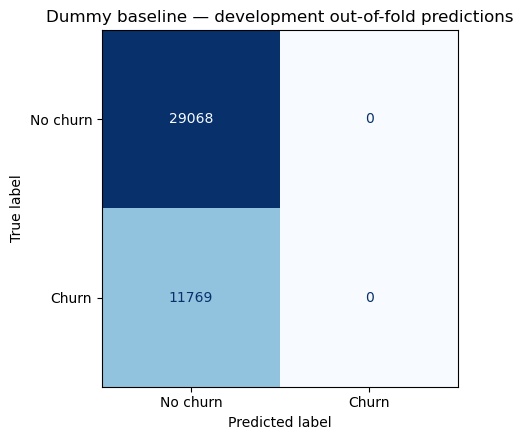

Non-churners correctly predicted: 29,068
Churn customers missed: 11,769


In [81]:
# Confusion matrix from the combined out-of-fold predictions.
baseline_oof_cm = confusion_matrix(
    baseline_oof_predictions["Actual_Churn"],
    baseline_oof_predictions["Predicted_Churn"],
    labels=[0, 1],
)
tn, fp, fn, tp = baseline_oof_cm.ravel()

baseline_error_summary = pd.DataFrame(
    [
        ("True negatives (No churn correctly identified)", int(tn)),
        ("False positives (No churn predicted as churn)", int(fp)),
        ("False negatives (Churn missed)", int(fn)),
        ("True positives (Churn correctly identified)", int(tp)),
    ],
    columns=["Confusion_matrix_component", "Count"],
)
display(baseline_error_summary)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=baseline_oof_cm,
    display_labels=["No churn", "Churn"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Dummy baseline — development out-of-fold predictions")
plt.tight_layout()
plt.show()

print(f"Non-churners correctly predicted: {tn:,}")
print(f"Churn customers missed: {fn:,}")
assert tp == fp == 0
assert tn + fn == len(y_dev)
assert fn == int(y_dev.sum())

The combined out-of-fold predictions classify all **29,068** non-churners correctly and miss all **11,769** churners, with no false positives and no true positives. In every fold, the baseline's Average Precision equals that fold's churn rate (0.2881–0.2882) and its ROC-AUC is exactly 0.50. This confirms that the evaluation code behaves as expected for a model with no skill.

### 7.7 Benchmark Row for Later Comparisons

The baseline's mean metrics are stored as the first row of the model-comparison table, which later sections extend.

In [82]:
# One-row reference that the later model-comparison tables append to.
baseline_comparison_row = pd.DataFrame(
    [
        {
            "Model": "Dummy (prior)",
            "Feature_set": "No feature dependence",
            "CV_folds": N_CV_SPLITS,
            **{
                f"{m}_cv_mean": float(baseline_cv_summary.loc[m, "CV_mean"])
                for m in BASELINE_METRIC_KEYS
            },
            **{
                f"{m}_cv_sd": float(baseline_cv_summary.loc[m, "CV_sd"])
                for m in BASELINE_METRIC_KEYS
            },
        }
    ]
)
comparison_display_cols = ["Model", "Feature_set", "CV_folds"] + [
    f"{m}_cv_mean" for m in BASELINE_METRIC_KEYS
]
display(baseline_comparison_row[comparison_display_cols].round(5))

,Model,Feature_set,CV_folds,average_precision_cv_mean,roc_auc_cv_mean,accuracy_cv_mean,balanced_accuracy_cv_mean,precision_cv_mean,recall_cv_mean,f1_cv_mean,mcc_cv_mean
0,Dummy (prior),No feature dependence,5,0.28819,0.5,0.71181,0.5,0.0,0.0,0.0,0.0


The baseline reaches **71.18% accuracy** but finds **none of the 11,769 churners**: its recall, precision, F1 and MCC are all 0. Its Average Precision is **0.288**, the churn rate itself, and its ROC-AUC is **0.50**. These are the values a model must clearly exceed to show real skill. The accuracy figure confirms that accuracy alone would be a misleading way to compare churn models.